# STEP01. 탐색적 분석 — 고립·은둔 청년의 지원 수요와 복지서비스 데이터

이 노트북은 Q1~Q3 본 분석에 들어가기 전에 **데이터가 무엇을 보여줄 수 있고 무엇을 보여줄 수 없는지**를 확인한다.
전체 구성과 품질에서 출발해 수요, 서비스 영역, 접근 조건, 정보 명시, 검색 입력 순으로 범위를 좁힌다.

| 절 | 확인할 질문 | 연결 |
|---|---|---|
| 0. 데이터 구성과 품질 | 어떤 정보가 어느 출처에서 비어 있고, 라벨은 얼마나 확실한가? | 전체 |
| 1. 지원 필요도와 서비스 영역 | 누가 어떤 지원을 원하며, 서비스 원문에는 어떤 영역 후보가 있는가? | Q1 |
| 2. 접근성과 이용 조건 | 신청·이용에 필요한 외출과 대면 조건은 원문에서 얼마나 확인되는가? | Q1·앱 |
| 3. 정보 명시와 분량 | 필드가 채워져 있다는 것과 정보가 충분하다는 것은 얼마나 다른가? | Q2 |
| 4. 검색에 영향을 주는 특성 | 이름·태그·원문 구조 때문에 검색이 놓칠 수 있는 정보는 무엇인가? | Q3 |
| 5. 핵심 발견 | 무엇이 확인됐고 본 분석에서 무엇을 검증해야 하는가? | Q1~Q3 |

**읽기 전에**
- 서비스 데이터는 SSIS 중앙 461건·지자체 4,827건(STEP 00 마스터)이다. 영역·접근성 값은 원문 규칙으로 만든 **후보**이며, 서비스 수는 공급량·예산·수혜 규모가 아니다.
- 수요 데이터는 2023 고립·은둔 청년 실태조사의 은둔 집단(2024 정의 적용, 19~34세)과 고립 보조집단(19~34세)이다. 비확률·자기선택 표본이므로 **비가중 응답자 비율**로만 읽는다.
- N은 '원문에 근거가 없음'이고 0은 '부담·관련성이 없다고 확인됨'이다. 둘을 섞지 않는다.

In [1]:
import os, sys, re, textwrap
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display, Markdown, Image
from src.preprocess import keywords as K

# ---- 공통 스타일 --------------------------------------------------------------
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "font.family": ([f for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans KR"] if f in _fonts][:1] or ["sans-serif"]),
    "axes.unicode_minus": False, "figure.dpi": 100, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#a3a29d",
    "axes.labelcolor": "#3f3e3b", "xtick.color": "#3f3e3b", "ytick.color": "#3f3e3b",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9,
})
INK, INK2, MUTED = "#1f1f1d", "#52514e", "#8a8984"
C_SRC = {"central": "#2a78d6", "local": "#eb6834", "gov24": "#1baf7a"}
SRC_KO = {"central": "SSIS 중앙", "local": "SSIS 지자체", "gov24": "보조금24"}
N_COLOR, NA_COLOR = "#c9ced6", "#ecebe7"
LEVEL4 = ["#cfe0f6", "#86b4ec", "#3a86df", "#1d4f91"]          # 0~3 단계: 진할수록 값이 큼
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#86b4ec", "#1d4f91"])
DIVERGE = LinearSegmentedColormap.from_list("div", ["#c2551f", "#f6d2bd", "#f7f7f5", "#bcd6f5", "#1d4f91"])
Q10 = [f"q21_{i:02d}" for i in range(1, 11)]
Q11 = Q10 + ["q21_11"]
CIRC = "①②③④⑤⑥⑦⑧⑨⑩⑪"
SHORT = {"q21_01": "머물 수 있는 공간", "q21_02": "일상생활 회복", "q21_03": "혼자 하는 취미·문화·체육", "q21_04": "같이 하는 취미·문화·체육",
         "q21_05": "전문가 상담·치료", "q21_06": "또래·멘토 상담·지지", "q21_07": "교육·학습", "q21_08": "취업(정보)·일 경험",
         "q21_09": "공동생활", "q21_10": "경제적 지원", "q21_11": "주거(조사 문항 없음)"}
AREA = {q: f"{CIRC[i]} {SHORT[q]}" for i, q in enumerate(Q11)}

OUT = ROOT / "outputs/01_eda"; TBL, FIG = OUT / "tables", OUT / "figures"
TBL.mkdir(parents=True, exist_ok=True)
FIG_NO = {"n": 0}


def save_csv(df, name):
    """상세 결과 원본은 CSV로 남긴다(노트북에는 핵심 표만 표시)."""
    df.to_csv(TBL / f"{name}.csv", index=False, encoding="utf-8-sig")
    return df


def show_fig(fig, folder, name, note):
    """그림 번호를 붙이고 하단에 분모·집계 기준을 적어 PNG로 저장한 뒤 표시한다."""
    FIG_NO["n"] += 1
    n = FIG_NO["n"]
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    y0 = bb.y0 / fig.get_figheight() - 0.03
    fig.text(bb.x0 / fig.get_figwidth(), y0, textwrap.fill(note, 120), ha="left", va="top", fontsize=8.5, color=MUTED, transform=fig.transFigure)
    path = FIG / folder / f"{n:02d}_{name}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches="tight", facecolor="white", pad_inches=0.25)
    plt.close(fig)
    display(Image(filename=str(path), width=980))
    return n


def show_table(df, title, fmt=None, note=None, highlight=None, bar=None):
    """읽기용 표: 한국어 열 이름, 자리수 서식, 강조 열. 원본 수치는 CSV에 따로 저장한다."""
    st = df.style.hide(axis="index").format(fmt or {}, na_rep="—")
    st = st.set_table_styles([{"selector": "th", "props": "background:#f3f2ee;color:#1f1f1d;font-weight:600;text-align:center;padding:4px 8px"},
                              {"selector": "td", "props": "padding:3px 8px"}])
    for col in (highlight or []):
        st = st.background_gradient(cmap=BLUES, subset=[col], vmin=0)
    for col in (bar or []):
        st = st.bar(subset=[col], color="#bcd6f5", vmin=0)
    display(Markdown(f"**{title}**"))
    display(st)
    if note:
        display(Markdown(f"<span style='color:#8a8984;font-size:90%'>{note}</span>"))


def pct(a, b):
    return 100 * a / b if b else np.nan


def area_has(series, q):
    return series.fillna("N").str.split("|").map(lambda v: q in v)

In [2]:
P = ROOT / "data/processed"
m = pd.read_csv(P / "services_master.csv", dtype=str, encoding="utf-8-sig", keep_default_na=False, na_values=[""])
demand = pd.read_csv(P / "demand_2023_hikikomori.csv", dtype=str, encoding="utf-8-sig")
aux = pd.read_csv(P / "demand_2023_isolated_aux.csv", dtype=str, encoding="utf-8-sig")
gov_path = P / "gov24_merged.csv"
gov = pd.read_csv(gov_path, dtype=str, encoding="utf-8-sig", keep_default_na=False, na_values=[""]) if gov_path.exists() else None

# 원본 마스터는 읽기만 한다. EDA용 파생값은 별도 프레임(e)에 만든다.
assert len(m) == 5288 and m.servId.is_unique and m.shape[1] == 153   # v3: 128 + 14(2026-11-04) + 4(외출 환산) + 5(⑩ v4) + 2(⑦ 수혜자)
assert m.source.value_counts().to_dict() == {"local": 4827, "central": 461}
assert len(demand) == 4448 and len(aux) == 3032
e = m[["servId", "source"]].copy()
for c in ["youth_tag", "youth_text"]:
    e[c] = m[c].eq("True")
e["youth_age"] = m.youth_age.map({"True": "겹침", "False": "불일치"}).fillna("미상")
N_SRC = m.source.value_counts().to_dict()
print(f"services_master {m.shape} | 중앙 {N_SRC['central']:,} · 지자체 {N_SRC['local']:,} | 은둔 {len(demand):,} · 고립 보조 {len(aux):,} | "
      f"보조금24 {'%s건' % format(len(gov), ',') if gov is not None else '없음(Q2 비교 생략)'}")

services_master (5288, 153) | 중앙 461 · 지자체 4,827 | 은둔 4,448 · 고립 보조 3,032 | 보조금24 10,942건


# 0. 분석 데이터의 구성과 품질

먼저 분석에 쓰는 자료의 단위와 범위를 정리한다. 서비스 자료와 조사 자료는 단위가 달라(서비스 1건 vs 응답자 1명) 서로 나누거나 같은 축에서 비교하지 않는다.

In [3]:
data_overview = pd.DataFrame([
    {"자료": "SSIS 중앙부처 복지서비스", "단위": "서비스", "건수": N_SRC["central"], "기준": "2026-10-30 수집", "이 노트북에서의 역할": "영역·접근성 후보, 정보 명시"},
    {"자료": "SSIS 지자체 복지서비스", "단위": "서비스", "건수": N_SRC["local"], "기준": "2026-10-30 수집", "이 노트북에서의 역할": "영역·접근성 후보, 정보 명시, 이름 반복"},
    {"자료": "보조금24 공공서비스", "단위": "서비스", "건수": len(gov) if gov is not None else np.nan, "기준": "2026-10-31 수집", "이 노트북에서의 역할": "Q2 정보 명시 비교(수록 범위 다름)"},
    {"자료": "2023 실태조사 은둔 집단", "단위": "응답자", "건수": len(demand), "기준": "2024 정의, 19~34세, 비가중", "이 노트북에서의 역할": "지원 필요도(주 분석)"},
    {"자료": "2023 실태조사 고립 보조집단", "단위": "응답자", "건수": len(aux), "기준": "19~34세, 은둔 기준 미적용, 비가중", "이 노트북에서의 역할": "지원 필요도(보조 비교)"},
])
show_table(data_overview, "표 0-1. 분석 데이터 구성", fmt={"건수": "{:,.0f}"},
           note="서비스 건수는 공급 규모가 아니고, 응답자 비율은 전국 청년의 대표값이 아니다.")

**표 0-1. 분석 데이터 구성**

자료,단위,건수,기준,이 노트북에서의 역할
SSIS 중앙부처 복지서비스,서비스,461,2026-10-30 수집,"영역·접근성 후보, 정보 명시"
SSIS 지자체 복지서비스,서비스,"4,827",2026-10-30 수집,"영역·접근성 후보, 정보 명시, 이름 반복"
보조금24 공공서비스,서비스,"10,942",2026-10-31 수집,Q2 정보 명시 비교(수록 범위 다름)
2023 실태조사 은둔 집단,응답자,"4,448","2024 정의, 19~34세, 비가중",지원 필요도(주 분석)
2023 실태조사 고립 보조집단,응답자,"3,032","19~34세, 은둔 기준 미적용, 비가중",지원 필요도(보조 비교)


<span style='color:#8a8984;font-size:90%'>서비스 건수는 공급 규모가 아니고, 응답자 비율은 전국 청년의 대표값이 아니다.</span>

## 0-1. 어떤 정보가 어느 출처에서 비어 있는가?

후속 분석에 쓰는 필드를 출처별로 놓고 값이 있는 비율을 한 장에서 비교한다. 결측률을 따로 나열하면 '어느 분석이 어느 출처에서 약해지는지'가 보이지 않기 때문이다.

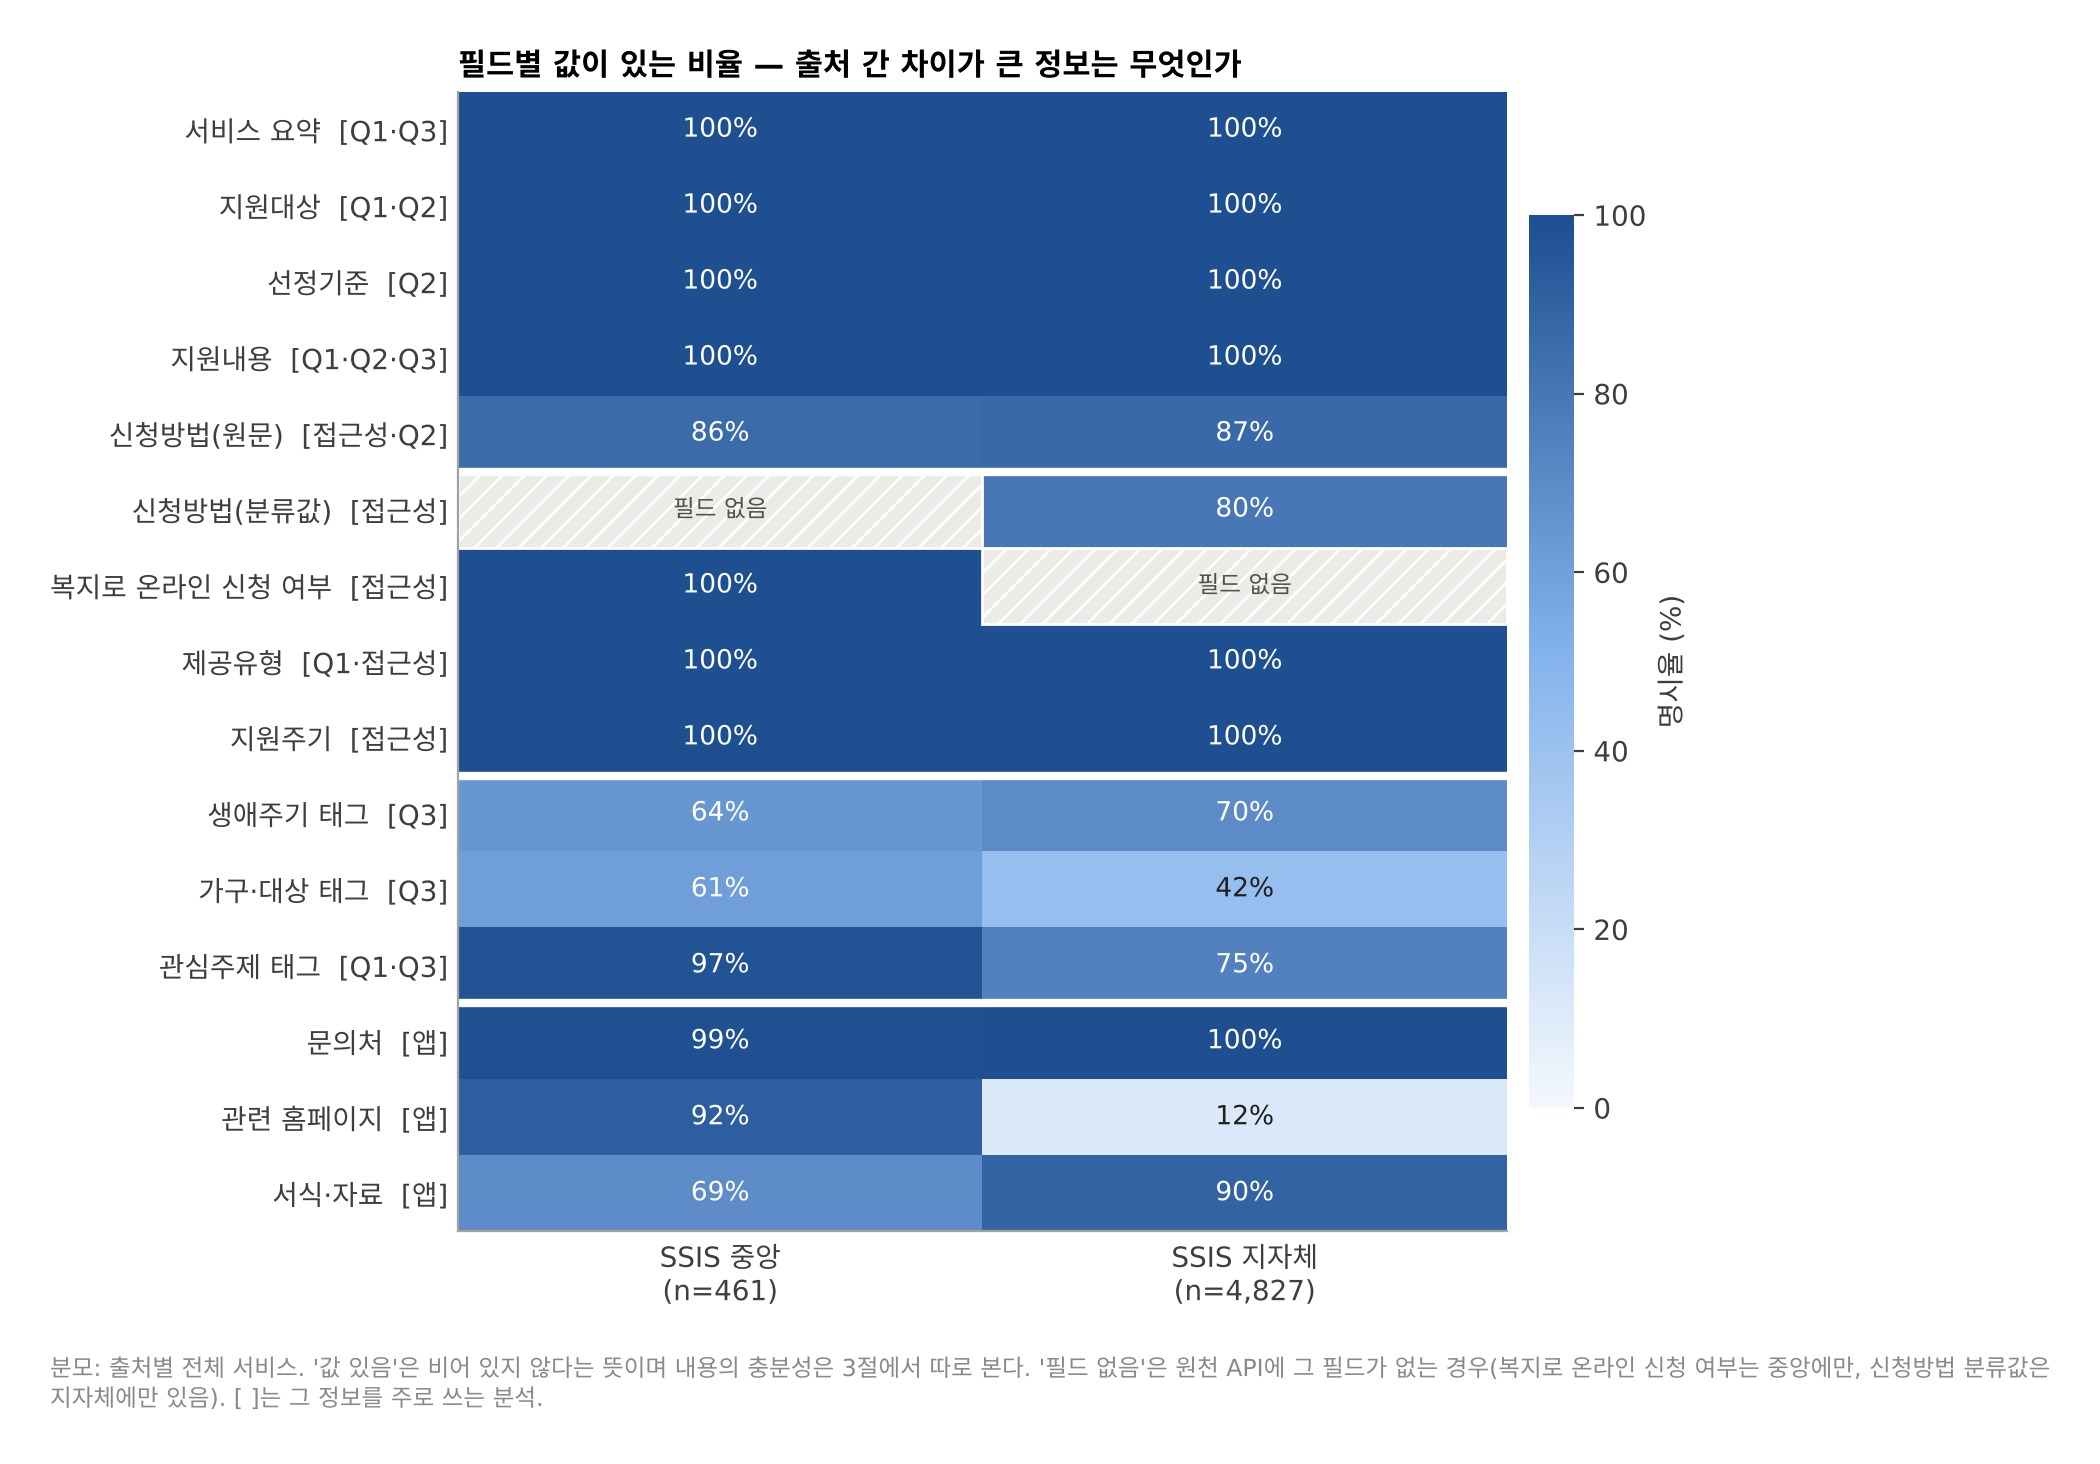

In [4]:
def nonempty(s):
    return s.fillna("").astype(str).str.strip().ne("")

def json_has(s):
    return s.fillna("[]").ne("[]")

FIELDS = [  # (표시명, 컬럼, 쓰이는 곳)
    ("서비스 요약", "summary_text", "Q1·Q3"), ("지원대상", "target_text", "Q1·Q2"), ("선정기준", "criteria_text", "Q2"),
    ("지원내용", "benefit_text", "Q1·Q2·Q3"), ("신청방법(원문)", "apply_text", "접근성·Q2"), ("신청방법(분류값)", "apply_cat", "접근성"),
    ("복지로 온라인 신청 여부", "online_bokjiro", "접근성"), ("제공유형", "provision_type", "Q1·접근성"), ("지원주기", "support_cycle", "접근성"),
    ("생애주기 태그", "life_tags", "Q3"), ("가구·대상 태그", "target_tags", "Q3"), ("관심주제 태그", "theme_tags", "Q1·Q3"),
    ("문의처", "contact_json", "앱"), ("관련 홈페이지", "homepage_json", "앱"), ("서식·자료", "form_json", "앱"),
]
NO_FIELD = {("복지로 온라인 신청 여부", "local"), ("신청방법(분류값)", "central")}   # 원천 API에 없는 필드
rows = []
for label, col, use in FIELDS:
    present = json_has(m[col]) if col.endswith("_json") else nonempty(m[col])
    for s in ["central", "local"]:
        sel = m.source.eq(s)
        nof = (label, s) in NO_FIELD
        rows.append({"필드": label, "쓰이는 곳": use, "출처": SRC_KO[s], "값 있음": int((present & sel).sum()), "분모": int(sel.sum()),
                     "명시율(%)": np.nan if nof else pct((present & sel).sum(), sel.sum()), "비고": "원천에 필드 없음" if nof else ""})
field_presence = save_csv(pd.DataFrame(rows), "s0_field_presence")
mat = field_presence.pivot(index="필드", columns="출처", values="명시율(%)").loc[[f[0] for f in FIELDS], [SRC_KO["central"], SRC_KO["local"]]]
uses = [f[2] for f in FIELDS]

fig, ax = plt.subplots(figsize=(7.2, 7.4))
im = ax.imshow(np.ma.masked_invalid(mat.to_numpy(dtype=float)), cmap=BLUES, vmin=0, vmax=100, aspect="auto")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.iloc[i, j]
        if pd.isna(v):
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, facecolor=NA_COLOR, hatch="///", edgecolor="white"))
            ax.text(j, i, "필드 없음", ha="center", va="center", fontsize=8.5, color=INK2)
        else:
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9.5, color="white" if v > 60 else INK)
ax.set_xticks(range(2), [f"{c}\n(n={N_SRC[k]:,})" for c, k in zip(mat.columns, ["central", "local"])])
ax.set_yticks(range(len(mat)), [f"{r}  [{u}]" for r, u in zip(mat.index, uses)])
ax.tick_params(length=0); ax.grid(False)
for i in [4.5, 8.5, 11.5]:
    ax.axhline(i, color="white", lw=3)
ax.set_title("필드별 값이 있는 비율 — 출처 간 차이가 큰 정보는 무엇인가")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("명시율 (%)"); cb.outline.set_visible(False)
f = show_fig(fig, "eda", "field_presence", "분모: 출처별 전체 서비스. '값 있음'은 비어 있지 않다는 뜻이며 내용의 충분성은 3절에서 따로 본다. "
             "'필드 없음'은 원천 API에 그 필드가 없는 경우(복지로 온라인 신청 여부는 중앙에만, 신청방법 분류값은 지자체에만 있음). [ ]는 그 정보를 주로 쓰는 분석.")

In [5]:
gap = (mat[SRC_KO["central"]] - mat[SRC_KO["local"]]).abs().dropna().sort_values(ascending=False)
low_local = mat[SRC_KO["local"]].dropna().sort_values().head(3)
display(Markdown(f"""**발견.** 핵심 원문(요약·지원대상·선정기준·지원내용)은 두 출처 모두 100%에 가깝지만, 구조화 필드와 태그는 출처마다 비는 곳이 다르다.
원천에 필드가 없는 경우를 빼면, 지자체에서 가장 많이 비는 필드는 {', '.join(f'{k}({v:.0f}%)' for k, v in low_local.items())}이고, 출처 간 차이가 가장 큰 필드는 '{gap.index[0]}'({gap.iloc[0]:.0f}%p)이다.

**왜 중요한가.** 태그나 분류값만으로 서비스를 거르면 지자체 서비스가 체계적으로 빠진다. 그래서 Q1 영역과 청년 대상 판단은 원문을 기준으로 하고 태그는 참고로만 쓴다.
신청 경로는 중앙은 복지로 신청 여부, 지자체는 신청방법 분류값에 기대므로 두 출처의 신청 장벽은 같은 근거에서 나온 값이 아니다."""))

**발견.** 핵심 원문(요약·지원대상·선정기준·지원내용)은 두 출처 모두 100%에 가깝지만, 구조화 필드와 태그는 출처마다 비는 곳이 다르다.
원천에 필드가 없는 경우를 빼면, 지자체에서 가장 많이 비는 필드는 관련 홈페이지(12%), 가구·대상 태그(42%), 생애주기 태그(70%)이고, 출처 간 차이가 가장 큰 필드는 '관련 홈페이지'(80%p)이다.

**왜 중요한가.** 태그나 분류값만으로 서비스를 거르면 지자체 서비스가 체계적으로 빠진다. 그래서 Q1 영역과 청년 대상 판단은 원문을 기준으로 하고 태그는 참고로만 쓴다.
신청 경로는 중앙은 복지로 신청 여부, 지자체는 신청방법 분류값에 기대므로 두 출처의 신청 장벽은 같은 근거에서 나온 값이 아니다.

## 0-2. 핵심 라벨은 얼마나 확실한가?

STEP 00 라벨은 구조화 필드, 원문 규칙, 근거 없음(N)이 섞여 있다. 같은 '값'이라도 확실성이 다르므로 라벨별로 출처와 검수 필요 여부를 함께 본다.

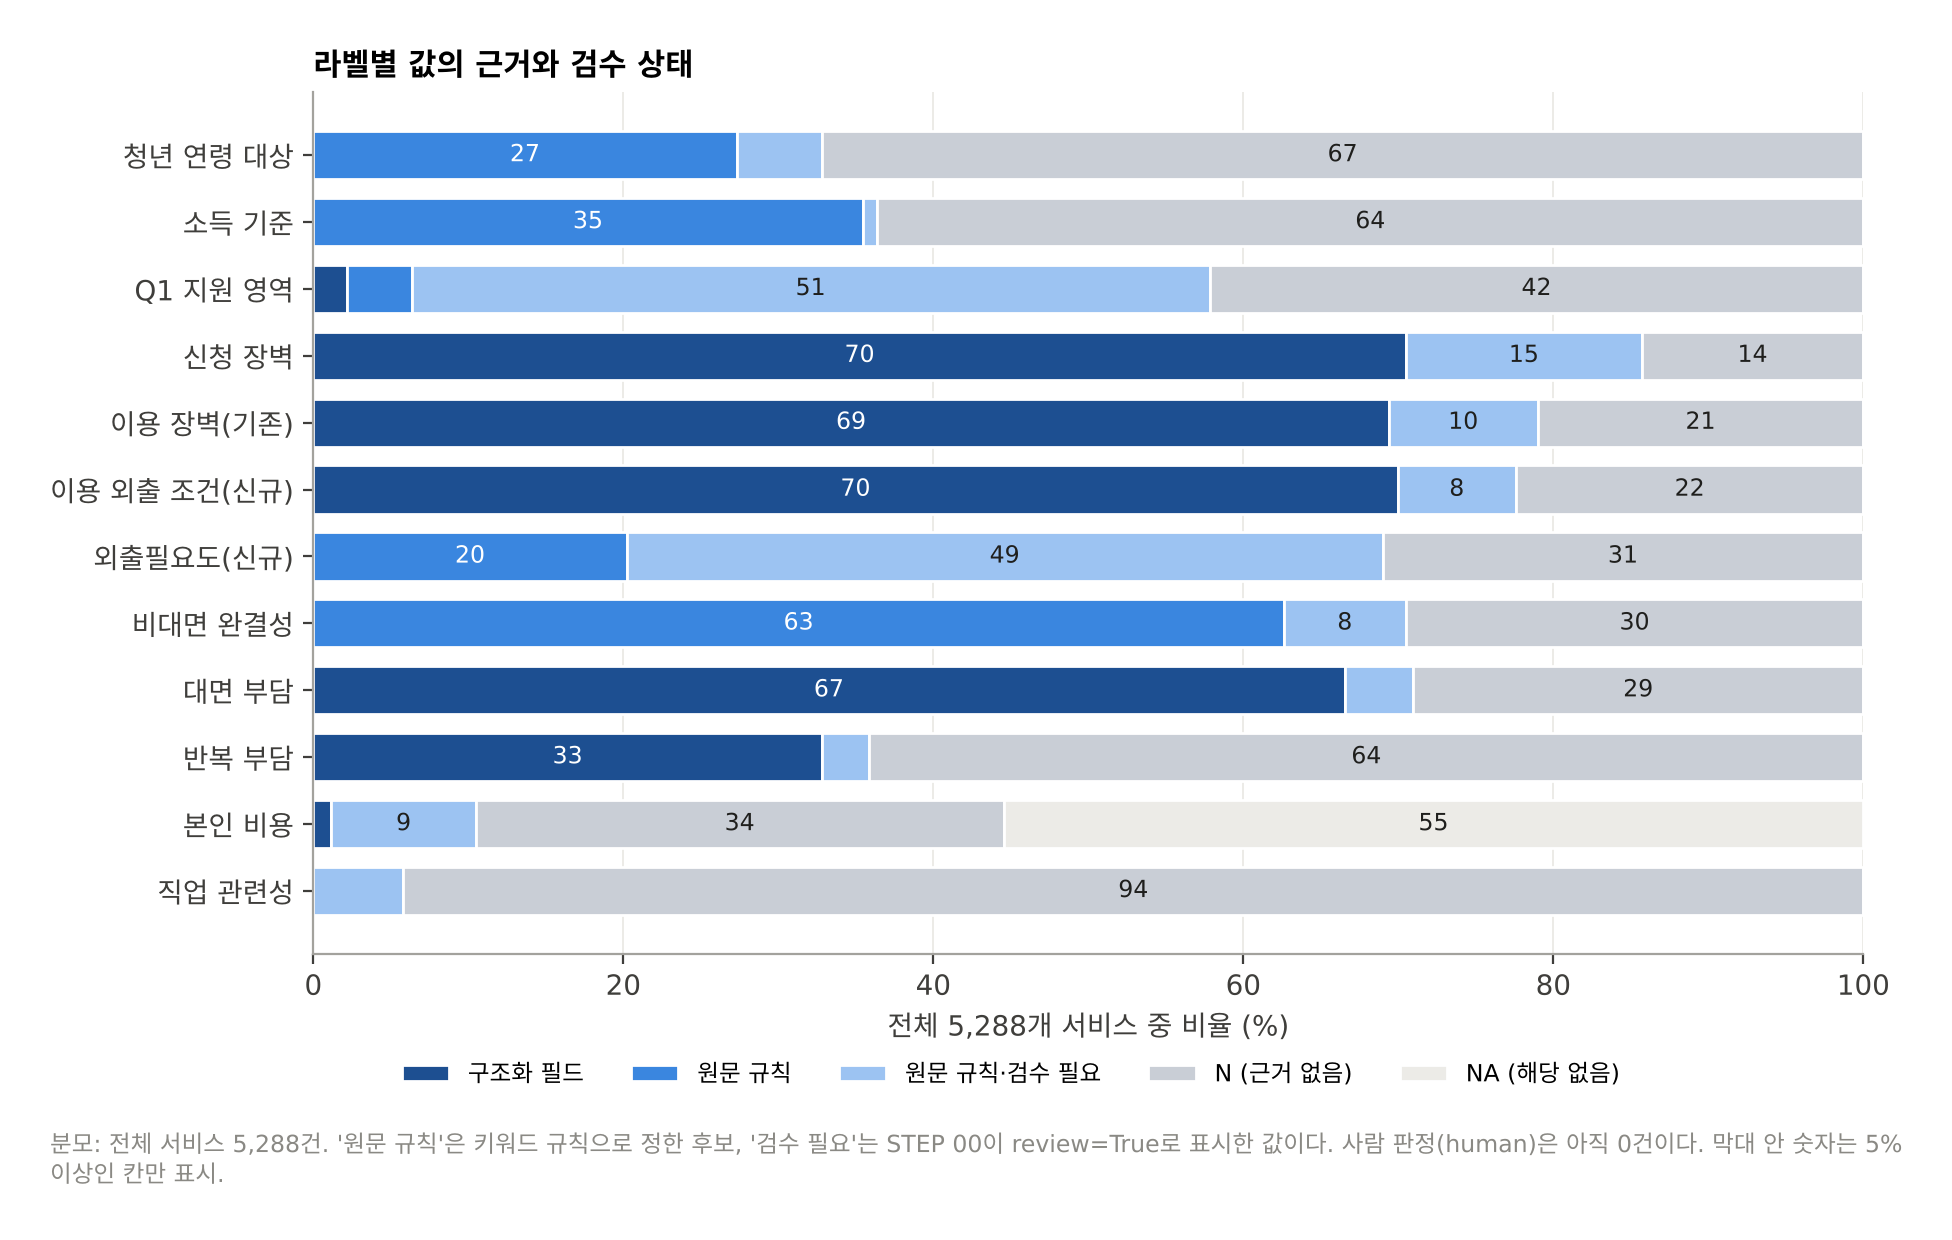

In [6]:
LABELS = [("elig_youth", "청년 연령 대상"), ("elig_income", "소득 기준"), ("need_area_q21", "Q1 지원 영역"), ("apply_barrier", "신청 장벽"),
          ("use_barrier", "이용 장벽(기존)"), ("use_outing", "이용 외출 조건(신규)"), ("outing_need", "외출필요도(신규)"),
          ("remote_complete", "비대면 완결성"), ("contact_burden", "대면 부담"), ("repeat_burden", "반복 부담"), ("cost", "본인 비용"),
          ("job_relevance", "직업 관련성")]
STATUS = ["구조화 필드", "원문 규칙", "원문 규칙·검수 필요", "N (근거 없음)", "NA (해당 없음)"]
ST_COL = ["#1d4f91", "#3a86df", "#9cc3f2", N_COLOR, NA_COLOR]

def label_status(attr):
    v, meth, rev = m[attr].fillna("N"), m[f"{attr}_method"].fillna(""), m[f"{attr}_review"].eq("True")
    out = np.where(v.eq("NA"), STATUS[4], np.where(v.eq("N"), STATUS[3],
          np.where(meth.eq("field"), STATUS[0], np.where(rev, STATUS[2], STATUS[1]))))
    return pd.Series(out, index=m.index)

rows = []
for attr, ko in LABELS:
    st = label_status(attr)
    for s in STATUS:
        rows.append({"라벨": ko, "컬럼": attr, "상태": s, "건수": int(st.eq(s).sum()), "비율(%)": pct(st.eq(s).sum(), len(m))})
label_state = save_csv(pd.DataFrame(rows), "s0_label_status")
pv = label_state.pivot(index="라벨", columns="상태", values="비율(%)").loc[[ko for _, ko in LABELS], STATUS]

fig, ax = plt.subplots(figsize=(10, 5.6))
left = np.zeros(len(pv))
for s, col in zip(STATUS, ST_COL):
    ax.barh(range(len(pv)), pv[s], left=left, color=col, edgecolor="white", height=0.72, label=s)
    for i, (l, v) in enumerate(zip(left, pv[s])):
        if v >= 7:
            ax.text(l + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if col in ST_COL[:2] else INK)
    left += pv[s].to_numpy()
ax.set_yticks(range(len(pv)), pv.index); ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("전체 5,288개 서비스 중 비율 (%)")
ax.set_title("라벨별 값의 근거와 검수 상태")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.1), fontsize=8.5)
f = show_fig(fig, "eda", "label_status", "분모: 전체 서비스 5,288건. '원문 규칙'은 키워드 규칙으로 정한 후보, '검수 필요'는 STEP 00이 review=True로 표시한 값이다. "
             "사람 판정(human)은 아직 0건이다. 막대 안 숫자는 5% 이상인 칸만 표시.")

In [7]:
summ = label_state.pivot(index="라벨", columns="상태", values="건수").loc[[ko for _, ko in LABELS], STATUS].reset_index()
summ["N 비율(%)"] = 100 * summ["N (근거 없음)"] / len(m)
summ["규칙 값 중 검수 필요(%)"] = 100 * summ["원문 규칙·검수 필요"] / (summ["원문 규칙"] + summ["원문 규칙·검수 필요"]).replace(0, np.nan)
show_table(summ, "표 0-2. 라벨별 근거 구성 (건수)", fmt={c: "{:,.0f}" for c in STATUS} | {"N 비율(%)": "{:.1f}", "규칙 값 중 검수 필요(%)": "{:.1f}"},
           highlight=["N 비율(%)"], note="정렬: 서비스 판단 순서(대상 → 영역 → 접근성 → 추천 요소). N 비율이 높을수록 원문으로 값을 정하기 어렵다.")
hi = summ.sort_values("N 비율(%)", ascending=False).head(3)
display(Markdown(f"""**발견.** N 비율이 가장 높은 라벨은 {', '.join(f"{r['라벨']}({r['N 비율(%)']:.0f}%)" for _, r in hi.iterrows())}이다.
반대로 신청 장벽·이용 장벽·대면 부담은 제공유형·신청 분류 같은 구조화 필드 비중이 커서 값은 많이 채워져 있다. 다만 현금형 서비스에 0이 몰려 있다는 점을 함께 봐야 한다(2절).

**왜 중요한가.** 값이 채워진 비율과 값의 확실성은 다르다. Q1·추천에서는 구조화 필드 값과 규칙 후보를 구분해 쓰고, N은 '없음'이 아니라 '확인 불가'로 다룬다. 사람 검증은 STEP 02 표본에서 한다."""))

**표 0-2. 라벨별 근거 구성 (건수)**

라벨,구조화 필드,원문 규칙,원문 규칙·검수 필요,N (근거 없음),NA (해당 없음),N 비율(%),규칙 값 중 검수 필요(%)
청년 연령 대상,0,"1,444",291,"3,553",0,67.2,16.8
소득 기준,0,"1,874",50,"3,364",0,63.6,2.6
Q1 지원 영역,116,219,"2,723","2,230",0,42.2,92.6
신청 장벽,"3,727",1,804,756,0,14.3,99.9
이용 장벽(기존),"3,669",0,508,"1,111",0,21.0,100.0
이용 외출 조건(신규),"3,699",0,404,"1,185",0,22.4,100.0
외출필요도(신규),0,"1,069","2,579","1,640",0,31.0,70.7
비대면 완결성,0,"3,311",416,"1,561",0,29.5,11.2
대면 부담,"3,518",0,234,"1,536",0,29.0,100.0
반복 부담,"1,735",0,162,"3,391",0,64.1,100.0


<span style='color:#8a8984;font-size:90%'>정렬: 서비스 판단 순서(대상 → 영역 → 접근성 → 추천 요소). N 비율이 높을수록 원문으로 값을 정하기 어렵다.</span>

**발견.** N 비율이 가장 높은 라벨은 직업 관련성(94%), 청년 연령 대상(67%), 반복 부담(64%)이다.
반대로 신청 장벽·이용 장벽·대면 부담은 제공유형·신청 분류 같은 구조화 필드 비중이 커서 값은 많이 채워져 있다. 다만 현금형 서비스에 0이 몰려 있다는 점을 함께 봐야 한다(2절).

**왜 중요한가.** 값이 채워진 비율과 값의 확실성은 다르다. Q1·추천에서는 구조화 필드 값과 규칙 후보를 구분해 쓰고, N은 '없음'이 아니라 '확인 불가'로 다룬다. 사람 검증은 STEP 02 표본에서 한다.

## 0-3. 관심주제 태그는 서비스 내용을 대표하는가?

지자체 관심주제 태그에 '서민금융'이 몰려 있다는 점은 STEP 00에서 확인했다. 두 출처의 주제 구성을 나란히 놓아 편중이 지자체에서만 나타나는지 본다.

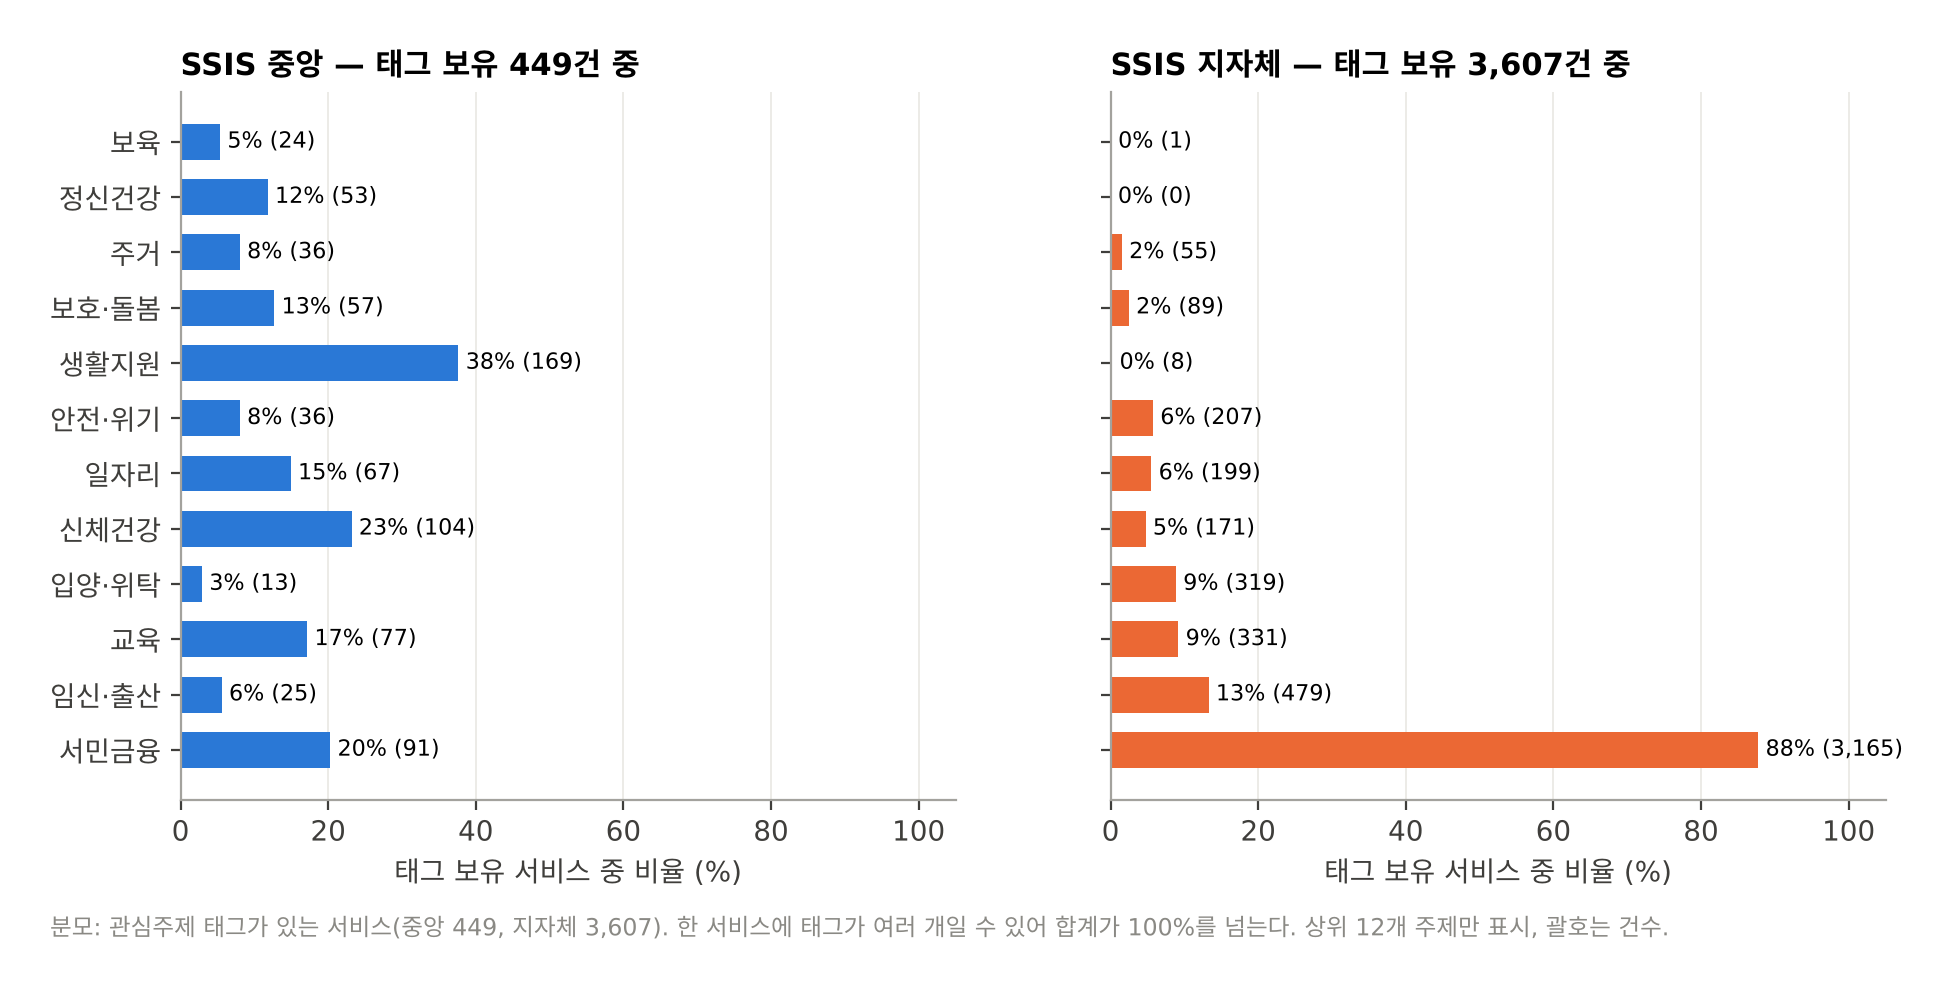

**발견.** 중앙은 주제가 고르게 퍼져 있지만, 지자체는 태그 보유 서비스의 88%(3,165/3,607건)가 '서민금융'이다.
그중 86%는 제공유형에 현금지급이 있어, 금융상품이 아니라 현금성 지원 전반에 같은 태그가 붙었을 가능성이 있다.

**왜 중요한가.** 지자체 태그로 주제를 고르면 대부분이 '서민금융'에 묶여 Q1 영역 구분이 무너진다. Q1은 원문 기반 영역 후보를 쓴다.
**단정할 수 없는 것.** 태그가 왜 이렇게 붙었는지(원천 코드 매핑 등)는 이 자료로 확인할 수 없다.

In [8]:
theme = m[["source", "theme_tags"]].dropna().assign(t=lambda x: x.theme_tags.str.split(", ")).explode("t")
den = m.dropna(subset=["theme_tags"]).source.value_counts()
td = theme.groupby(["source", "t"]).size().rename("건수").reset_index()
td["비율(%)"] = 100 * td["건수"] / td.source.map(den)
save_csv(td, "s0_theme_tag_distribution")
top = td.groupby("t")["건수"].sum().sort_values(ascending=False).head(12).index
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, s in zip(axes, ["central", "local"]):
    d = td[td.source.eq(s)].set_index("t").reindex(top).fillna(0)
    ax.barh(range(len(top)), d["비율(%)"], color=C_SRC[s], height=0.65)
    for i, (p, n) in enumerate(zip(d["비율(%)"], d["건수"])):
        ax.text(p + 1, i, f"{p:.0f}% ({int(n):,})", va="center", fontsize=8)
    ax.set_yticks(range(len(top)), top); ax.invert_yaxis(); ax.set_xlim(0, 105); ax.grid(axis="y", visible=False)
    ax.set_title(f"{SRC_KO[s]} — 태그 보유 {den[s]:,}건 중")
    ax.set_xlabel("태그 보유 서비스 중 비율 (%)")
loc_tag = m[m.source.eq("local") & m.theme_tags.notna()]
seomin = loc_tag[loc_tag.theme_tags.str.contains("서민금융")]
cash = seomin.provision_type.fillna("").str.contains("현금지급").mean() * 100
f = show_fig(fig, "eda", "theme_concentration", f"분모: 관심주제 태그가 있는 서비스(중앙 {den['central']:,}, 지자체 {den['local']:,}). 한 서비스에 태그가 여러 개일 수 있어 합계가 100%를 넘는다. "
             "상위 12개 주제만 표시, 괄호는 건수.")
display(Markdown(f"""**발견.** 중앙은 주제가 고르게 퍼져 있지만, 지자체는 태그 보유 서비스의 {100*len(seomin)/len(loc_tag):.0f}%({len(seomin):,}/{len(loc_tag):,}건)가 '서민금융'이다.
그중 {cash:.0f}%는 제공유형에 현금지급이 있어, 금융상품이 아니라 현금성 지원 전반에 같은 태그가 붙었을 가능성이 있다.

**왜 중요한가.** 지자체 태그로 주제를 고르면 대부분이 '서민금융'에 묶여 Q1 영역 구분이 무너진다. Q1은 원문 기반 영역 후보를 쓴다.
**단정할 수 없는 것.** 태그가 왜 이렇게 붙었는지(원천 코드 매핑 등)는 이 자료로 확인할 수 없다."""))

# 1. Q1 준비 — 지원 필요도와 서비스 영역

수요(조사 응답)와 공급 후보(서비스 원문)를 따로 살핀다. 두 쪽은 단위가 다르므로 이 절에서는 서로 나누거나 공백률을 계산하지 않는다. 대응 분석은 Q1 본 분석에서 한다.

## 1-1. 은둔 청년은 어떤 지원을 얼마나 원하는가?

10개 영역의 4점 응답 분포를 한 축에 놓는다. '매우 필요' 비율만 보면 '약간 필요'까지 포함한 지지의 폭과 반대 응답의 크기를 놓치기 때문이다.

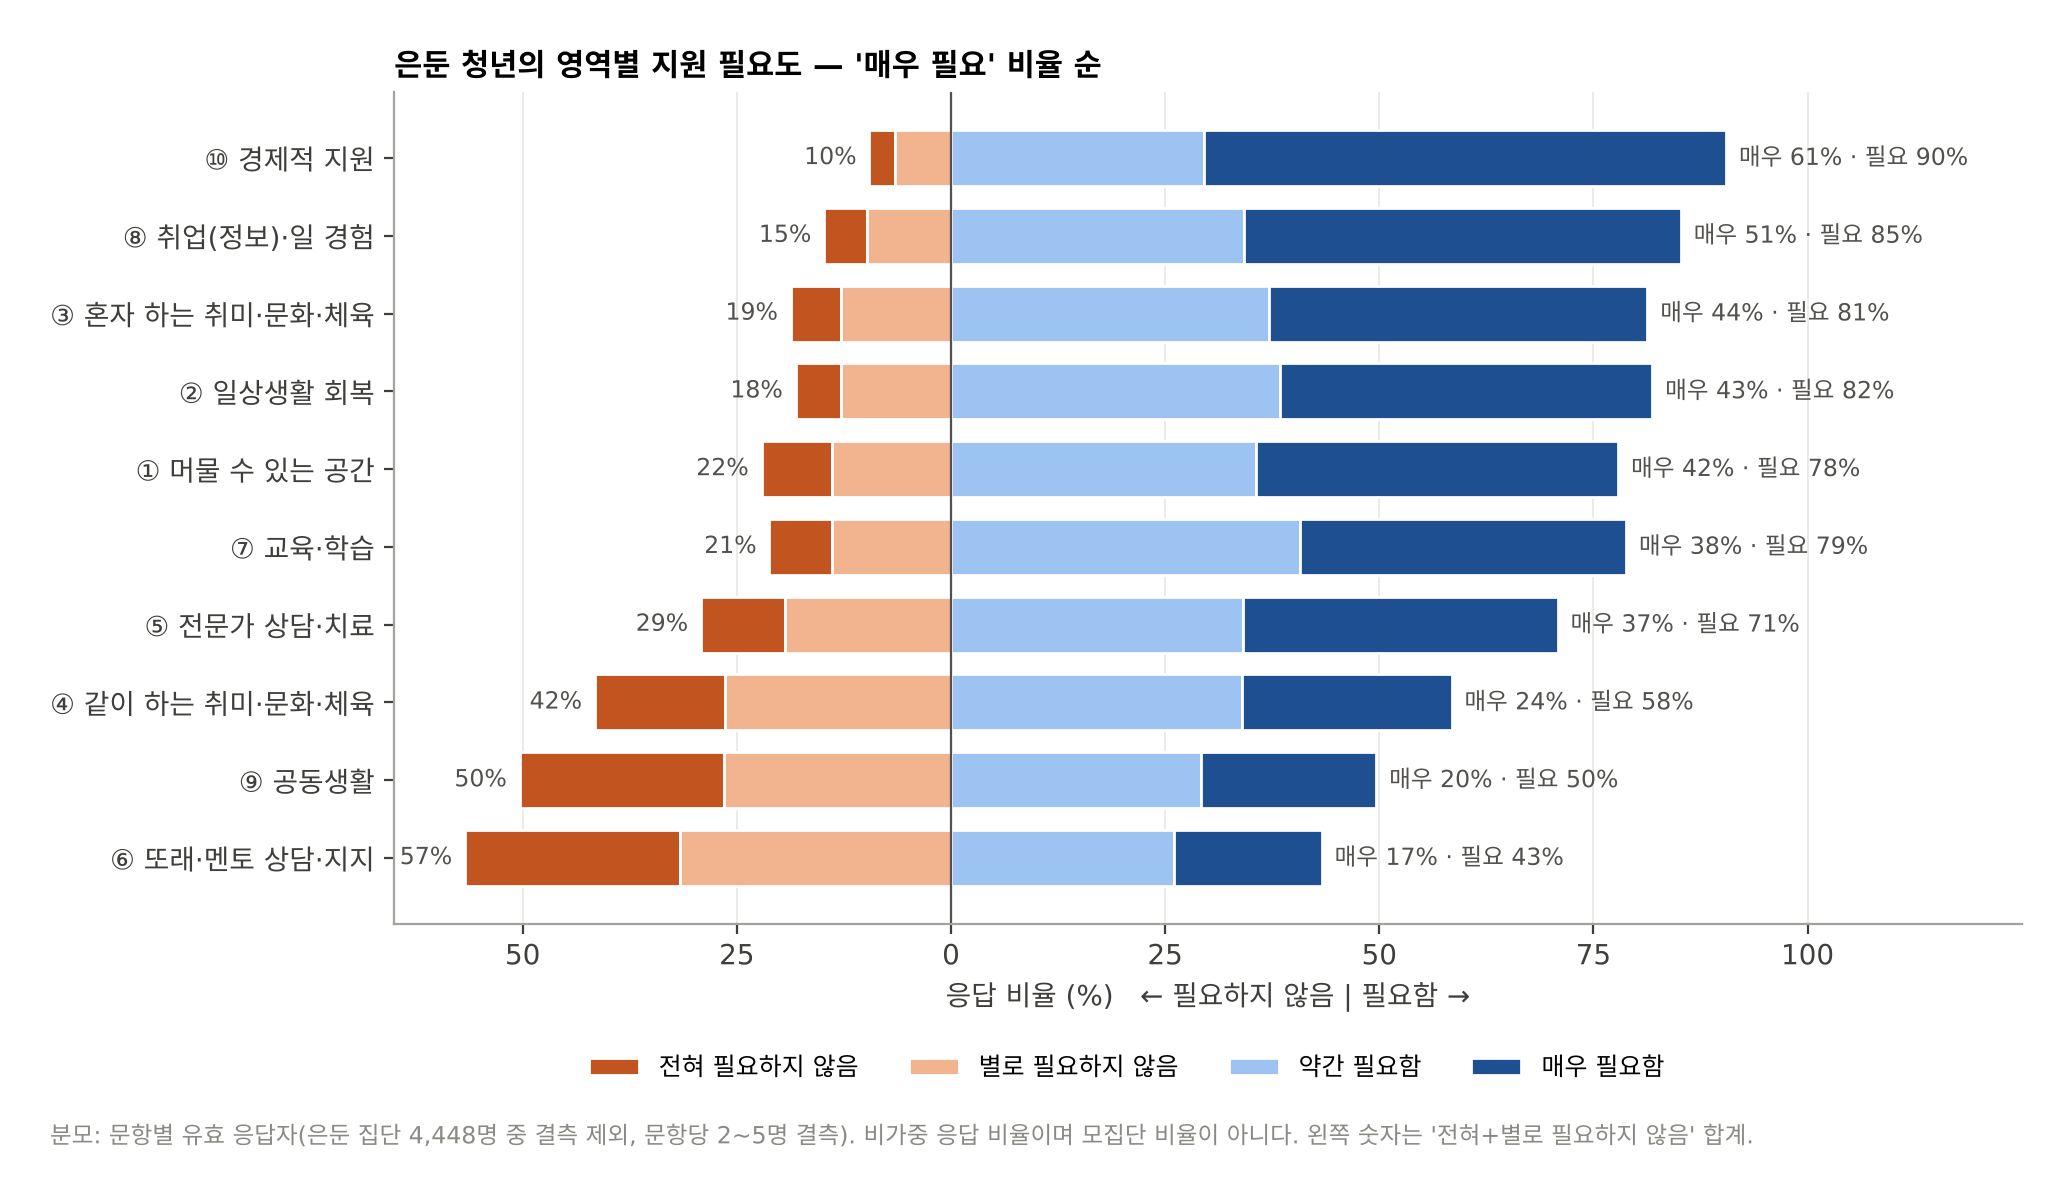

In [9]:
LIK = {"1": "전혀 필요하지 않음", "2": "별로 필요하지 않음", "3": "약간 필요함", "4": "매우 필요함"}
LIK_COL = {"1": "#c2551f", "2": "#f2b38f", "3": "#9cc3f2", "4": "#1d4f91"}

def likert(df, group):
    rows = []
    for q in Q10:
        v = df[q].dropna()
        assert v.isin(list(LIK)).all()
        cnt = v.value_counts()
        rows.append({"집단": group, "영역코드": q, "영역": AREA[q], "유효응답": len(v), **{f"p{k}": pct(cnt.get(k, 0), len(v)) for k in LIK}})
    t = pd.DataFrame(rows); t["필요(3+4)"] = t.p3 + t.p4
    return t

lik = pd.concat([likert(demand, "은둔"), likert(aux, "고립 보조")], ignore_index=True)
save_csv(lik, "s1_demand_likert")
h = lik[lik["집단"].eq("은둔")].sort_values("p4")

fig, ax = plt.subplots(figsize=(10.5, 5.4))
y = np.arange(len(h))
starts = {"1": -(h.p1 + h.p2), "2": -h.p2, "3": np.zeros(len(h)), "4": h.p3}
for k in LIK:
    ax.barh(y, h[f"p{k}"], left=starts[k], color=LIK_COL[k], edgecolor="white", height=0.72, label=LIK[k])
for yi, (p4, need, neg) in enumerate(zip(h.p4, h["필요(3+4)"], h.p1 + h.p2)):
    ax.text(need + 1.5, yi, f"매우 {p4:.0f}% · 필요 {need:.0f}%", va="center", fontsize=8.5, color=INK2)
    ax.text(-neg - 1.5, yi, f"{neg:.0f}%", va="center", ha="right", fontsize=8.5, color=INK2)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(y, h["영역"]); ax.set_xlim(-65, 125); ax.grid(axis="y", visible=False)
ax.set_xticks([-50, -25, 0, 25, 50, 75, 100], ["50", "25", "0", "25", "50", "75", "100"])
ax.set_xlabel("응답 비율 (%)   ← 필요하지 않음 | 필요함 →")
ax.set_title("은둔 청년의 영역별 지원 필요도 — '매우 필요' 비율 순")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.45, -0.13))
f = show_fig(fig, "q1", "demand_likert_hikikomori", f"분모: 문항별 유효 응답자(은둔 집단 {len(demand):,}명 중 결측 제외, 문항당 2~5명 결측). 비가중 응답 비율이며 모집단 비율이 아니다. "
             "왼쪽 숫자는 '전혀+별로 필요하지 않음' 합계.")

In [10]:
hs = h.sort_values("p4", ascending=False)
spread = hs.p4.iloc[0] - hs.p4.iloc[-1]
neg = (h.p1 + h.p2).set_axis(h["영역"]).sort_values(ascending=False)
display(Markdown(f"""**발견.** '매우 필요'는 {hs['영역'].iloc[0]}({hs.p4.iloc[0]:.0f}%)과 {hs['영역'].iloc[1]}({hs.p4.iloc[1]:.0f}%)이 높고, {hs['영역'].iloc[-1]}({hs.p4.iloc[-1]:.0f}%)이 가장 낮아 영역 간 격차가 {spread:.0f}%p다.
'약간 필요'까지 합친 '필요(3+4)'로 보면 {int((h['필요(3+4)'] >= 70).sum())}개 영역이 70% 이상이어서, 영역 간 차이는 주로 하위 영역에서 벌어진다. 특히 {neg.index[0]}({neg.iloc[0]:.0f}%)과 {neg.index[1]}({neg.iloc[1]:.0f}%)은 '필요하지 않다'는 응답도 크다.

**왜 중요한가.** 모든 지원을 원하는 것이 아니라 '개인 단위·경제·일' 지원과 '관계·집단' 지원의 선호가 갈린다. Q1에서 수요 순위를 쓸 때 '매우 필요'와 '필요(3+4)' 순위를 함께 확인해야 한다."""))

**발견.** '매우 필요'는 ⑩ 경제적 지원(61%)과 ⑧ 취업(정보)·일 경험(51%)이 높고, ⑥ 또래·멘토 상담·지지(17%)이 가장 낮아 영역 간 격차가 44%p다.
'약간 필요'까지 합친 '필요(3+4)'로 보면 7개 영역이 70% 이상이어서, 영역 간 차이는 주로 하위 영역에서 벌어진다. 특히 ⑥ 또래·멘토 상담·지지(57%)과 ⑨ 공동생활(50%)은 '필요하지 않다'는 응답도 크다.

**왜 중요한가.** 모든 지원을 원하는 것이 아니라 '개인 단위·경제·일' 지원과 '관계·집단' 지원의 선호가 갈린다. Q1에서 수요 순위를 쓸 때 '매우 필요'와 '필요(3+4)' 순위를 함께 확인해야 한다.

## 1-2. 은둔 집단과 고립 보조집단의 필요도는 다른가?

두 집단의 '매우 필요' 비율을 같은 행에 놓고 차이를 직접 표시한다. 두 집단은 추출 기준이 달라(은둔은 외출 정도·은둔 이유 기준 적용, 고립은 연령만 적용) 차이를 '은둔의 효과'로 읽지 않는다.

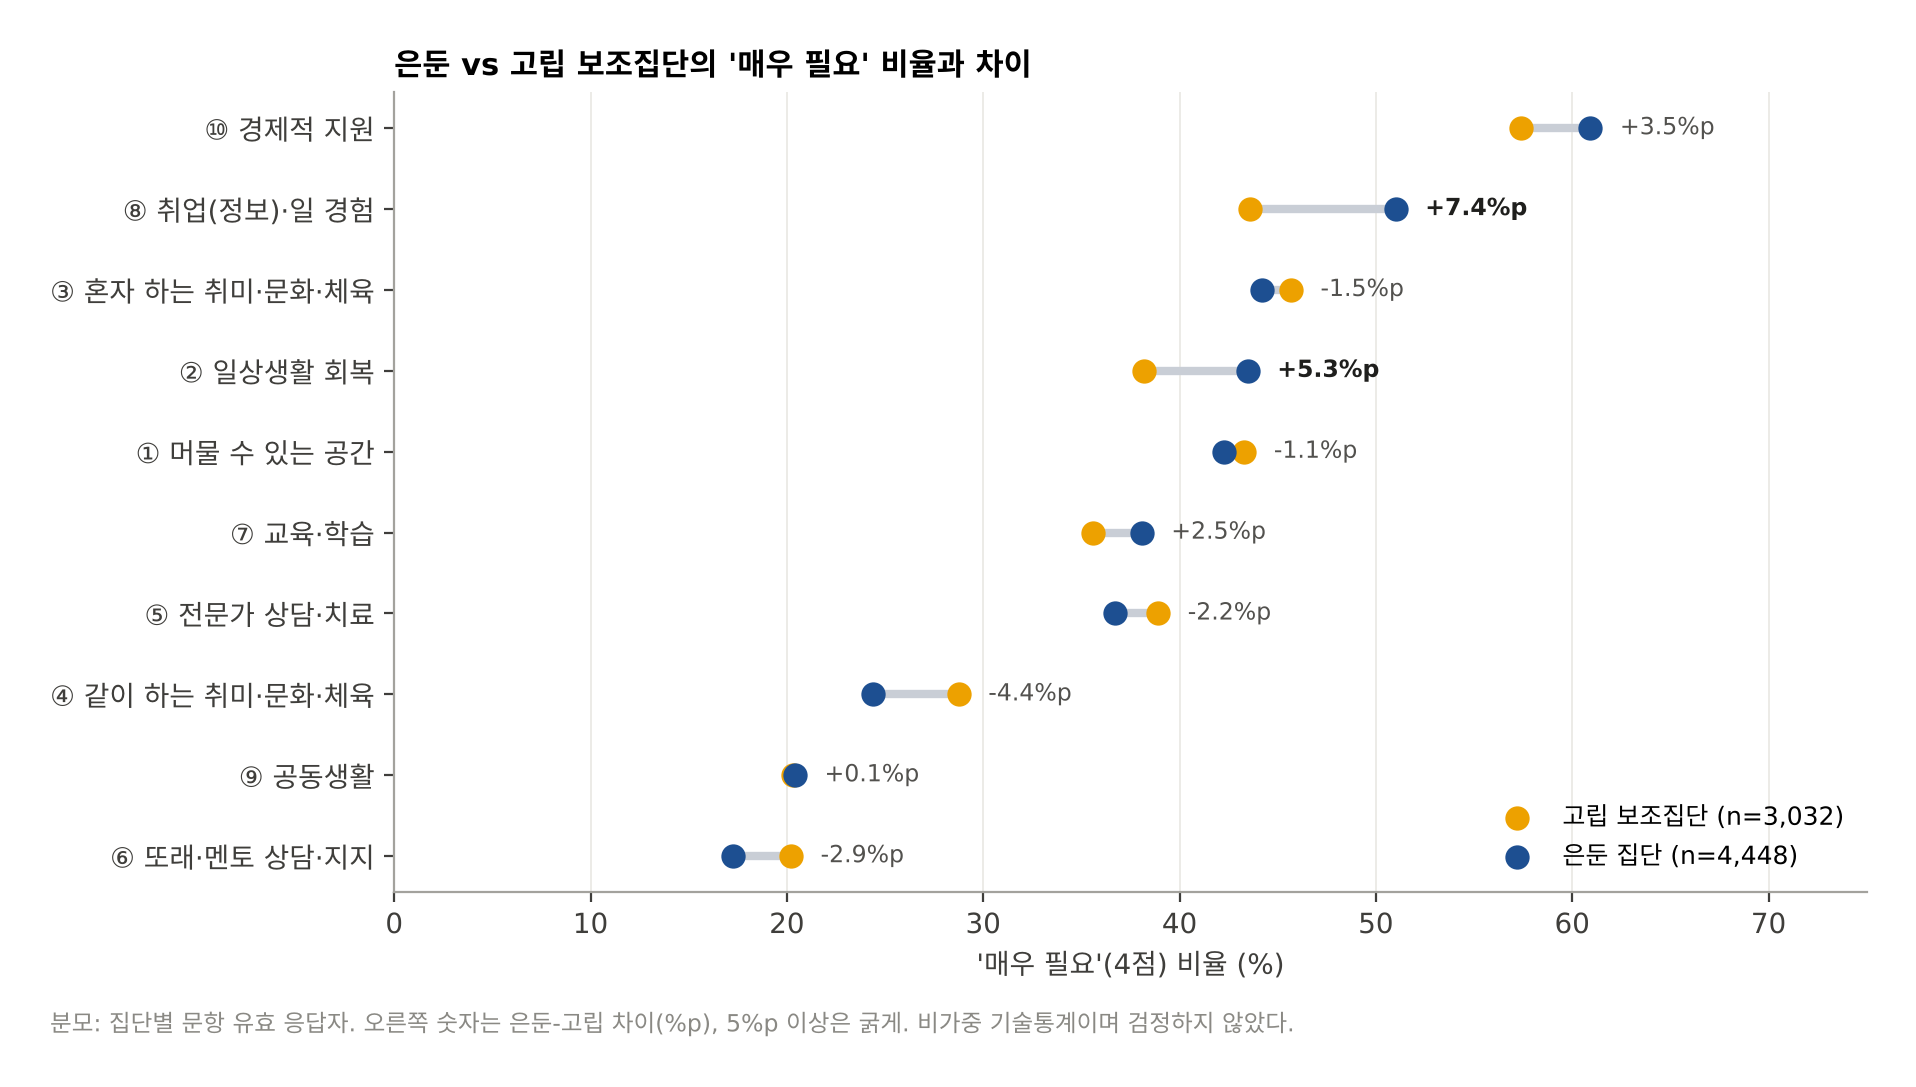

**발견.** 두 집단의 순위는 대체로 비슷하지만, 은둔 집단이 더 높은 영역은 ⑧ 취업(정보)·일 경험(+7.4%p)이고 고립 보조집단이 더 높은 영역은 ④ 같이 하는 취미·문화·체육(-4.4%p)이다.

**왜 중요한가.** 주 분석집단(은둔)의 순위가 보조집단에서도 크게 뒤집히지 않는지는 수요 순위의 안정성을 보는 근거가 된다.
**단정할 수 없는 것.** 집단 구성(연령·외출 정도) 차이를 통제하지 않았으므로 차이의 원인은 알 수 없다.

In [11]:
pv4 = lik.pivot(index="영역코드", columns="집단", values="p4").loc[Q10]
pv4["차이(은둔-고립)"] = pv4["은둔"] - pv4["고립 보조"]
order = pv4.sort_values("은둔").index
fig, ax = plt.subplots(figsize=(9.5, 5.2))
yy = np.arange(len(order))
d = pv4.loc[order]
ax.hlines(yy, d[["은둔", "고립 보조"]].min(axis=1), d[["은둔", "고립 보조"]].max(axis=1), color="#c9ced6", lw=3)
ax.scatter(d["고립 보조"], yy, s=60, color="#eda100", label=f"고립 보조집단 (n={len(aux):,})", zorder=3)
ax.scatter(d["은둔"], yy, s=60, color="#1d4f91", label=f"은둔 집단 (n={len(demand):,})", zorder=3)
for yi, (a, b, dd) in enumerate(zip(d["은둔"], d["고립 보조"], d["차이(은둔-고립)"])):
    ax.text(max(a, b) + 1.5, yi, f"{dd:+.1f}%p", va="center", fontsize=8.5, color=INK2 if abs(dd) < 5 else INK, fontweight="bold" if abs(dd) >= 5 else "normal")
ax.set_yticks(yy, [AREA[q] for q in order]); ax.set_xlim(0, 75); ax.grid(axis="y", visible=False)
ax.set_xlabel("'매우 필요'(4점) 비율 (%)")
ax.set_title("은둔 vs 고립 보조집단의 '매우 필요' 비율과 차이")
ax.legend(loc="lower right")
f = show_fig(fig, "q1", "demand_group_dumbbell", "분모: 집단별 문항 유효 응답자. 오른쪽 숫자는 은둔-고립 차이(%p), 5%p 이상은 굵게. 비가중 기술통계이며 검정하지 않았다.")
big = pv4["차이(은둔-고립)"].sort_values()
display(Markdown(f"""**발견.** 두 집단의 순위는 대체로 비슷하지만, 은둔 집단이 더 높은 영역은 {AREA[big.index[-1]]}({big.iloc[-1]:+.1f}%p)이고 고립 보조집단이 더 높은 영역은 {AREA[big.index[0]]}({big.iloc[0]:+.1f}%p)이다.

**왜 중요한가.** 주 분석집단(은둔)의 순위가 보조집단에서도 크게 뒤집히지 않는지는 수요 순위의 안정성을 보는 근거가 된다.
**단정할 수 없는 것.** 집단 구성(연령·외출 정도) 차이를 통제하지 않았으므로 차이의 원인은 알 수 없다."""))

## 1-3. 은둔 집단 안에서도 필요도는 달라지는가?

같은 은둔 집단이라도 외출 정도와 은둔 이유에 따라 필요한 지원이 다를 수 있다. 하위 집단별 '매우 필요' 비율을 은둔 전체와의 차이(색)로 비교한다. 이는 사용자 단계를 판정하려는 것이 아니라, 앱이 초기 추천에 쓸 수 있는 응답 패턴이 데이터에 있는지 확인하는 탐색이다.

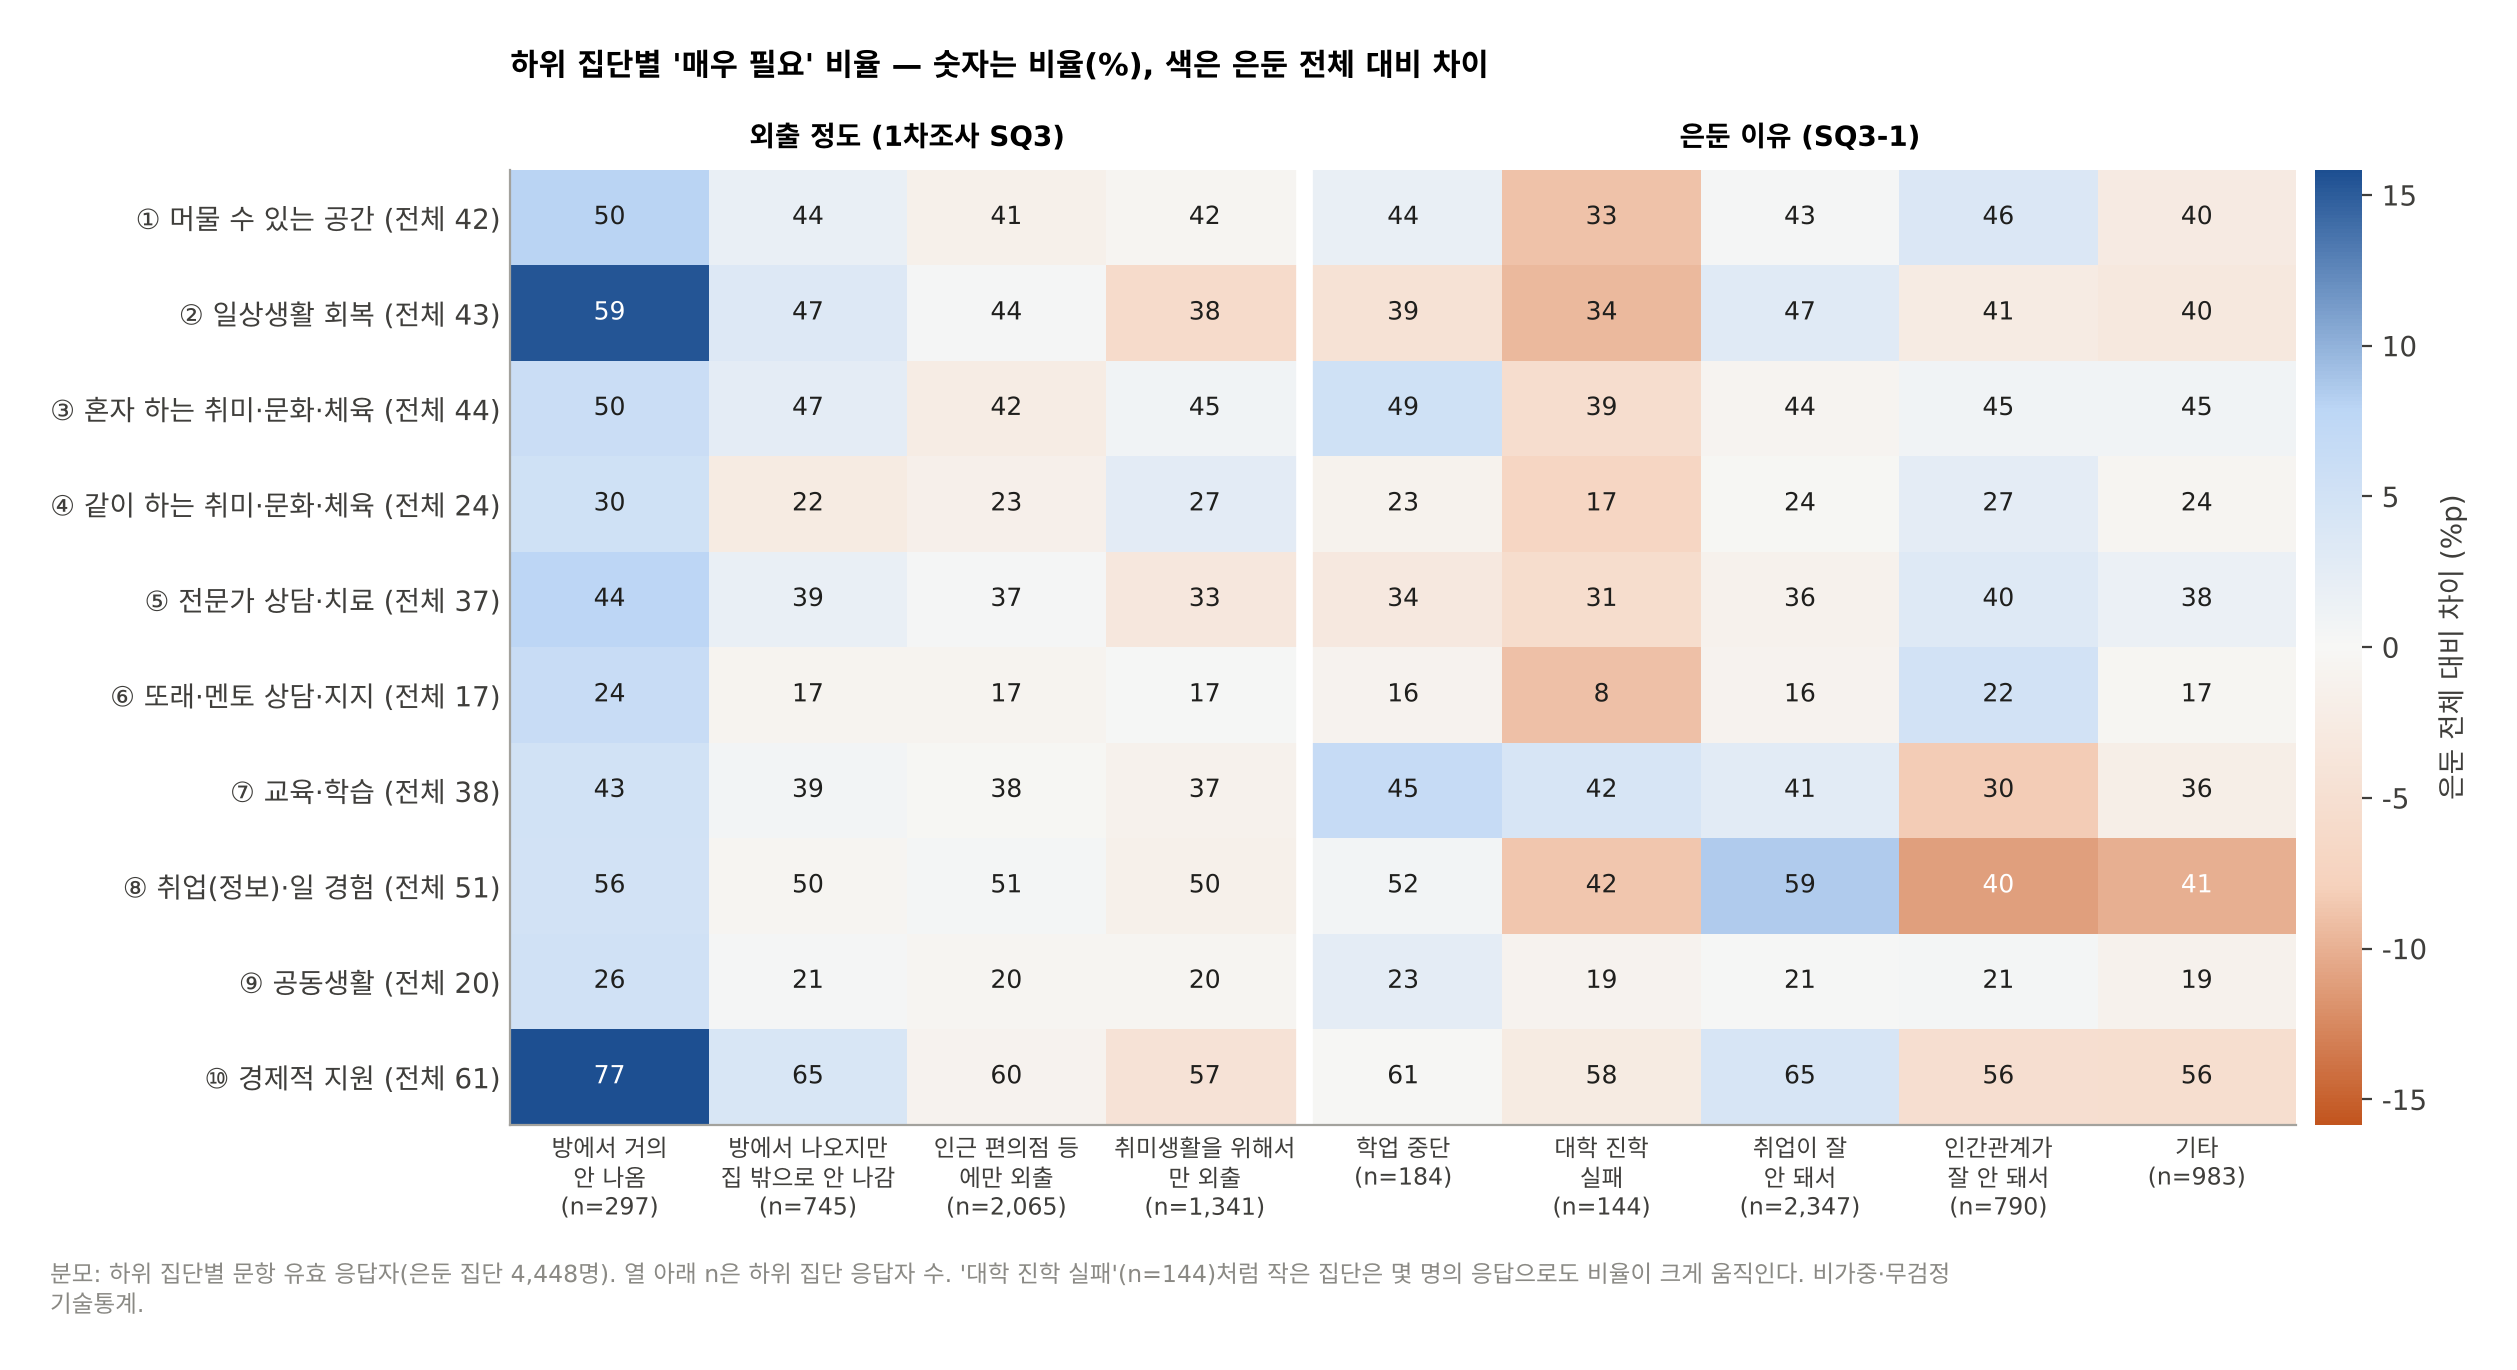

In [12]:
SQ3 = {"1": "방에서 거의\n안 나옴", "2": "방에서 나오지만\n집 밖으로 안 나감", "3": "인근 편의점 등\n에만 외출", "4": "취미생활을 위해서\n만 외출"}
SQ3A1 = {"1": "학업 중단", "2": "대학 진학\n실패", "3": "취업이 잘\n안 돼서", "4": "인간관계가\n잘 안 돼서", "7": "기타"}
overall = lik[lik["집단"].eq("은둔")].set_index("영역코드").p4
cols, rows = [], []
for var, labels, title in [("sq3", SQ3, "외출 정도"), ("sq3a1", SQ3A1, "은둔 이유")]:
    for code_, lab in labels.items():
        g = demand[demand[var].eq(code_)]
        cols.append((title, lab, len(g)))
        for q in Q10:
            v = g[q].dropna()
            rows.append({"구분": title, "하위집단": lab.replace("\n", " "), "n": len(g), "영역코드": q, "영역": AREA[q],
                         "매우 필요(%)": pct(v.eq("4").sum(), len(v)), "은둔 전체 대비(%p)": pct(v.eq("4").sum(), len(v)) - overall[q]})
sub = save_csv(pd.DataFrame(rows), "s1_demand_subgroups")
val = sub.pivot_table(index="영역코드", columns=["구분", "하위집단"], values="매우 필요(%)", sort=False).loc[Q10]
dif = sub.pivot_table(index="영역코드", columns=["구분", "하위집단"], values="은둔 전체 대비(%p)", sort=False).loc[Q10]
fig, ax = plt.subplots(figsize=(12, 6.2))
lim = np.nanmax(np.abs(dif.values))
im = ax.imshow(dif.values, cmap=DIVERGE, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
for i in range(val.shape[0]):
    for j in range(val.shape[1]):
        ax.text(j, i, f"{val.values[i, j]:.0f}", ha="center", va="center", fontsize=9, color="white" if abs(dif.values[i, j]) > lim * 0.6 else INK)
ax.set_xticks(range(len(cols)), [f"{lab}\n(n={n:,})" for _, lab, n in cols], fontsize=8.5)
ax.set_yticks(range(10), [f"{AREA[q]} (전체 {overall[q]:.0f})" for q in Q10])
ax.axvline(len(SQ3) - 0.5, color="white", lw=6)
ax.text((len(SQ3) - 1) / 2, -0.75, "외출 정도 (1차조사 SQ3)", ha="center", fontsize=10, fontweight="bold")
ax.text(len(SQ3) + (len(SQ3A1) - 1) / 2, -0.75, "은둔 이유 (SQ3-1)", ha="center", fontsize=10, fontweight="bold")
ax.tick_params(length=0); ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01); cb.set_label("은둔 전체 대비 차이 (%p)"); cb.outline.set_visible(False)
ax.set_title("하위 집단별 '매우 필요' 비율 — 숫자는 비율(%), 색은 은둔 전체 대비 차이", pad=34)
f = show_fig(fig, "q1", "demand_subgroup_heatmap", f"분모: 하위 집단별 문항 유효 응답자(은둔 집단 {len(demand):,}명). 열 아래 n은 하위 집단 응답자 수. "
             "'대학 진학 실패'(n=144)처럼 작은 집단은 몇 명의 응답으로도 비율이 크게 움직인다. 비가중·무검정 기술통계.")

In [13]:
def cell(g, lab, q):
    r = sub[(sub["구분"].eq(g)) & (sub["하위집단"].eq(lab)) & (sub["영역코드"].eq(q))].iloc[0]
    return r["매우 필요(%)"]
display(Markdown(f"""**발견.** '방에서 거의 안 나옴' 집단은 10개 영역 중 {int((sub[sub['하위집단'].eq('방에서 거의 안 나옴')]['은둔 전체 대비(%p)'] > 0).sum())}개에서 은둔 전체보다 '매우 필요'가 높다. 다만 외출 정도가 늘수록 꾸준히 낮아지는 관계는 일부 영역에서만 보인다. 이 집단은 경제적 지원 {cell('외출 정도','방에서 거의 안 나옴','q21_10'):.0f}%, 일상생활 회복 {cell('외출 정도','방에서 거의 안 나옴','q21_02'):.0f}%로, '취미생활을 위해서만 외출' 집단({cell('외출 정도','취미생활을 위해서 만 외출','q21_10'):.0f}%, {cell('외출 정도','취미생활을 위해서 만 외출','q21_02'):.0f}%)보다 높다.
은둔 이유별로는 '취업이 잘 안 돼서' 집단의 취업 지원({cell('은둔 이유','취업이 잘 안 돼서','q21_08'):.0f}%)과 '인간관계가 잘 안 돼서' 집단의 취업 지원({cell('은둔 이유','인간관계가 잘 안 돼서','q21_08'):.0f}%)이 크게 갈리고, 인간관계 집단은 상담·또래 지지가 상대적으로 높다.

**왜 중요한가.** 은둔 이유(F9)와 외출 상태(F7)에 따라 필요한 지원의 방향이 다르다는 점은 앱의 초기 필요 태그 추천 설계를 뒷받침한다. 다만 추천은 사용자가 확인·수정하도록 두어야 한다.
**단정할 수 없는 것.** 응답 패턴의 차이일 뿐 인과관계가 아니며, 비확률 표본이라 일반화할 수 없다."""))

**발견.** '방에서 거의 안 나옴' 집단은 10개 영역 중 10개에서 은둔 전체보다 '매우 필요'가 높다. 다만 외출 정도가 늘수록 꾸준히 낮아지는 관계는 일부 영역에서만 보인다. 이 집단은 경제적 지원 77%, 일상생활 회복 59%로, '취미생활을 위해서만 외출' 집단(57%, 38%)보다 높다.
은둔 이유별로는 '취업이 잘 안 돼서' 집단의 취업 지원(59%)과 '인간관계가 잘 안 돼서' 집단의 취업 지원(40%)이 크게 갈리고, 인간관계 집단은 상담·또래 지지가 상대적으로 높다.

**왜 중요한가.** 은둔 이유(F9)와 외출 상태(F7)에 따라 필요한 지원의 방향이 다르다는 점은 앱의 초기 필요 태그 추천 설계를 뒷받침한다. 다만 추천은 사용자가 확인·수정하도록 두어야 한다.
**단정할 수 없는 것.** 응답 패턴의 차이일 뿐 인과관계가 아니며, 비확률 표본이라 일반화할 수 없다.

In [14]:
dem = pd.DataFrame({"영역": [AREA[q] for q in Q10]})
hk = lik[lik["집단"].eq("은둔")].set_index("영역코드").loc[Q10]
ix = lik[lik["집단"].eq("고립 보조")].set_index("영역코드").loc[Q10]
dem["은둔 매우 필요(%)"] = hk.p4.values; dem["은둔 필요 3+4(%)"] = hk["필요(3+4)"].values
dem["매우 필요 순위"] = dem["은둔 매우 필요(%)"].rank(ascending=False, method="min").astype(int)
dem["필요 3+4 순위"] = dem["은둔 필요 3+4(%)"].rank(ascending=False, method="min").astype(int)
dem["고립 매우 필요(%)"] = ix.p4.values; dem["은둔-고립(%p)"] = dem["은둔 매우 필요(%)"] - dem["고립 매우 필요(%)"]
rng = sub.groupby("영역코드")["매우 필요(%)"].agg(["min", "max"]).loc[Q10]
dem["하위집단 범위(%)"] = [f"{a:.0f}~{b:.0f}" for a, b in zip(rng["min"], rng["max"])]
dem = dem.sort_values("매우 필요 순위")
save_csv(dem, "s1_demand_summary")
show_table(dem, "표 1-1. 영역별 지원 필요도 요약 (은둔 집단 기준 정렬)",
           fmt={c: "{:.1f}" for c in ["은둔 매우 필요(%)", "은둔 필요 3+4(%)", "고립 매우 필요(%)"]} | {"은둔-고립(%p)": "{:+.1f}"},
           highlight=["은둔 매우 필요(%)"], note="하위집단 범위는 그림 1-3의 외출 정도·은둔 이유 9개 하위 집단의 최솟값~최댓값. 모든 비율은 문항별 유효 응답자 분모, 비가중.")

**표 1-1. 영역별 지원 필요도 요약 (은둔 집단 기준 정렬)**

영역,은둔 매우 필요(%),은둔 필요 3+4(%),매우 필요 순위,필요 3+4 순위,고립 매우 필요(%),은둔-고립(%p),하위집단 범위(%)
⑩ 경제적 지원,60.9,90.5,1,1,57.4,+3.5,56~77
⑧ 취업(정보)·일 경험,51.0,85.2,2,2,43.6,+7.4,40~59
③ 혼자 하는 취미·문화·체육,44.2,81.3,3,4,45.7,-1.5,39~50
② 일상생활 회복,43.5,81.9,4,3,38.2,+5.3,34~59
① 머물 수 있는 공간,42.2,77.9,5,6,43.3,-1.1,33~50
⑦ 교육·학습,38.1,78.8,6,5,35.6,+2.5,30~45
⑤ 전문가 상담·치료,36.7,70.8,7,7,38.9,-2.2,31~44
④ 같이 하는 취미·문화·체육,24.4,58.4,8,8,28.8,-4.4,17~30
⑨ 공동생활,20.4,49.7,9,9,20.3,+0.1,19~26
⑥ 또래·멘토 상담·지지,17.3,43.3,10,10,20.2,-2.9,8~24


<span style='color:#8a8984;font-size:90%'>하위집단 범위는 그림 1-3의 외출 정도·은둔 이유 9개 하위 집단의 최솟값~최댓값. 모든 비율은 문항별 유효 응답자 분모, 비가중.</span>

## 1-4. 서비스 원문에는 어떤 영역 후보가 있는가?

STEP 00 규칙으로 붙인 Q1 영역 후보를 출처별로 본다. 경제적 지원(v4: main + candidate)은 다른 영역보다 많아 같은 축에 두면 나머지 영역이 잘 보이지 않으므로 근거별로 나눠 따로 보여준다. v4 이전(v3)에는 지급 방식 단어·제공유형만으로도 ⑩이 붙어 3,603건이었다(STEP 00 ⑩ v4 참고).

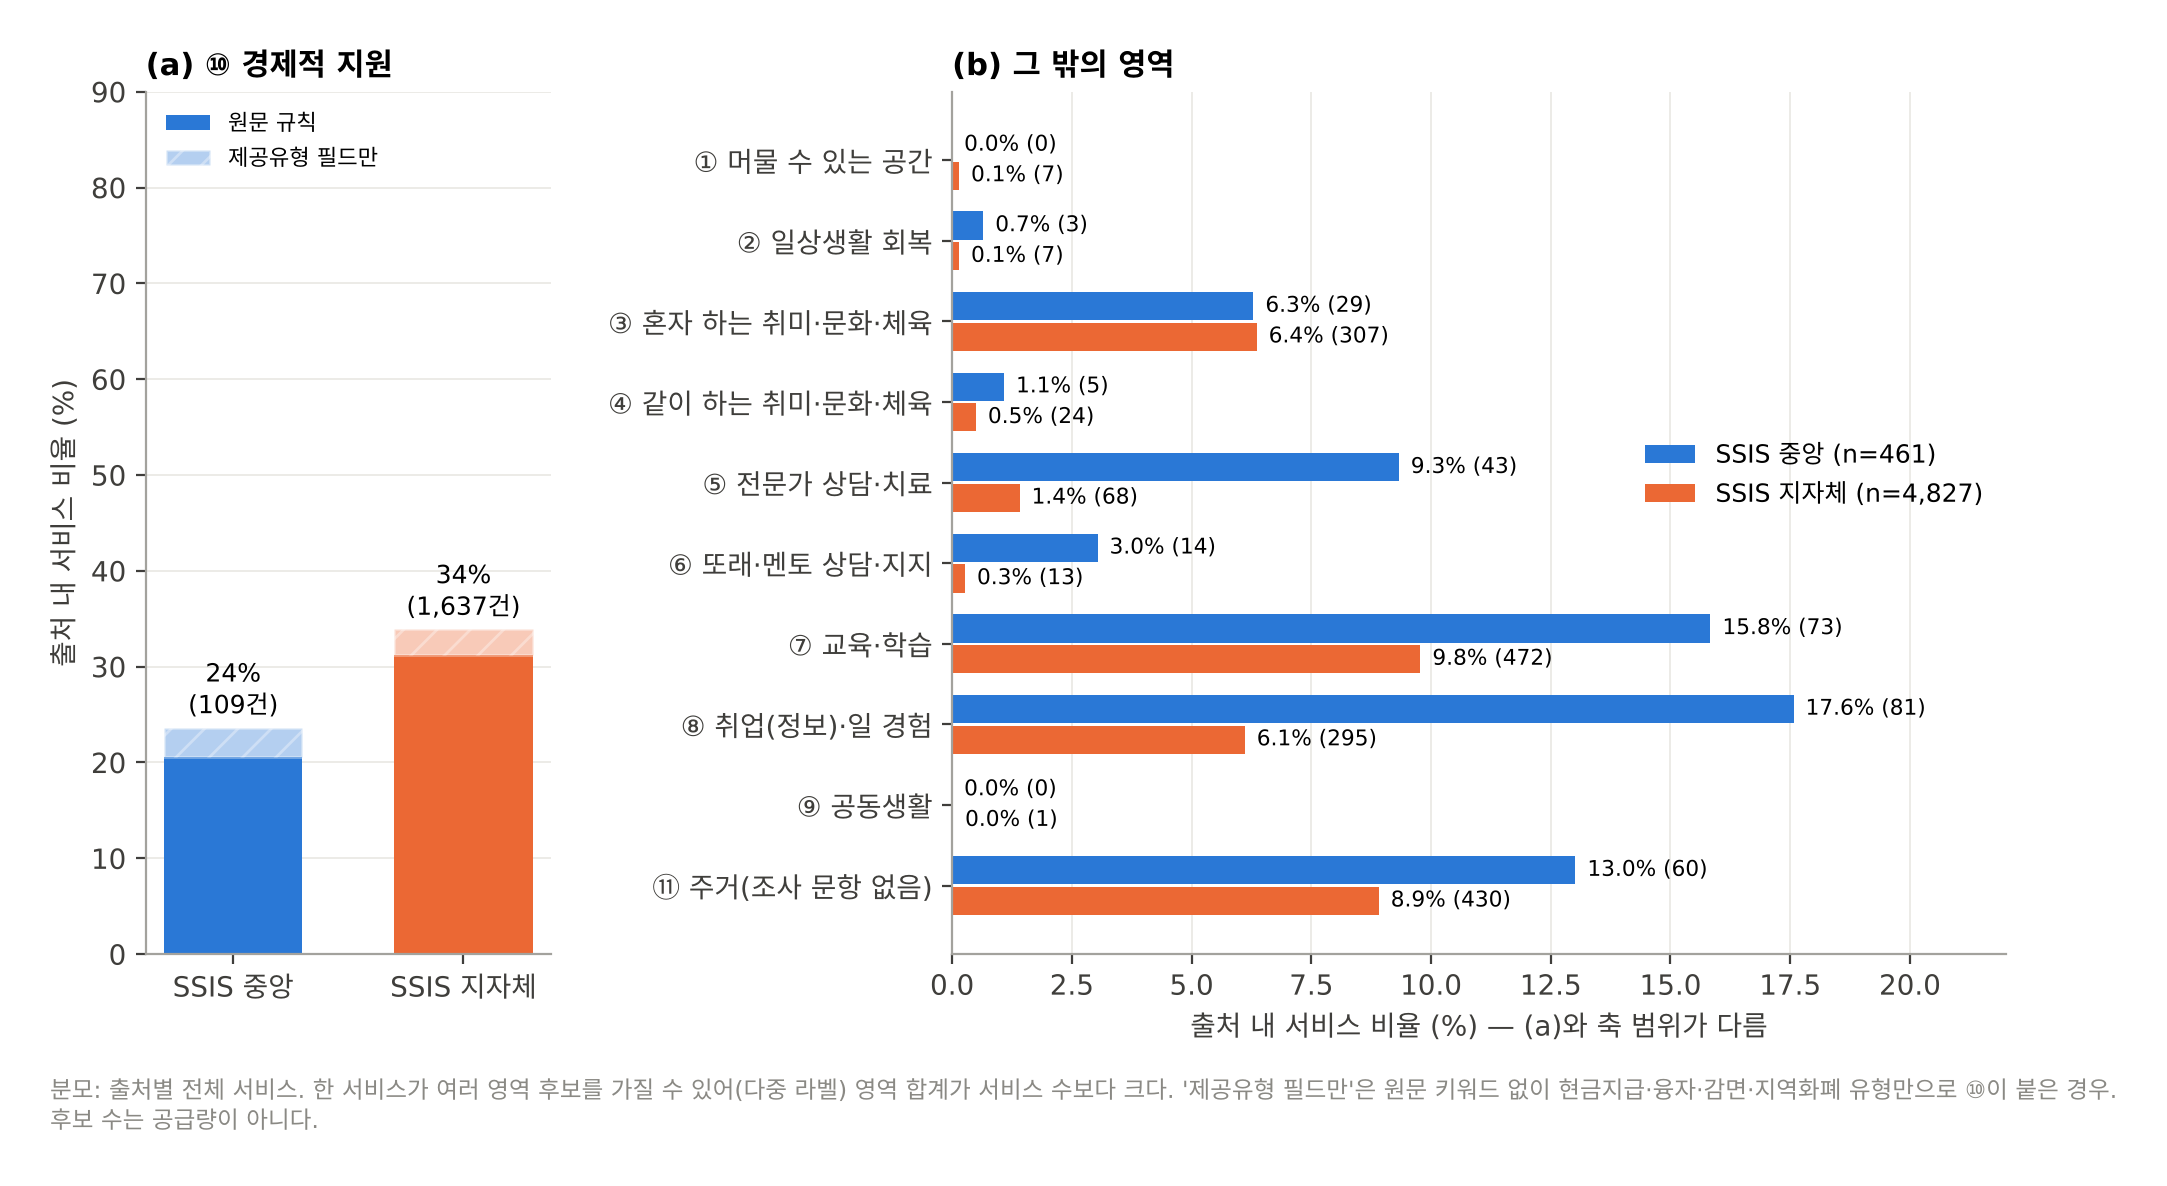

In [15]:
na = m.need_area_q21.fillna("N")
ev = m.need_area_q21_evidence.fillna("")
rows = []
for q in Q11:
    hit = area_has(na, q)
    field_only = hit & ev.str.contains(rf"{q}: \[field\]")
    for s in ["central", "local"]:
        sel = hit & m.source.eq(s)
        rows.append({"영역코드": q, "영역": AREA[q], "출처": SRC_KO[s], "후보 수": int(sel.sum()), "출처 내 비율(%)": pct(sel.sum(), N_SRC[s]),
                     "제공유형 필드만": int((field_only & m.source.eq(s)).sum()), "원문 규칙": int((sel & ~field_only).sum())})
cand = save_csv(pd.DataFrame(rows), "s1_area_candidates")

fig = plt.figure(figsize=(12, 5.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 2.6], wspace=0.55)
ax0, ax1 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
d10 = cand[cand["영역코드"].eq("q21_10")].set_index("출처")
for i, s in enumerate(["central", "local"]):
    r = d10.loc[SRC_KO[s]]
    a, b = pct(r["원문 규칙"], N_SRC[s]), pct(r["제공유형 필드만"], N_SRC[s])
    ax0.bar(i, a, color=C_SRC[s], width=0.6, label="원문 규칙" if i == 0 else None)
    ax0.bar(i, b, bottom=a, color=C_SRC[s], alpha=0.35, width=0.6, hatch="//", edgecolor="white", label="제공유형 필드만" if i == 0 else None)
    ax0.text(i, a + b + 1.5, f"{a+b:.0f}%\n({int(r['후보 수']):,}건)", ha="center", fontsize=9)
ax0.set_xticks([0, 1], [f"{SRC_KO['central']}", f"{SRC_KO['local']}"]); ax0.set_ylim(0, 90)
ax0.set_ylabel("출처 내 서비스 비율 (%)"); ax0.set_title("(a) ⑩ 경제적 지원")
ax0.legend(loc="upper left", fontsize=8); ax0.grid(axis="x", visible=False)
oth = [q for q in Q11 if q != "q21_10"]
w = 0.38
for k, s in enumerate(["central", "local"]):
    d = cand[cand["출처"].eq(SRC_KO[s])].set_index("영역코드").loc[oth]
    yy = np.arange(len(oth)) + (k - 0.5) * w
    ax1.barh(yy, d["출처 내 비율(%)"], height=w * 0.92, color=C_SRC[s], label=f"{SRC_KO[s]} (n={N_SRC[s]:,})")
    for yi, p, n in zip(yy, d["출처 내 비율(%)"], d["후보 수"]):
        ax1.text(p + 0.25, yi, f"{p:.1f}% ({n:,})", va="center", fontsize=7.8)
ax1.set_yticks(range(len(oth)), [AREA[q] for q in oth]); ax1.invert_yaxis(); ax1.set_xlim(0, 22); ax1.grid(axis="y", visible=False)
ax1.set_xlabel("출처 내 서비스 비율 (%) — (a)와 축 범위가 다름"); ax1.set_title("(b) 그 밖의 영역")
ax1.legend(loc="upper right", bbox_to_anchor=(1.0, 0.62))
f = show_fig(fig, "q1", "area_candidates", "분모: 출처별 전체 서비스. 한 서비스가 여러 영역 후보를 가질 수 있어(다중 라벨) 영역 합계가 서비스 수보다 크다. "
             "'제공유형 필드만'은 원문 키워드 없이 현금지급·융자·감면·지역화폐 유형만으로 ⑩이 붙은 경우. 후보 수는 공급량이 아니다.")

In [16]:
c10 = cand[cand["영역코드"].eq("q21_10")]
fo = c10["제공유형 필드만"].sum(); tot = c10["후보 수"].sum()
dd = cand[cand["영역코드"].ne("q21_10")].pivot(index="영역코드", columns="출처", values="출처 내 비율(%)")
diff = (dd[SRC_KO["central"]] - dd[SRC_KO["local"]]).sort_values(ascending=False)
low = cand.groupby("영역코드")["후보 수"].sum().loc[["q21_01", "q21_02", "q21_09"]]
display(Markdown(f"""**발견.** 경제적 지원 후보 {tot:,}건 중 {fo:,}건({pct(fo, tot):.0f}%)은 원문 키워드 없이 제공유형 필드만으로 붙었다. 나머지 영역은 모두 출처 내 20% 미만이다.
중앙은 {', '.join(AREA[q] for q in diff.index[:2])}에서 지자체보다 비율이 높고, 은둔 청년의 고유 수요에 가까운 {', '.join(f'{AREA[q]}({n}건)' for q, n in low.items())}는 후보가 거의 없다.

**왜 중요한가.** 경제적 지원은 근거별로 나눠 해석해야 하며, 후보가 적은 영역이 '서비스가 없다'는 뜻인지 '규칙이 놓쳤다'는 뜻인지는 STEP 02 재현율 검증 전에는 알 수 없다. Q1 본 분석은 이 두 가능성을 구분해야 한다."""))

**발견.** 경제적 지원 후보 1,746건 중 143건(8%)은 원문 키워드 없이 제공유형 필드만으로 붙었다. 나머지 영역은 모두 출처 내 20% 미만이다.
중앙은 ⑧ 취업(정보)·일 경험, ⑤ 전문가 상담·치료에서 지자체보다 비율이 높고, 은둔 청년의 고유 수요에 가까운 ① 머물 수 있는 공간(7건), ② 일상생활 회복(10건), ⑨ 공동생활(1건)는 후보가 거의 없다.

**왜 중요한가.** 경제적 지원은 근거별로 나눠 해석해야 하며, 후보가 적은 영역이 '서비스가 없다'는 뜻인지 '규칙이 놓쳤다'는 뜻인지는 STEP 02 재현율 검증 전에는 알 수 없다. Q1 본 분석은 이 두 가능성을 구분해야 한다.

## 1-5. 영역 후보는 청년 대상 근거를 갖추고 있는가?

영역 후보가 있어도 청년이 신청할 수 있는 서비스인지는 따로 확인해야 한다. 연령 규칙과 태그·원문 '청년' 언급을 함께 놓고 영역별 구성을 본다.

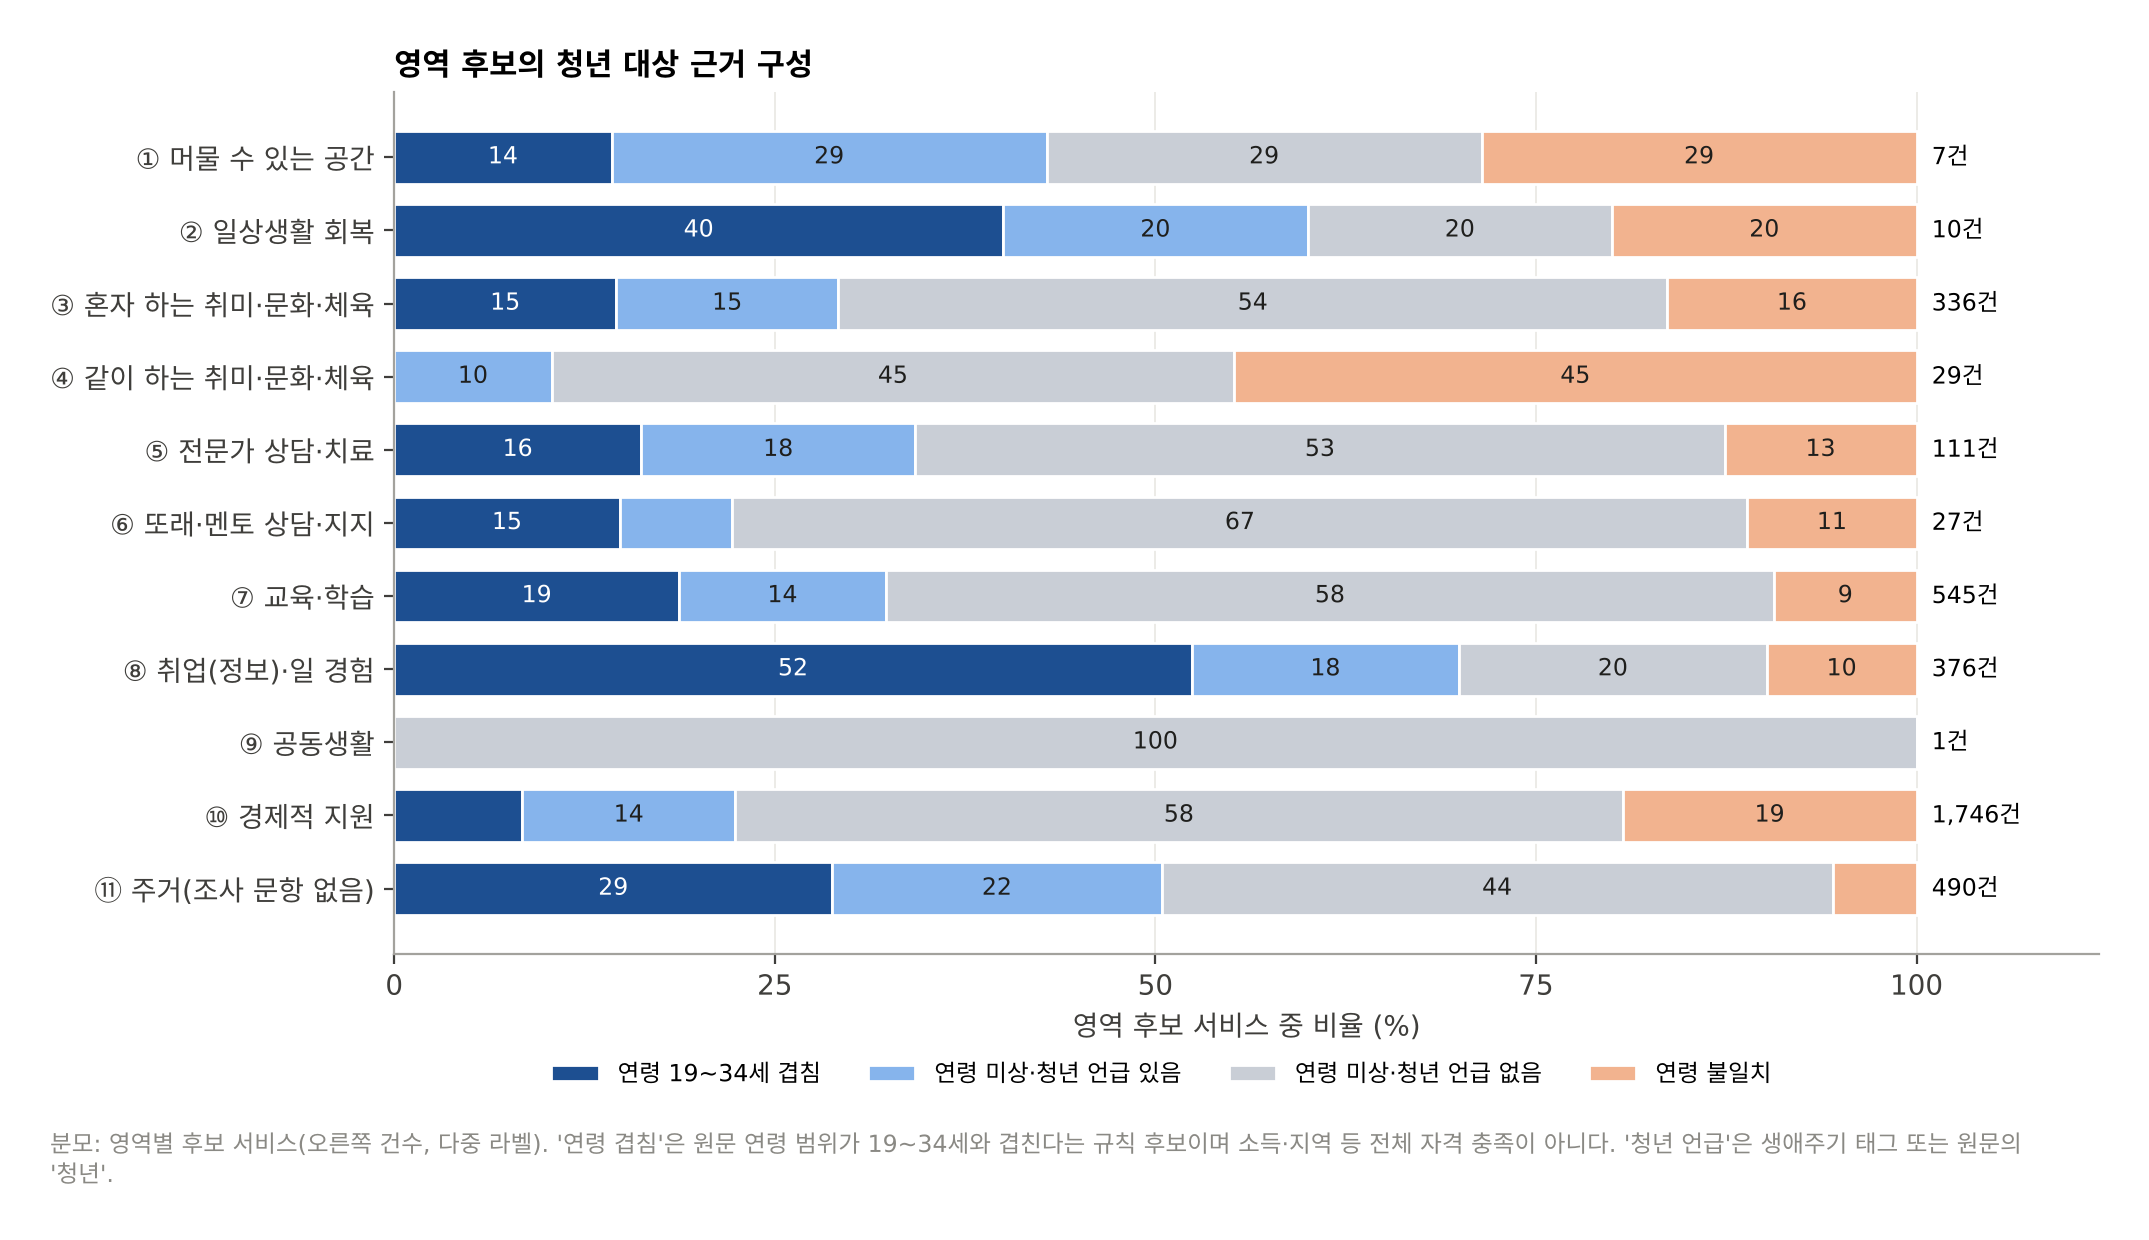

**발견.** 후보 20건 이상인 영역 중 연령 근거가 확인된 비율은 ⑧ 취업(정보)·일 경험(52%)이 가장 높고, 경제적 지원은 8%에 그친다.
후보 20건 이상인 영역에서는 '연령 미상'이 가장 큰 덩어리이며, 그중 청년 언급조차 없는 비율이 ⑥ 또래·멘토 상담·지지에서 67%로 가장 높다.

**왜 중요한가.** 청년 대상을 '연령 겹침'으로만 좁히면 대부분의 후보가 빠지고, 미상을 모두 포함하면 노인·아동 서비스가 섞인다. Q1은 하한(겹침)과 상한(겹침+미상)을 함께 보고해야 한다.

In [17]:
age = e.youth_age
yt = e.youth_tag | e.youth_text
YCAT = ["연령 19~34세 겹침", "연령 미상·청년 언급 있음", "연령 미상·청년 언급 없음", "연령 불일치"]
ycat = np.where(age.eq("겹침"), YCAT[0], np.where(age.eq("불일치"), YCAT[3], np.where(yt, YCAT[1], YCAT[2])))
e["youth_cat"] = ycat
rows = []
for q in Q11:
    hit = area_has(na, q)
    for c in YCAT:
        rows.append({"영역코드": q, "영역": AREA[q], "청년 근거": c, "건수": int((hit & e.youth_cat.eq(c)).sum()), "영역 후보": int(hit.sum())})
yev = save_csv(pd.DataFrame(rows), "s1_area_youth_evidence")
pvy = yev.pivot(index="영역코드", columns="청년 근거", values="건수").loc[Q11, YCAT]
share = 100 * pvy.div(pvy.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 5.6))
left = np.zeros(len(share))
for c, col in zip(YCAT, ["#1d4f91", "#86b4ec", N_COLOR, "#f2b38f"]):
    ax.barh(range(len(share)), share[c], left=left, color=col, edgecolor="white", height=0.72, label=c)
    for i, (l, v) in enumerate(zip(left, share[c])):
        if v >= 9:
            ax.text(l + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if col == "#1d4f91" else INK)
    left += share[c].to_numpy()
for i, n in enumerate(pvy.sum(axis=1)):
    ax.text(101, i, f"{n:,}건", va="center", fontsize=8.5)
ax.set_yticks(range(len(share)), [AREA[q] for q in Q11]); ax.invert_yaxis(); ax.set_xlim(0, 112); ax.grid(axis="y", visible=False)
ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xlabel("영역 후보 서비스 중 비율 (%)")
ax.set_title("영역 후보의 청년 대상 근거 구성")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.45, -0.1), fontsize=8.5)
f = show_fig(fig, "q1", "area_youth_evidence", "분모: 영역별 후보 서비스(오른쪽 건수, 다중 라벨). '연령 겹침'은 원문 연령 범위가 19~34세와 겹친다는 규칙 후보이며 소득·지역 등 전체 자격 충족이 아니다. "
             "'청년 언급'은 생애주기 태그 또는 원문의 '청년'.")
big_area = pvy.sum(axis=1).ge(20)          # 후보 20건 미만 영역은 비율 비교에서 제외
best = share.loc[big_area, YCAT[0]].sort_values(ascending=False)
unk = share.loc[big_area, YCAT[2]].sort_values(ascending=False)
display(Markdown(f"""**발견.** 후보 20건 이상인 영역 중 연령 근거가 확인된 비율은 {AREA[best.index[0]]}({best.iloc[0]:.0f}%)이 가장 높고, 경제적 지원은 {share.loc['q21_10', YCAT[0]]:.0f}%에 그친다.
후보 20건 이상인 영역에서는 '연령 미상'이 가장 큰 덩어리이며, 그중 청년 언급조차 없는 비율이 {AREA[unk.index[0]]}에서 {unk.iloc[0]:.0f}%로 가장 높다.

**왜 중요한가.** 청년 대상을 '연령 겹침'으로만 좁히면 대부분의 후보가 빠지고, 미상을 모두 포함하면 노인·아동 서비스가 섞인다. Q1은 하한(겹침)과 상한(겹침+미상)을 함께 보고해야 한다."""))

## 1-6. 한 서비스는 여러 영역에 걸쳐 있는가?

영역 후보는 다중 라벨이다. 어떤 영역이 함께 붙는지 보면 서비스 묶음의 성격과, 영역별 건수를 더할 때 생기는 중복의 크기를 알 수 있다.

/tmp/ipykernel_417/1409681218.py:56: UserWarning: Glyph 9322 (\N{CIRCLED NUMBER ELEVEN}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()


/tmp/ipykernel_417/1409681218.py:62: UserWarning: Glyph 9322 (\N{CIRCLED NUMBER ELEVEN}) missing from font(s) DejaVu Sans.
  fig.savefig(path, bbox_inches="tight", facecolor="white", pad_inches=0.25)


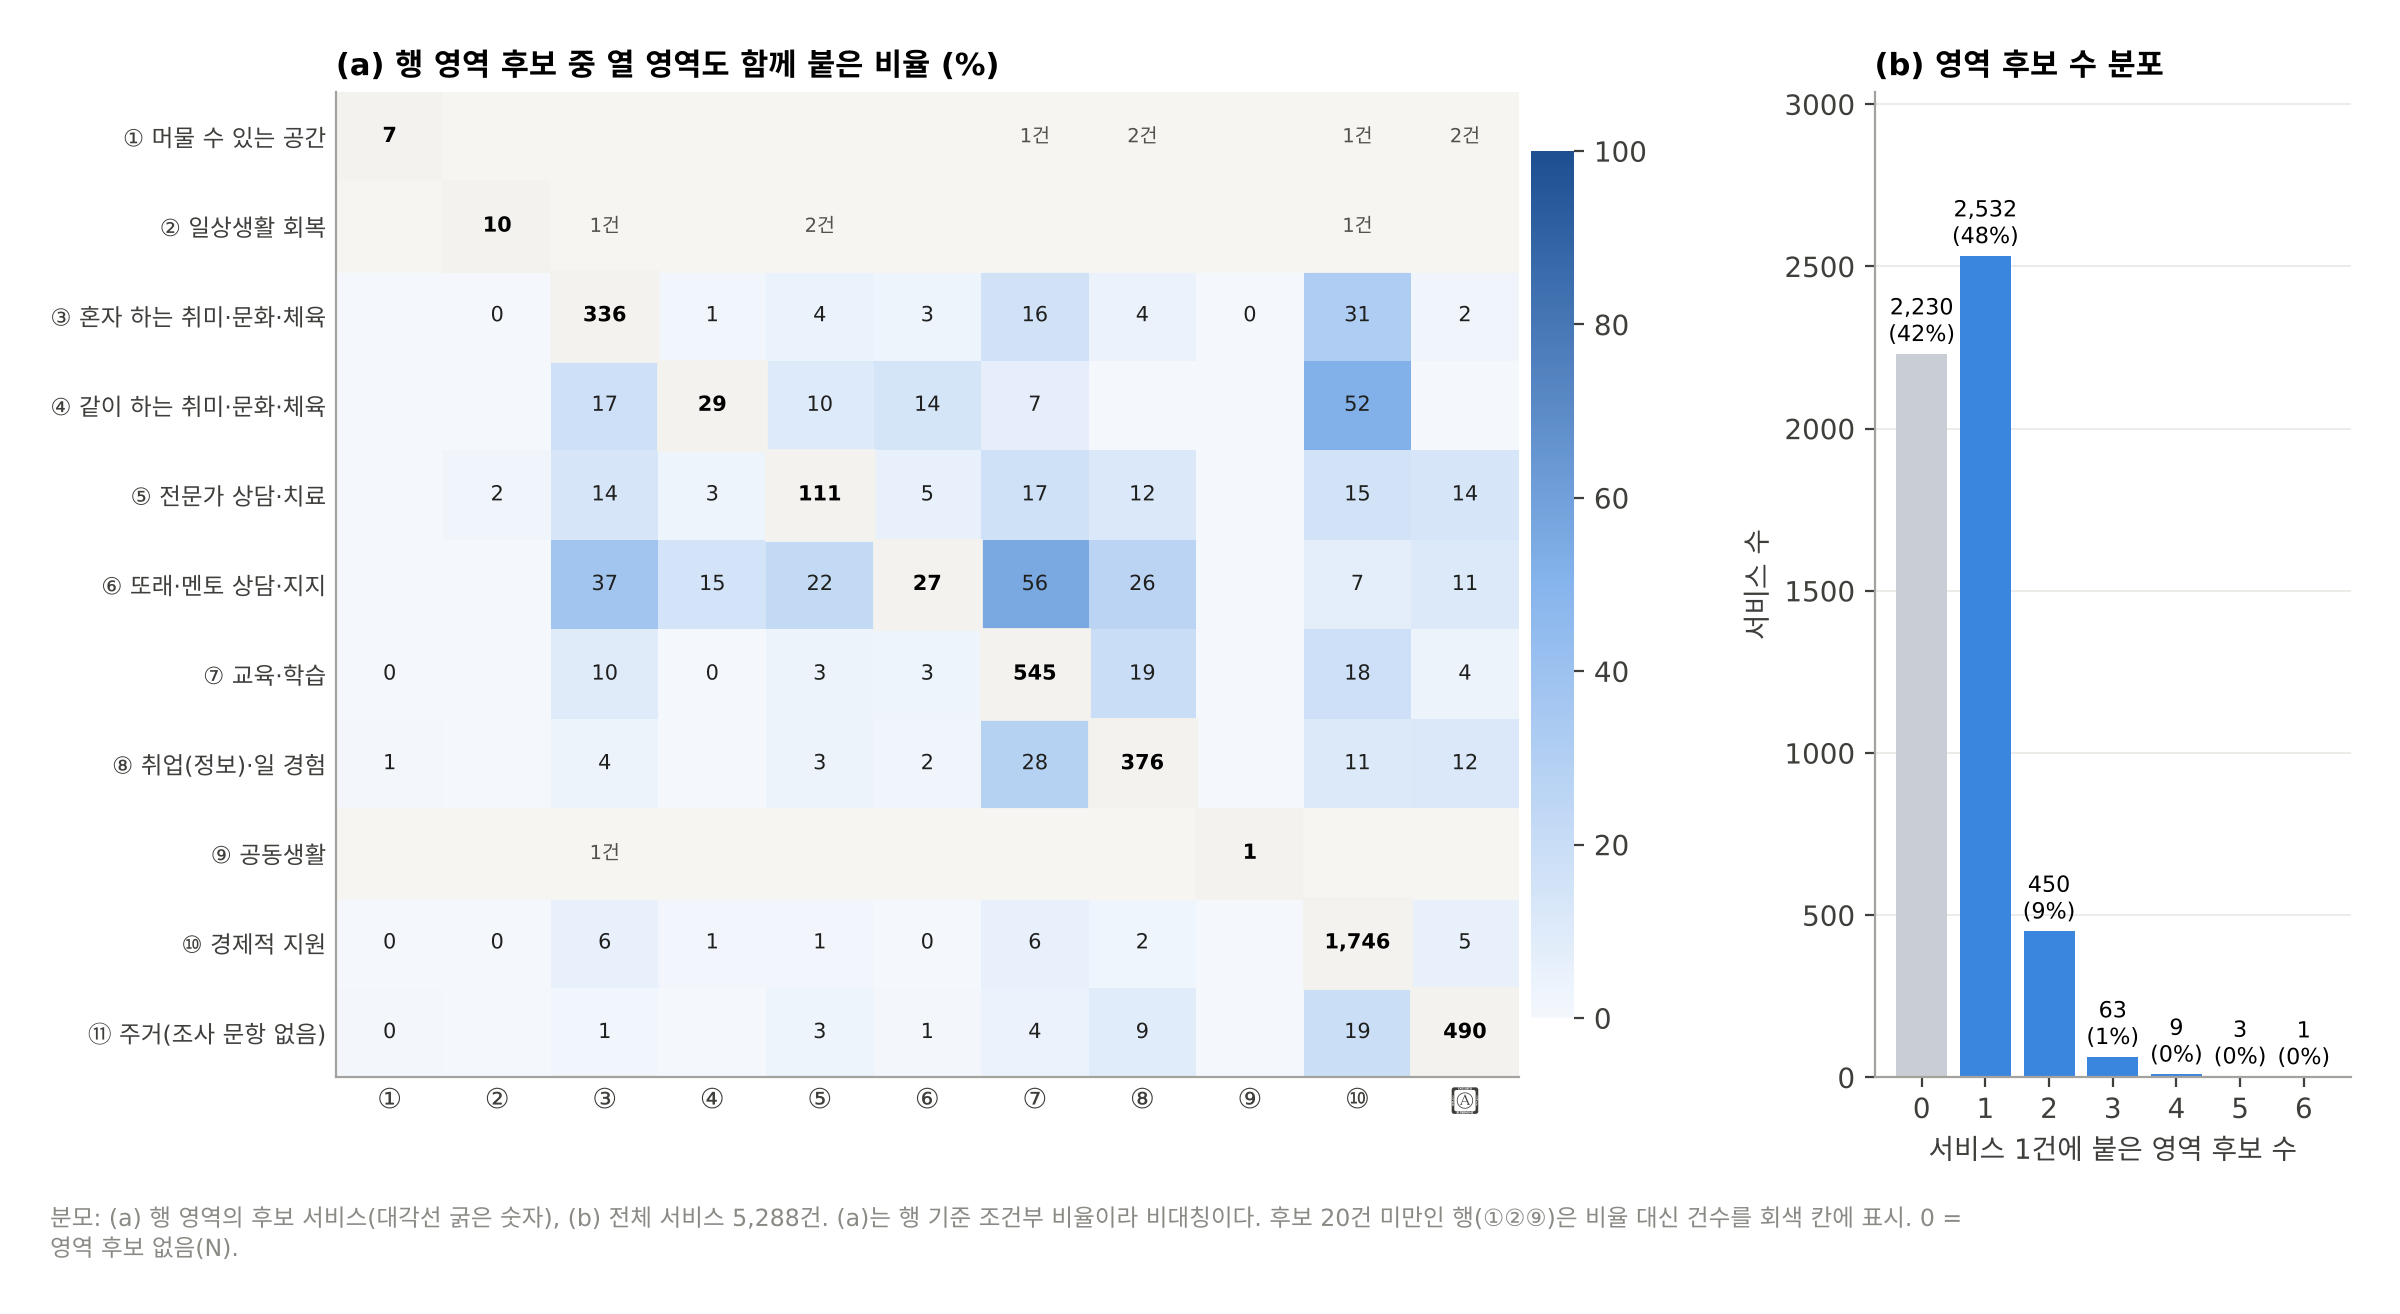

**발견.** 영역 후보가 2개 이상인 서비스는 526건(10%)이고, 후보가 없는 서비스가 2,230건(42%)이다.
다른 영역과 함께 붙는 경우 대부분 경제적 지원이 끼어 있다. 후보 20건 이상인 영역 중 ④ 같이 하는 취미·문화·체육 후보의 52%, ③ 혼자 하는 취미·문화·체육 후보의 31%가 경제적 지원 후보이기도 하다.

**왜 중요한가.** 영역별 건수를 더하면 같은 서비스가 여러 번 세어진다. Q1에서 '선택지 수'를 셀 때는 영역별 건수와 고유 서비스 수를 함께 써야 하며, 경제적 지원의 동반 라벨이 다른 영역의 성격을 흐리지 않는지 확인해야 한다.

In [18]:
lab_lists = na.str.split("|").map(lambda v: [x for x in v if x != "N"])
nlab = lab_lists.map(len)
co = pd.DataFrame(0, index=Q11, columns=Q11)
for v in lab_lists:
    for a in v:
        for b in v:
            co.loc[a, b] += 1
save_csv(co.rename(index=AREA, columns=AREA).reset_index(names="영역"), "s1_area_cooccurrence")
cond = 100 * co.div(np.diag(co).clip(min=1), axis=0)
fig = plt.figure(figsize=(13, 6.4))
gs = fig.add_gridspec(1, 2, width_ratios=[2.6, 1], wspace=0.35)
ax, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
marr = cond.to_numpy(dtype=float, copy=True); np.fill_diagonal(marr, np.nan); vmax_ = np.nanmax(marr)
im = ax.imshow(marr, cmap=BLUES, vmin=0, vmax=vmax_, aspect="auto")
for i in range(11):
    for j in range(11):
        if i == j:
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color="#f3f2ee")); ax.text(j, i, f"{co.iloc[i, j]:,}", ha="center", va="center", fontsize=7.5, fontweight="bold")
        elif co.iloc[i, i] < 20:
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color="#f6f5f2"))
            if co.iloc[i, j] > 0: ax.text(j, i, f"{co.iloc[i, j]}건", ha="center", va="center", fontsize=7, color=INK2)
        elif co.iloc[i, j] > 0:
            ax.text(j, i, f"{cond.iloc[i, j]:.0f}", ha="center", va="center", fontsize=7.5, color="white" if marr[i, j] > vmax_ * 0.6 else INK)
ax.set_xticks(range(11), [CIRC[i] for i in range(11)]); ax.set_yticks(range(11), [AREA[q] for q in Q11], fontsize=8.5)
ax.tick_params(length=0); ax.grid(False)
ax.set_title("(a) 행 영역 후보 중 열 영역도 함께 붙은 비율 (%)")
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.01); cb.outline.set_visible(False)
dist = nlab.value_counts().sort_index()
ax2.bar(dist.index.astype(str), dist.values, color=["#c9ced6"] + ["#3a86df"] * (len(dist) - 1))
for x, v in zip(dist.index.astype(str), dist.values):
    ax2.text(x, v + 40, f"{v:,}\n({pct(v, len(m)):.0f}%)", ha="center", fontsize=8)
ax2.set_xlabel("서비스 1건에 붙은 영역 후보 수"); ax2.set_ylabel("서비스 수"); ax2.set_ylim(0, dist.max() * 1.2)
ax2.set_title("(b) 영역 후보 수 분포"); ax2.grid(axis="x", visible=False)
f = show_fig(fig, "q1", "area_cooccurrence", "분모: (a) 행 영역의 후보 서비스(대각선 굵은 숫자), (b) 전체 서비스 5,288건. (a)는 행 기준 조건부 비율이라 비대칭이다. "
             "후보 20건 미만인 행(①②⑨)은 비율 대신 건수를 회색 칸에 표시. 0 = 영역 후보 없음(N).")
multi = int((nlab >= 2).sum()); econ_pair = cond.loc[[q for q in Q11 if q != "q21_10" and co.loc[q, q] >= 20], "q21_10"].sort_values(ascending=False)
display(Markdown(f"""**발견.** 영역 후보가 2개 이상인 서비스는 {multi:,}건({pct(multi, len(m)):.0f}%)이고, 후보가 없는 서비스가 {dist.get(0, 0):,}건({pct(dist.get(0, 0), len(m)):.0f}%)이다.
다른 영역과 함께 붙는 경우 대부분 경제적 지원이 끼어 있다. 후보 20건 이상인 영역 중 {AREA[econ_pair.index[0]]} 후보의 {econ_pair.iloc[0]:.0f}%, {AREA[econ_pair.index[1]]} 후보의 {econ_pair.iloc[1]:.0f}%가 경제적 지원 후보이기도 하다.

**왜 중요한가.** 영역별 건수를 더하면 같은 서비스가 여러 번 세어진다. Q1에서 '선택지 수'를 셀 때는 영역별 건수와 고유 서비스 수를 함께 써야 하며, 경제적 지원의 동반 라벨이 다른 영역의 성격을 흐리지 않는지 확인해야 한다."""))

In [19]:
REGION_WORDS = set(m.region_sido.dropna()) | set(m.region_sgg.dropna())
REGION_STEMS = sorted({w for r in REGION_WORDS for w in [r, re.sub(r"(특별자치시|특별자치도|특별시|광역시|통합특별시|도|시|군|구)$", "", r)] if len(w) >= 2}, key=len, reverse=True)
REGION_RX = re.compile("|".join(map(re.escape, REGION_STEMS)))
e["name_norm"] = m.servNm.fillna("").map(lambda s: re.sub(r"[\s\(\)\[\]·ㆍ,\-'\"‘’“”]", "", REGION_RX.sub("", s)))
rows = []
for q in Q11:
    hit = area_has(na, q)
    rows.append({"영역": AREA[q], "중앙 후보": int((hit & m.source.eq("central")).sum()), "지자체 후보": int((hit & m.source.eq("local")).sum()),
                 "정규화 사업명(보조)": e.loc[hit, "name_norm"].nunique(), "필드만 근거": int((hit & ev.str.contains(rf"{q}: \[field\]")).sum()),
                 "연령 겹침": int((hit & e.youth_age.eq("겹침")).sum()), "다른 영역과 중복(%)": pct((hit & nlab.ge(2)).sum(), hit.sum())})
area_tbl = pd.DataFrame(rows); area_tbl["후보 합계"] = area_tbl["중앙 후보"] + area_tbl["지자체 후보"]
area_tbl = area_tbl[["영역", "중앙 후보", "지자체 후보", "후보 합계", "정규화 사업명(보조)", "필드만 근거", "연령 겹침", "다른 영역과 중복(%)"]]
save_csv(area_tbl, "s1_area_summary")
show_table(area_tbl, "표 1-2. 영역별 서비스 후보 비교 (조사 문항 순)", fmt={c: "{:,.0f}" for c in area_tbl.columns[1:-1]} | {"다른 영역과 중복(%)": "{:.0f}"},
           bar=["후보 합계"], note="정규화 사업명은 서비스명에서 지역명을 지운 이름의 고유 개수로, 같은 사업이라고 확정된 수가 아니라 지역별 반복을 가늠하는 보조 지표다. "
                                   "⑪ 주거는 조사 문항이 없어 수요와 비교할 수 없다.")

**표 1-2. 영역별 서비스 후보 비교 (조사 문항 순)**

영역,중앙 후보,지자체 후보,후보 합계,정규화 사업명(보조),필드만 근거,연령 겹침,다른 영역과 중복(%)
① 머물 수 있는 공간,0,7,7,7,0,1,57
② 일상생활 회복,3,7,10,10,0,4,40
③ 혼자 하는 취미·문화·체육,29,307,336,279,0,49,50
④ 같이 하는 취미·문화·체육,5,24,29,25,0,0,79
⑤ 전문가 상담·치료,43,68,111,108,0,18,50
⑥ 또래·멘토 상담·지지,14,13,27,27,0,4,93
⑦ 교육·학습,73,472,545,474,0,102,45
⑧ 취업(정보)·일 경험,81,295,376,329,0,197,47
⑨ 공동생활,0,1,1,1,0,0,100
⑩ 경제적 지원,109,"1,637","1,746","1,271",143,147,18


<span style='color:#8a8984;font-size:90%'>정규화 사업명은 서비스명에서 지역명을 지운 이름의 고유 개수로, 같은 사업이라고 확정된 수가 아니라 지역별 반복을 가늠하는 보조 지표다. ⑪ 주거는 조사 문항이 없어 수요와 비교할 수 없다.</span>

# 2. 접근성과 서비스 이용 조건

원문에서 확인되는 신청·이용 조건과 그 불확실성을 본다. 사용자가 실제로 이용할 수 있는지를 확정하는 분석이 아니다.
라벨 정의: 신청 장벽(0 온라인 완결 ~ 3 필수 면접), 이용 외출 조건(0 집 안 ~ 3 정기 외출), 외출필요도(두 값의 환산 최대값). `use_barrier`·`outing_burden`은 개정 전 기준을 유지한 기존 컬럼이다.

## 2-1. 출처별로 접근성 라벨은 어떻게 분포하는가?

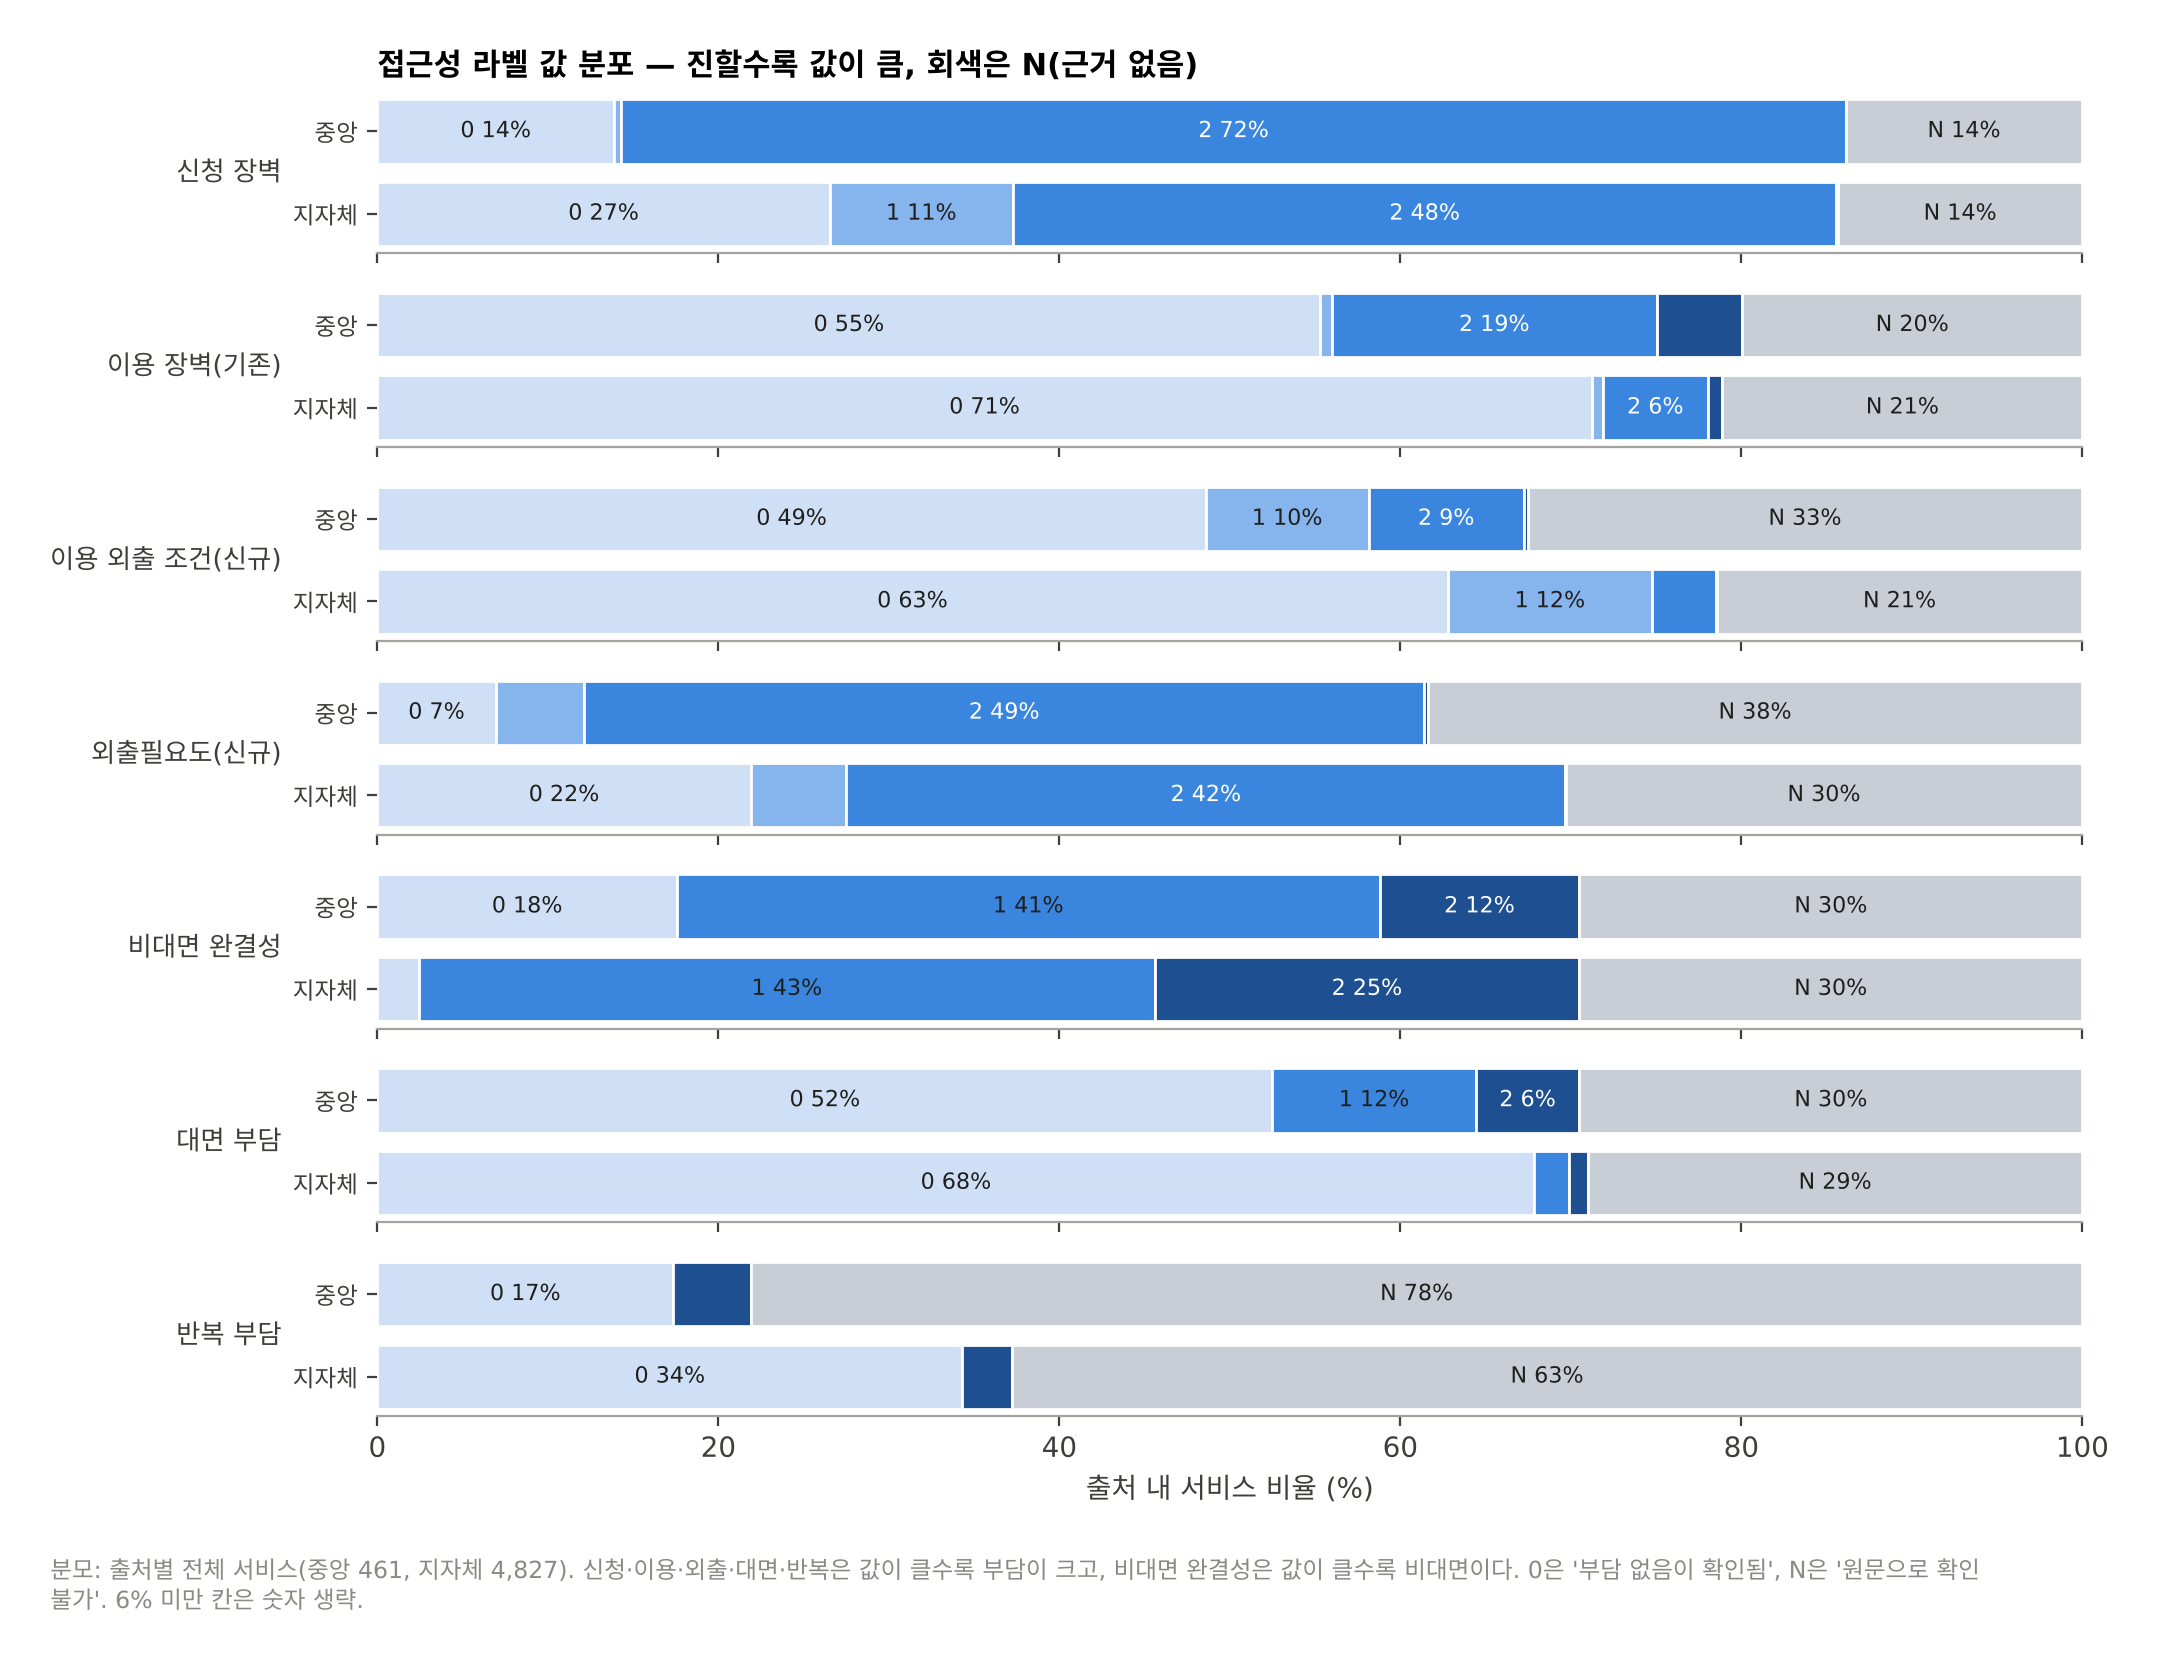

In [20]:
ACC = [("apply_barrier", "신청 장벽", 4), ("use_barrier", "이용 장벽(기존)", 4), ("use_outing", "이용 외출 조건(신규)", 4),
       ("outing_need", "외출필요도(신규)", 4), ("remote_complete", "비대면 완결성", 3), ("contact_burden", "대면 부담", 3), ("repeat_burden", "반복 부담", 3)]
rows = []
for col, ko, k in ACC:
    for s in ["central", "local"]:
        d = m.loc[m.source.eq(s), col].fillna("N")
        for v in [str(i) for i in range(k)] + ["N"]:
            rows.append({"라벨": ko, "컬럼": col, "출처": SRC_KO[s], "값": v, "건수": int(d.eq(v).sum()), "비율(%)": pct(d.eq(v).sum(), len(d))})
acc = save_csv(pd.DataFrame(rows), "s2_access_distribution")
fig, axes = plt.subplots(len(ACC), 1, figsize=(11, 8.6), sharex=True)
for ax, (col, ko, k) in zip(axes, ACC):
    for j, s in enumerate(["central", "local"]):
        d = acc[(acc["컬럼"].eq(col)) & (acc["출처"].eq(SRC_KO[s]))].set_index("값")
        left = 0
        for v in [str(i) for i in range(k)] + ["N"]:
            p = d.loc[v, "비율(%)"]
            colr = N_COLOR if v == "N" else (LEVEL4[int(v)] if k == 4 else LEVEL4[[0, 2, 3][int(v)]])
            ax.barh(j, p, left=left, color=colr, edgecolor="white", height=0.78)
            if p >= 6:
                ax.text(left + p / 2, j, f"{v} {p:.0f}%", ha="center", va="center", fontsize=8, color="white" if v in ("2", "3") else INK)
            left += p
    ax.set_yticks([0, 1], ["중앙", "지자체"], fontsize=8.5); ax.invert_yaxis(); ax.grid(False)
    ax.set_ylabel(ko, rotation=0, ha="right", va="center", fontsize=9.5)
    ax.spines["left"].set_visible(False)
axes[-1].set_xlim(0, 100); axes[-1].set_xlabel("출처 내 서비스 비율 (%)")
axes[0].set_title("접근성 라벨 값 분포 — 진할수록 값이 큼, 회색은 N(근거 없음)")
f = show_fig(fig, "access", "access_distribution", "분모: 출처별 전체 서비스(중앙 461, 지자체 4,827). 신청·이용·외출·대면·반복은 값이 클수록 부담이 크고, 비대면 완결성은 값이 클수록 비대면이다. "
             "0은 '부담 없음이 확인됨', N은 '원문으로 확인 불가'. 6% 미만 칸은 숫자 생략.")

In [21]:
def share(col, s, v):
    return acc[(acc["컬럼"].eq(col)) & (acc["출처"].eq(SRC_KO[s])) & (acc["값"].eq(v))]["비율(%)"].iloc[0]
display(Markdown(f"""**발견.** 신청 장벽은 지자체에서 0(온라인 완결) 비율이 {share('apply_barrier','local','0'):.0f}%로 중앙({share('apply_barrier','central','0'):.0f}%)보다 높고, 중앙은 2(방문)가 {share('apply_barrier','central','2'):.0f}%로 대부분이다.
이용 외출 조건은 두 출처 모두 0이 가장 많지만, 이는 현금·감면처럼 집에서 받는 제공유형이 많기 때문이다. 외출필요도의 N은 중앙 {share('outing_need','central','N'):.0f}%, 지자체 {share('outing_need','local','N'):.0f}%다.

**왜 중요한가.** 접근성이 낮아 보이는 이유가 '서비스 성격(현금형)'인지 '원문의 확인'인지 구분해야 한다. 추천에서 0과 N을 같은 '부담 없음'으로 정렬하면 정보가 없는 서비스가 외출 부담이 낮은 서비스처럼 앞에 나온다."""))

**발견.** 신청 장벽은 지자체에서 0(온라인 완결) 비율이 27%로 중앙(14%)보다 높고, 중앙은 2(방문)가 72%로 대부분이다.
이용 외출 조건은 두 출처 모두 0이 가장 많지만, 이는 현금·감면처럼 집에서 받는 제공유형이 많기 때문이다. 외출필요도의 N은 중앙 38%, 지자체 30%다.

**왜 중요한가.** 접근성이 낮아 보이는 이유가 '서비스 성격(현금형)'인지 '원문의 확인'인지 구분해야 한다. 추천에서 0과 N을 같은 '부담 없음'으로 정렬하면 정보가 없는 서비스가 외출 부담이 낮은 서비스처럼 앞에 나온다.

## 2-2. 신청 장벽과 이용 외출 조건은 함께 움직이는가?

신청은 온라인으로 끝나도 이용은 기관에 가야 할 수 있고, 반대도 있다. 두 라벨을 교차해 '신청과 이용의 외출 조건이 다른' 서비스가 얼마나 되는지 본다.

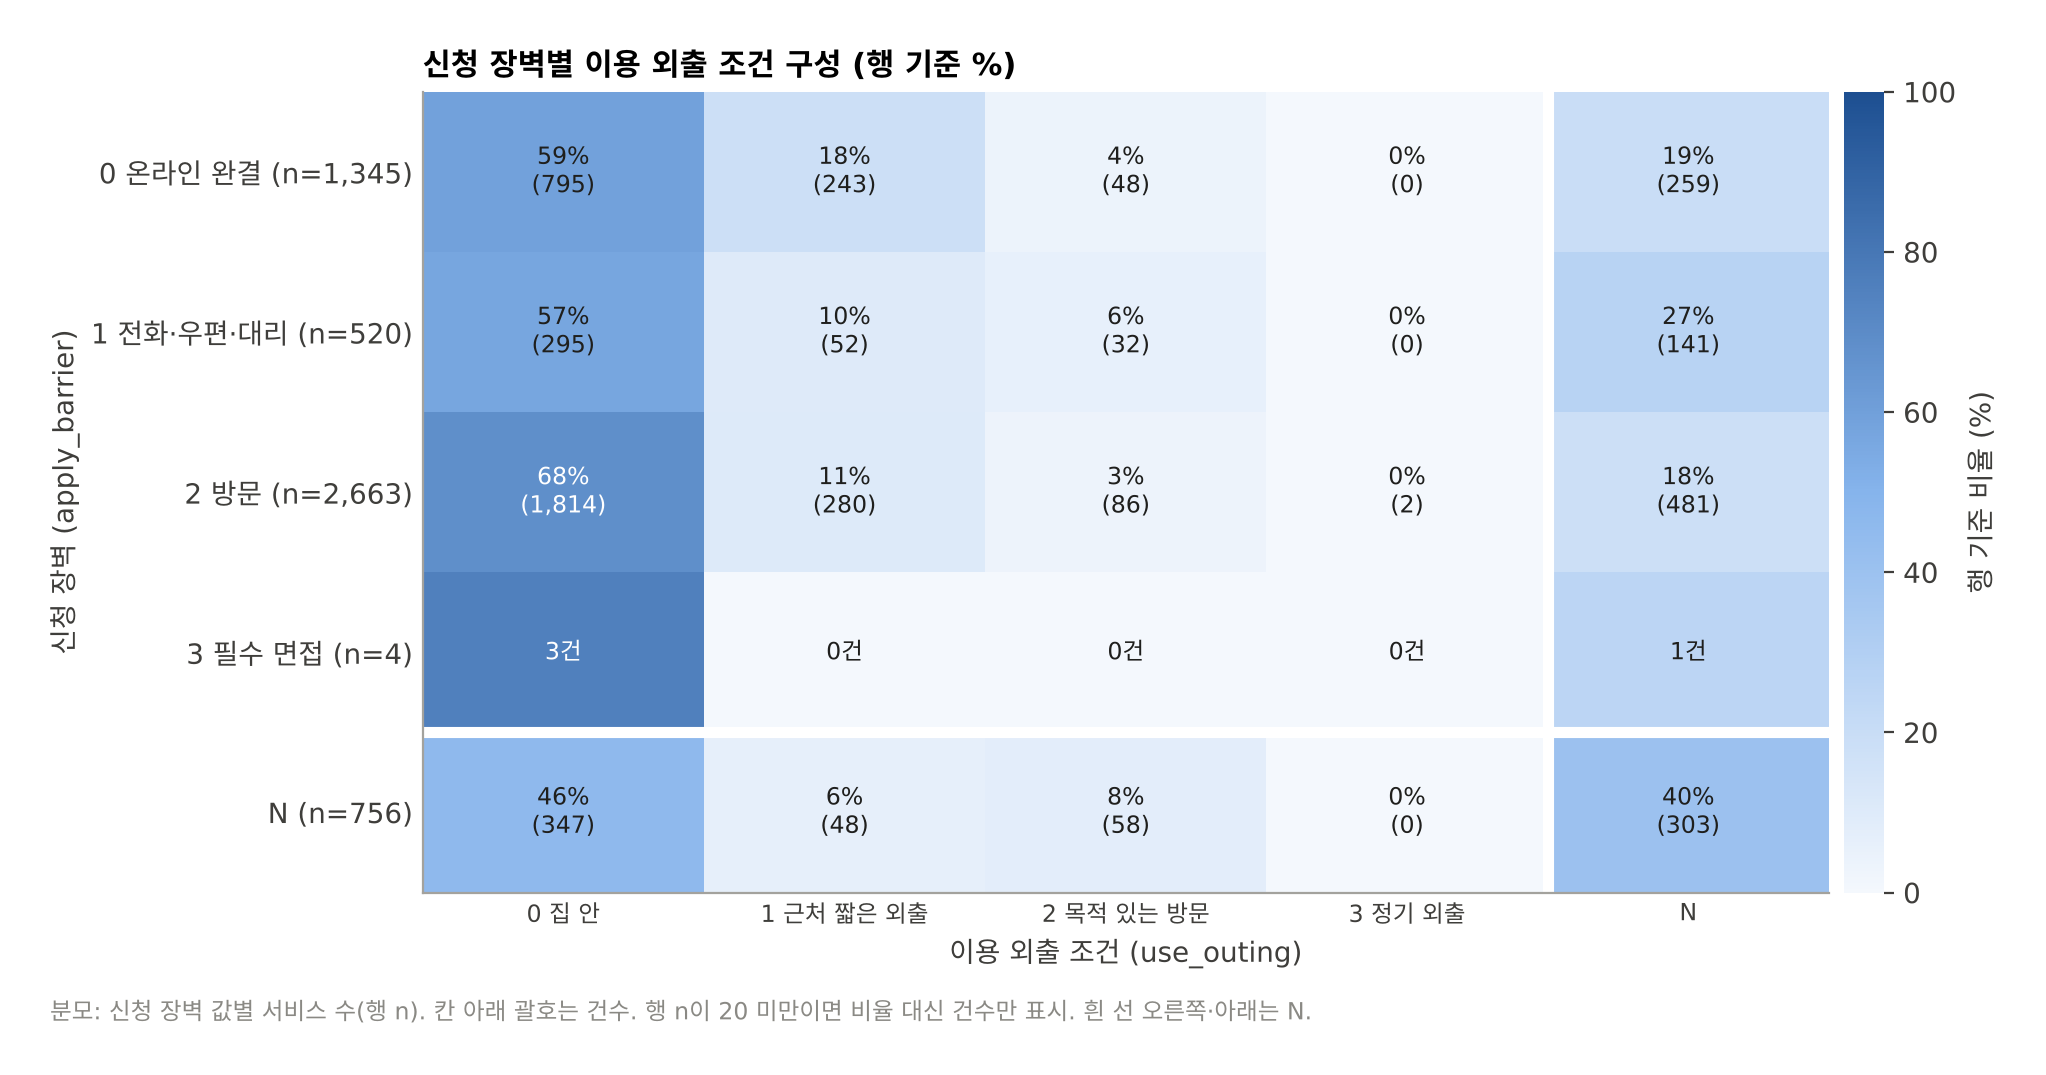

**발견.** 온라인으로 신청이 끝나는 서비스(1,345건) 중 291건(22%)은 이용 단계에서 외출(1 이상)이 필요하고, 방문 신청 서비스 중 1,814건은 이용은 집에서 끝난다.
신청 장벽이 N인 서비스에도 이용 외출 조건이 확인된 경우가 453건 있다.

**왜 중요한가.** 신청과 이용은 서로 다른 외출 조건이라 하나로 대신할 수 없다. 외출필요도처럼 두 값을 합친 지표를 쓰더라도, 앱은 '신청은 온라인, 이용은 방문'처럼 두 단계를 나눠 안내하는 편이 정확하다.

In [22]:
AB = {"0": "0 온라인 완결", "1": "1 전화·우편·대리", "2": "2 방문", "3": "3 필수 면접", "N": "N"}
UO = {"0": "0 집 안", "1": "1 근처 짧은 외출", "2": "2 목적 있는 방문", "3": "3 정기 외출", "N": "N"}
ct = pd.crosstab(m.apply_barrier.fillna("N"), m.use_outing.fillna("N")).reindex(index=list(AB), columns=list(UO), fill_value=0)
save_csv(ct.rename(index=AB, columns=UO).reset_index(names="신청 장벽 \\ 이용 외출 조건"), "s2_apply_x_use_outing")
rowp = 100 * ct.div(ct.sum(axis=1).replace(0, np.nan), axis=0)
fig, ax = plt.subplots(figsize=(9.5, 5.2))
im = ax.imshow(rowp.values, cmap=BLUES, vmin=0, vmax=100, aspect="auto")
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        n, p = ct.iloc[i, j], rowp.iloc[i, j]
        txt = f"{p:.0f}%\n({n:,})" if ct.iloc[i].sum() >= 20 else f"{n:,}건"
        ax.text(j, i, txt, ha="center", va="center", fontsize=8.5, color="white" if p > 60 else INK)
for k in [ct.shape[0] - 1.5, ]:
    ax.axhline(k, color="white", lw=4)
ax.axvline(ct.shape[1] - 1.5, color="white", lw=4)
ax.set_xticks(range(ct.shape[1]), list(UO.values()), fontsize=8.5); ax.set_yticks(range(ct.shape[0]), [f"{AB[k]} (n={ct.loc[k].sum():,})" for k in AB])
ax.set_xlabel("이용 외출 조건 (use_outing)"); ax.set_ylabel("신청 장벽 (apply_barrier)"); ax.tick_params(length=0); ax.grid(False)
ax.set_title("신청 장벽별 이용 외출 조건 구성 (행 기준 %)")
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.01); cb.set_label("행 기준 비율 (%)"); cb.outline.set_visible(False)
f = show_fig(fig, "access", "apply_x_use_outing", "분모: 신청 장벽 값별 서비스 수(행 n). 칸 아래 괄호는 건수. 행 n이 20 미만이면 비율 대신 건수만 표시. 흰 선 오른쪽·아래는 N.")
on_mis = int(ct.loc["0", ["1", "2", "3"]].sum()); visit_home = int(ct.loc["2", "0"])
display(Markdown(f"""**발견.** 온라인으로 신청이 끝나는 서비스({ct.loc['0'].sum():,}건) 중 {on_mis:,}건({pct(on_mis, ct.loc['0'].sum()):.0f}%)은 이용 단계에서 외출(1 이상)이 필요하고, 방문 신청 서비스 중 {visit_home:,}건은 이용은 집에서 끝난다.
신청 장벽이 N인 서비스에도 이용 외출 조건이 확인된 경우가 {int(ct.loc['N', ['0','1','2','3']].sum()):,}건 있다.

**왜 중요한가.** 신청과 이용은 서로 다른 외출 조건이라 하나로 대신할 수 없다. 외출필요도처럼 두 값을 합친 지표를 쓰더라도, 앱은 '신청은 온라인, 이용은 방문'처럼 두 단계를 나눠 안내하는 편이 정확하다."""))

## 2-3. 외출필요도를 알 수 없는 서비스는 어떤 서비스이고, 낮은 외출필요도는 대면 부담 없음을 뜻하는가?

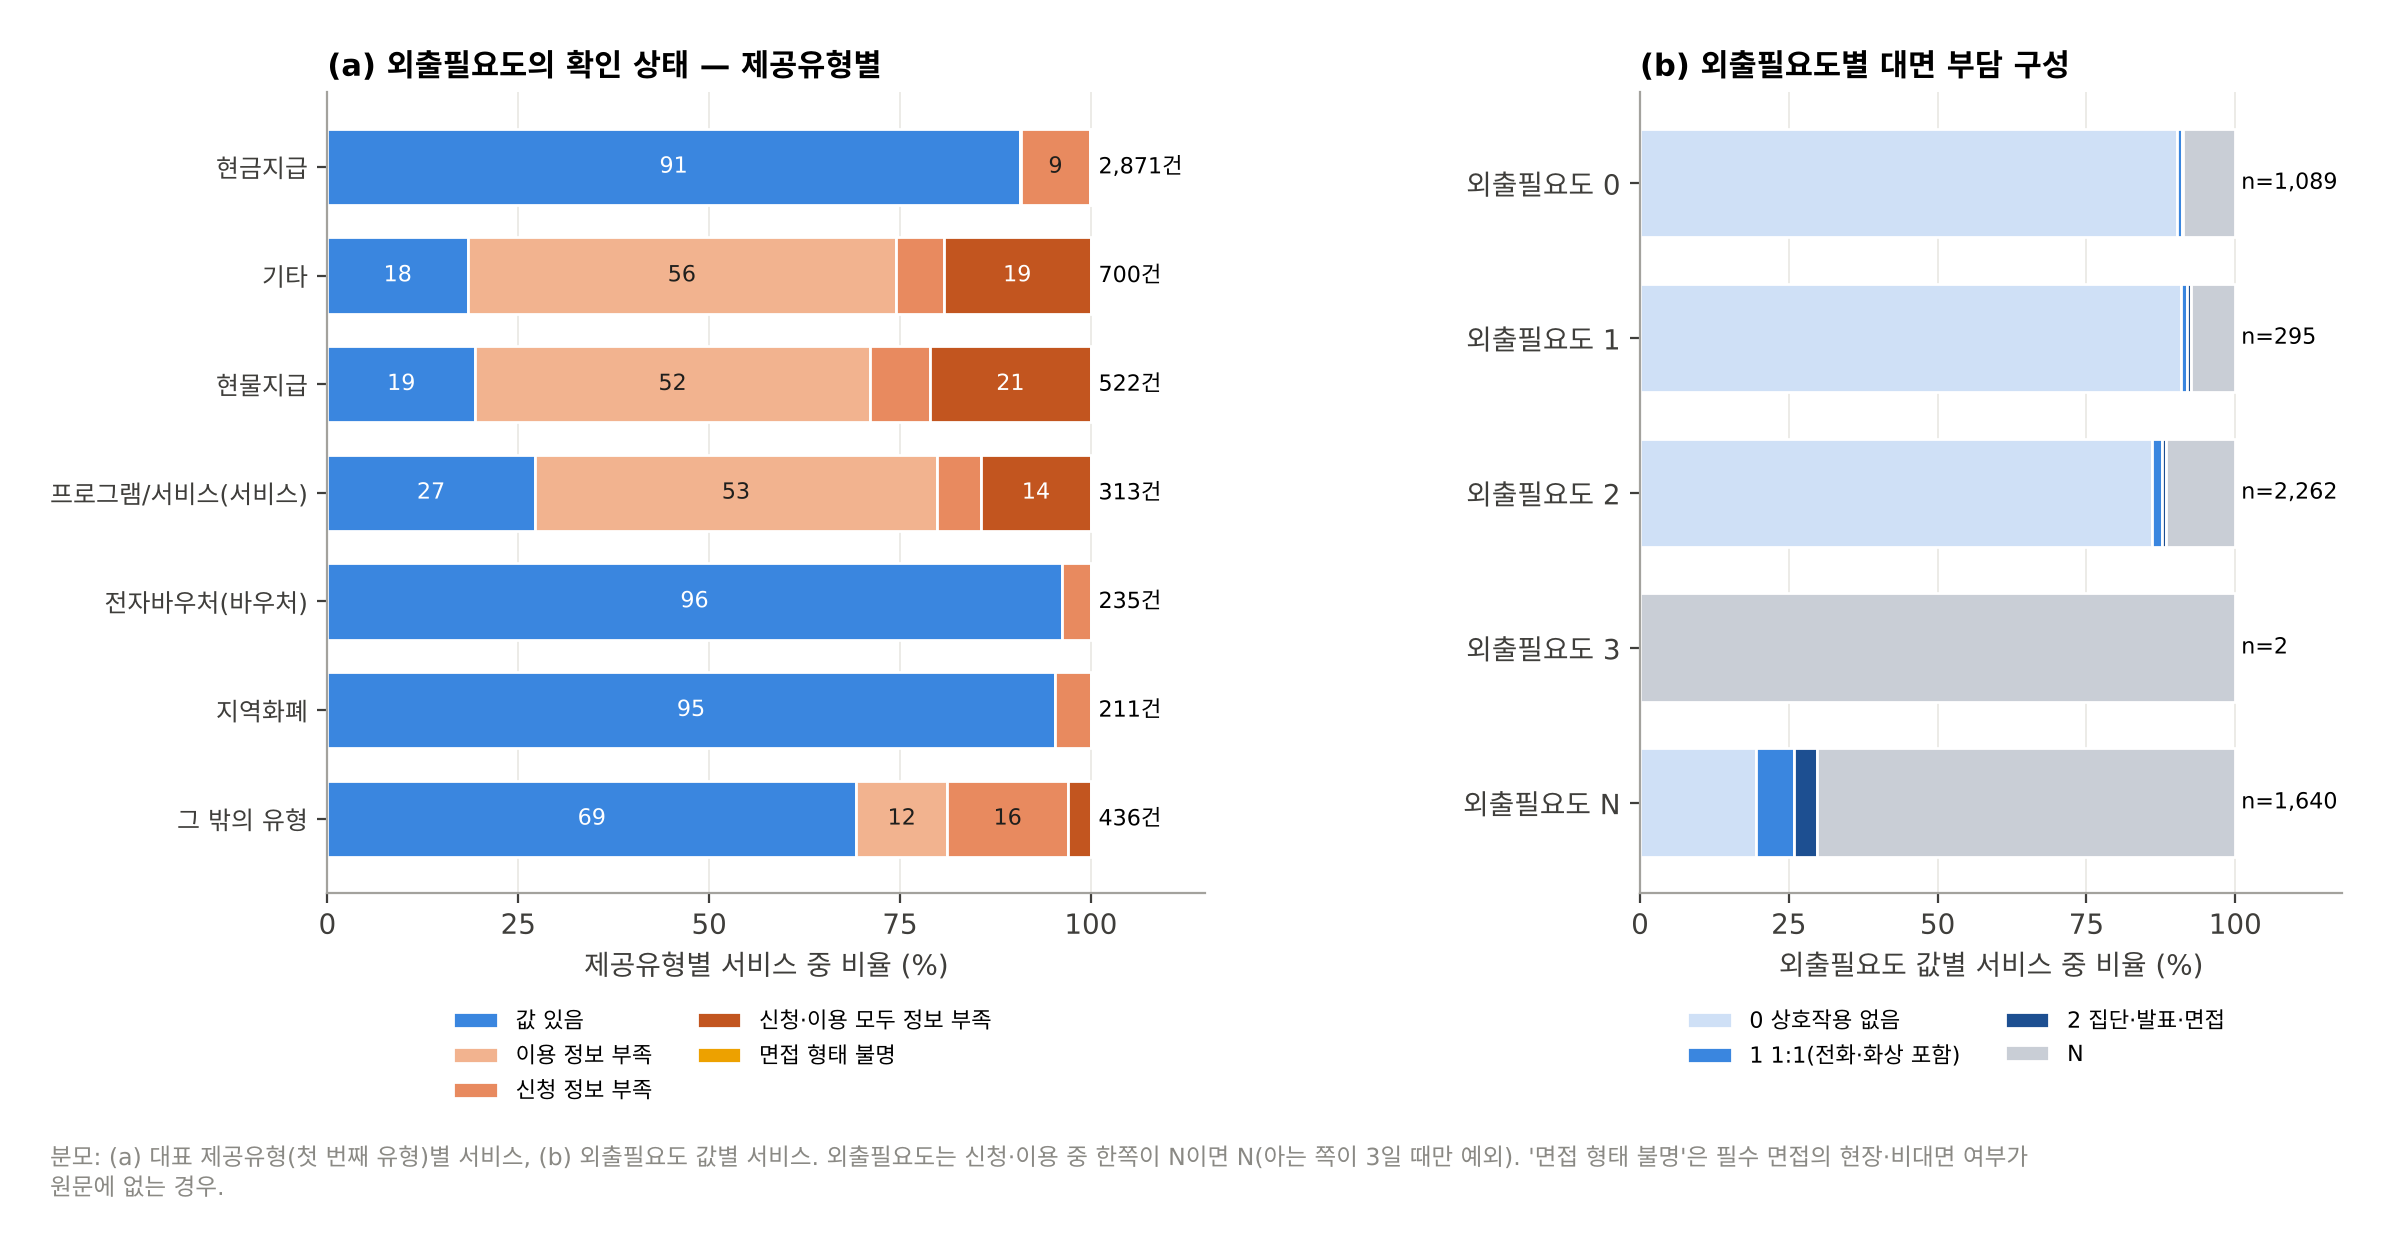

In [23]:
ON = m.outing_need.fillna("N")
cause = np.where(ON.ne("N"), "값 있음", np.where(m.apply_barrier.eq("N") & m.use_outing.eq("N"), "신청·이용 모두 정보 부족",
        np.where(m.apply_barrier.eq("N"), "신청 정보 부족", np.where(m.use_outing.eq("N"), "이용 정보 부족", "면접 형태 불명"))))
e["on_cause"] = cause
pt1 = m.provision_type.fillna("(결측)").str.split(", ").str[0]
top_pt = pt1.value_counts().head(6).index
e["ptype"] = np.where(pt1.isin(top_pt), pt1, "그 밖의 유형")
CAUSES = ["값 있음", "이용 정보 부족", "신청 정보 부족", "신청·이용 모두 정보 부족", "면접 형태 불명"]
ctab = pd.crosstab(e.ptype, e.on_cause).reindex(columns=CAUSES, fill_value=0)
ctab = ctab.loc[list(top_pt) + ["그 밖의 유형"]]
save_csv(ctab.reset_index(names="대표 제공유형"), "s2_outing_need_N_by_type")
CB = ["0", "1", "2", "N"]; CB_LAB = {"0": "0 상호작용 없음", "1": "1 1:1(전화·화상 포함)", "2": "2 집단·발표·면접", "N": "N"}
cb_ct = pd.crosstab(ON, m.contact_burden.fillna("N")).reindex(index=["0", "1", "2", "3", "N"], columns=CB, fill_value=0)
save_csv(cb_ct.rename(columns=CB_LAB).reset_index(names="외출필요도"), "s2_outing_need_x_contact")
fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.55})
sh = 100 * ctab.div(ctab.sum(axis=1), axis=0)
left = np.zeros(len(sh))
for c, col in zip(CAUSES, ["#3a86df", "#f2b38f", "#e88a5f", "#c2551f", "#eda100"]):
    ax.barh(range(len(sh)), sh[c], left=left, color=col, edgecolor="white", height=0.7, label=c)
    for i, (l, v) in enumerate(zip(left, sh[c])):
        if v >= 9: ax.text(l + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if c in ("값 있음", "신청·이용 모두 정보 부족") else INK)
    left += sh[c].to_numpy()
for i, n in enumerate(ctab.sum(axis=1)):
    ax.text(101, i, f"{n:,}건", va="center", fontsize=8)
ax.set_yticks(range(len(sh)), sh.index, fontsize=9); ax.invert_yaxis(); ax.set_xlim(0, 115); ax.grid(axis="y", visible=False)
ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xlabel("제공유형별 서비스 중 비율 (%)")
ax.set_title("(a) 외출필요도의 확인 상태 — 제공유형별")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.45, -0.12), fontsize=8)
sh2 = 100 * cb_ct.div(cb_ct.sum(axis=1).replace(0, np.nan), axis=0)
left = np.zeros(len(sh2))
for c, col in zip(CB, [LEVEL4[0], LEVEL4[2], LEVEL4[3], N_COLOR]):
    bx.barh(range(len(sh2)), sh2[c].fillna(0), left=left, color=col, edgecolor="white", height=0.7, label=CB_LAB[c])
    left += sh2[c].fillna(0).to_numpy()
for i, (k, n) in enumerate(cb_ct.sum(axis=1).items()):
    bx.text(101, i, f"n={n:,}", va="center", fontsize=8)
bx.set_yticks(range(len(sh2)), [f"외출필요도 {k}" for k in sh2.index]); bx.invert_yaxis(); bx.set_xlim(0, 118); bx.grid(axis="y", visible=False)
bx.set_xticks([0, 25, 50, 75, 100]); bx.set_xlabel("외출필요도 값별 서비스 중 비율 (%)")
bx.set_title("(b) 외출필요도별 대면 부담 구성")
bx.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.45, -0.12), fontsize=8)
f = show_fig(fig, "access", "outing_need_unknown_and_contact", "분모: (a) 대표 제공유형(첫 번째 유형)별 서비스, (b) 외출필요도 값별 서비스. 외출필요도는 신청·이용 중 한쪽이 N이면 N(아는 쪽이 3일 때만 예외). "
             "'면접 형태 불명'은 필수 면접의 현장·비대면 여부가 원문에 없는 경우.")

In [24]:
nN = int(ON.eq("N").sum()); worst = sh["값 있음"].sort_values().index[0]
low_contact = int(cb_ct.loc[["0", "1"], ["1", "2"]].to_numpy().sum()); low_tot = int(cb_ct.loc[["0", "1"]].to_numpy().sum())
low_cN = int(cb_ct.loc[["0", "1"], "N"].sum()); nN_cN = int(cb_ct.loc["N", "N"])
cash_ok = sh.loc[sh.index.str.contains("현금지급"), "값 있음"].max()
display(Markdown(f"""**발견.** 외출필요도 N {nN:,}건 중 '이용 정보 부족'이 {int((e.on_cause=='이용 정보 부족').sum()):,}건으로 가장 많다. 값이 확인된 비율은 현금지급형 {cash_ok:.0f}%에서 '{worst}' {sh.loc[worst, '값 있음']:.0f}%까지 차이가 크다.
외출필요도가 0~1인 서비스 {low_tot:,}건 중 대면 부담(1 이상)이 확인된 것은 {low_contact:,}건, 대면 부담이 N인 것은 {low_cN:,}건이다. 외출필요도 N {nN:,}건 중 {nN_cN:,}건({pct(nN_cN, nN):.0f}%)은 대면 부담도 N이라 정보 부족이 겹친다.

**왜 중요한가.** 외출필요도 N은 주로 '프로그램·기타' 같은 비현금 서비스에 몰려 있다. 은둔 청년에게 중요한 상담·활동형 서비스일수록 외출 조건을 원문으로 알기 어렵다는 뜻이며, STEP 02 사람 판정과 상세 페이지 확인이 필요한 곳이 여기다.
**단정할 수 없는 것.** 외출필요도가 낮다는 것은 원문상 외출 조건이 낮다는 뜻이지 전화·화상 상담 같은 대화 부담이 없다는 뜻이 아니다."""))

**발견.** 외출필요도 N 1,640건 중 '이용 정보 부족'이 882건으로 가장 많다. 값이 확인된 비율은 현금지급형 91%에서 '기타' 18%까지 차이가 크다.
외출필요도가 0~1인 서비스 1,384건 중 대면 부담(1 이상)이 확인된 것은 16건, 대면 부담이 N인 것은 117건이다. 외출필요도 N 1,640건 중 1,152건(70%)은 대면 부담도 N이라 정보 부족이 겹친다.

**왜 중요한가.** 외출필요도 N은 주로 '프로그램·기타' 같은 비현금 서비스에 몰려 있다. 은둔 청년에게 중요한 상담·활동형 서비스일수록 외출 조건을 원문으로 알기 어렵다는 뜻이며, STEP 02 사람 판정과 상세 페이지 확인이 필요한 곳이 여기다.
**단정할 수 없는 것.** 외출필요도가 낮다는 것은 원문상 외출 조건이 낮다는 뜻이지 전화·화상 상담 같은 대화 부담이 없다는 뜻이 아니다.

In [25]:
rows = []
for col, ko, k in ACC:
    d = m[col].fillna("N")
    r = {"라벨": ko}
    for v in [str(i) for i in range(4)] + ["N"]:
        r[v] = int(d.eq(v).sum()) if (v == "N" or int(v) < k) else np.nan
    r["N 비율(%)"] = pct(d.eq("N").sum(), len(d))
    r["중앙 N(%)"] = pct(m.loc[m.source.eq("central"), col].fillna("N").eq("N").sum(), N_SRC["central"])
    r["지자체 N(%)"] = pct(m.loc[m.source.eq("local"), col].fillna("N").eq("N").sum(), N_SRC["local"])
    r["필드 근거(%)"] = pct(m[f"{col}_method"].eq("field").sum(), len(d))
    rows.append(r)
acc_tbl = save_csv(pd.DataFrame(rows), "s2_access_summary")
show_table(acc_tbl, "표 2-1. 접근성 라벨 값별 건수와 N 비율 (전체 5,288건)",
           fmt={c: "{:,.0f}" for c in ["0", "1", "2", "3", "N"]} | {c: "{:.1f}" for c in ["N 비율(%)", "중앙 N(%)", "지자체 N(%)", "필드 근거(%)"]},
           highlight=["N 비율(%)"], note="— 는 그 라벨에 없는 값. '필드 근거'는 제공유형·신청 분류 등 구조화 필드로 정한 값의 비율.")

**표 2-1. 접근성 라벨 값별 건수와 N 비율 (전체 5,288건)**

라벨,0,1,2,3,N,N 비율(%),중앙 N(%),지자체 N(%),필드 근거(%)
신청 장벽,"1,345",520,"2,663",4,756,14.3,13.9,14.3,70.5
이용 장벽(기존),"3,693",35,384,65,"1,111",21.0,20.0,21.1,69.4
이용 외출 조건(신규),"3,254",623,224,2,"1,185",22.4,32.5,21.4,70.0
외출필요도(신규),"1,089",295,"2,262",2,"1,640",31.0,38.4,30.3,0.0
비대면 완결성,199,"2,273","1,255",—,"1,561",29.5,29.5,29.5,0.0
대면 부담,"3,518",152,82,—,"1,536",29.0,29.5,29.0,66.5
반복 부담,"1,736",0,161,—,"3,391",64.1,78.1,62.8,32.8


<span style='color:#8a8984;font-size:90%'>— 는 그 라벨에 없는 값. '필드 근거'는 제공유형·신청 분류 등 구조화 필드로 정한 값의 비율.</span>

# 3. Q2 준비 — 정보가 있다는 것과 충분하다는 것

지원대상·선정기준·지원내용·신청방법이 '비어 있지 않은' 비율은 대부분 높다. 그러나 '해당없음', '홈페이지 참조' 같은 형식 문구나 몇 글자짜리 값도 채워진 것으로 세어진다. 그래서 값을 네 수준(비어 있음 / 형식 문구 / 20자 미만 / 20자 이상)으로 나눠 본다.
보조금24는 SSIS와 수록 서비스가 달라 같은 모집단이 아니다. 아래 비교는 'DB별 정보 구조의 차이'이며, 같은 서비스의 정보 차이는 Q2 본 분석(서비스 매칭 후)에서 다룬다.

## 3-1. 필드별 정보 수준은 출처마다 어떻게 다른가?

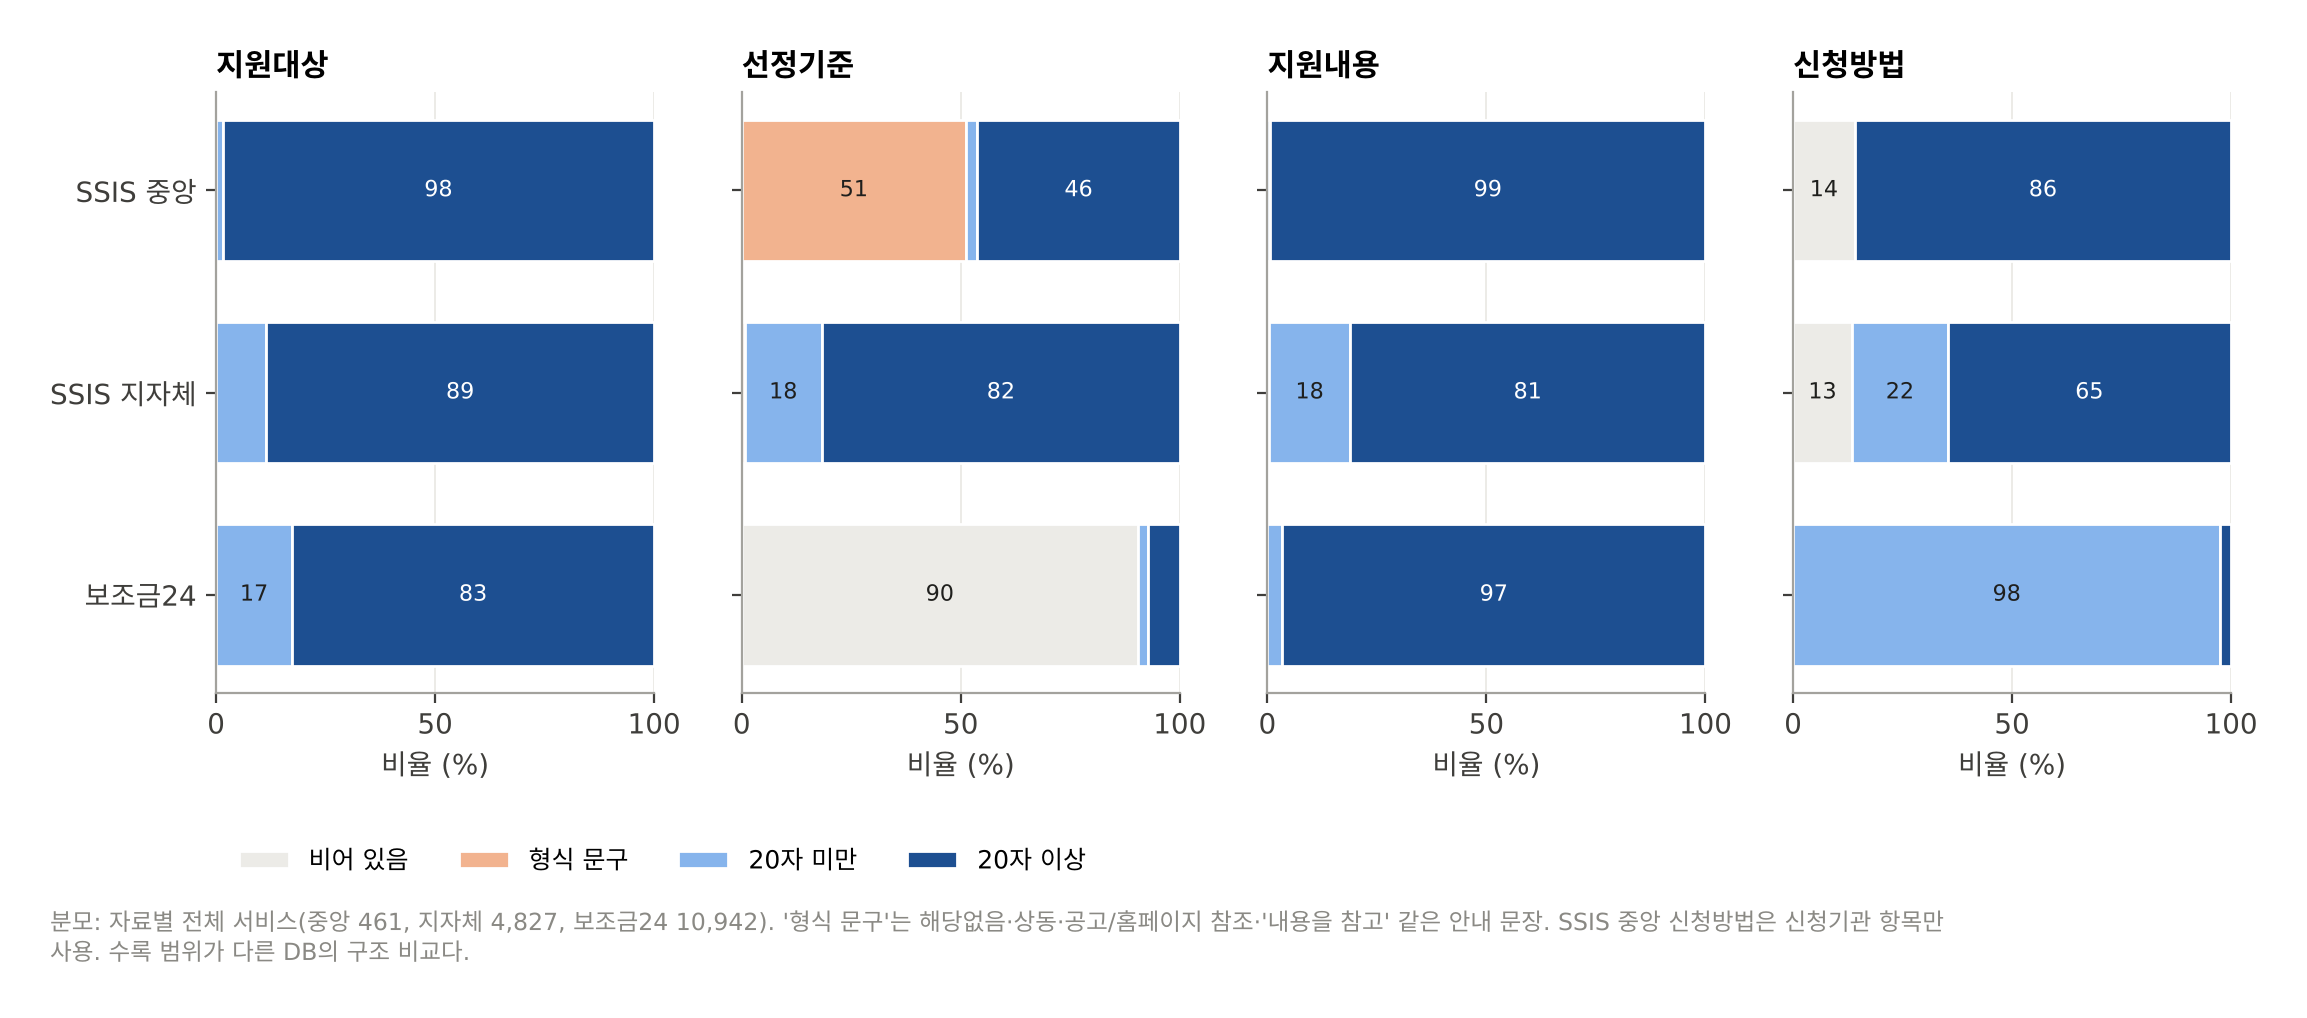

In [26]:
PLACEHOLDER = r"^\s*[-–·.]*\s*(해당\s*(사항)?\s*없음|없음|상동|별도\s*공고|공고\s*(참조|참고)|홈페이지\s*(참조|참고)|.*내용을\s*참고(해\s*주시기\s*바랍니다)?|문의|추후\s*공지)\s*[.]?\s*$"
LEVELS = ["비어 있음", "형식 문구", "20자 미만", "20자 이상"]
LV_COL = [NA_COLOR, "#f2b38f", "#86b4ec", "#1d4f91"]

def level(s):
    s = s.fillna("").astype(str).str.strip()
    return pd.Series(np.select([s.eq(""), s.str.fullmatch(PLACEHOLDER), s.str.len().lt(20)], LEVELS[:3], LEVELS[3]), index=s.index)

QF = [("지원대상", "target_text", "지원대상"), ("선정기준", "criteria_text", "선정기준"), ("지원내용", "benefit_text", "지원내용"), ("신청방법", "apply_text", "신청방법")]
rows = []
for label, sc, gc in QF:
    for s in ["central", "local"]:
        lv = level(m.loc[m.source.eq(s), sc])
        for L in LEVELS:
            rows.append({"필드": label, "자료": SRC_KO[s], "수준": L, "건수": int(lv.eq(L).sum()), "분모": len(lv)})
    if gov is not None:
        lv = level(gov[gc])
        for L in LEVELS:
            rows.append({"필드": label, "자료": SRC_KO["gov24"], "수준": L, "건수": int(lv.eq(L).sum()), "분모": len(lv)})
info = pd.DataFrame(rows); info["비율(%)"] = 100 * info["건수"] / info["분모"]
save_csv(info, "s3_information_level")
datasets = [SRC_KO["central"], SRC_KO["local"]] + ([SRC_KO["gov24"]] if gov is not None else [])
fig, axes = plt.subplots(1, len(QF), figsize=(13, 3.9), sharey=True)
for ax, (label, _, _) in zip(axes, QF):
    d = info[info["필드"].eq(label)]
    left = np.zeros(len(datasets))
    for L, col in zip(LEVELS, LV_COL):
        v = d[d["수준"].eq(L)].set_index("자료").loc[datasets, "비율(%)"].to_numpy()
        ax.barh(range(len(datasets)), v, left=left, color=col, edgecolor="white", height=0.7, label=L)
        for i, (l, p) in enumerate(zip(left, v)):
            if p >= 12: ax.text(l + p / 2, i, f"{p:.0f}", ha="center", va="center", fontsize=8, color="white" if col == LV_COL[3] else INK)
        left += v
    ax.set_title(label); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False); ax.set_xticks([0, 50, 100]); ax.set_xlabel("비율 (%)")
axes[0].set_yticks(range(len(datasets)), [f"{d_}" for d_ in datasets]); axes[0].invert_yaxis()
axes[0].legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.22))
f = show_fig(fig, "q2", "information_level", f"분모: 자료별 전체 서비스(중앙 {N_SRC['central']:,}, 지자체 {N_SRC['local']:,}" + (f", 보조금24 {len(gov):,}" if gov is not None else "") +
             "). '형식 문구'는 해당없음·상동·공고/홈페이지 참조·'내용을 참고' 같은 안내 문장. SSIS 중앙 신청방법은 신청기관 항목만 사용. 수록 범위가 다른 DB의 구조 비교다.")

In [27]:
def lvp(field, ds, L):
    r = info[(info["필드"].eq(field)) & (info["자료"].eq(ds)) & (info["수준"].eq(L))]
    return r["비율(%)"].iloc[0] if len(r) else np.nan
form_c = lvp("선정기준", SRC_KO["central"], "형식 문구"); short_l = lvp("선정기준", SRC_KO["local"], "20자 미만") + lvp("선정기준", SRC_KO["local"], "형식 문구")
gtxt = f" 보조금24는 선정기준이 비어 있는 비율이 {lvp('선정기준', SRC_KO['gov24'], '비어 있음'):.0f}%로, 이 DB에서 선정기준은 별도 필드보다 지원대상 문장에 섞여 있을 가능성이 있다." if gov is not None else ""
display(Markdown(f"""**발견.** SSIS의 네 필드는 비어 있는 경우가 거의 없지만, 중앙 선정기준의 {form_c:.0f}%는 '지원대상의 내용을 참고' 같은 형식 문구이고, 지자체 선정기준은 {short_l:.0f}%가 형식 문구이거나 20자 미만이다.{gtxt}

**왜 중요한가.** 명시율만 보면 SSIS 정보가 충분해 보이지만, 선정기준처럼 실제 판단 근거가 다른 필드에 위임된 경우가 많다. Q2에서 '정보 불완전'을 측정할 때는 비결측률이 아니라 내용 수준을 기준으로 해야 한다.
**단정할 수 없는 것.** 20자 이상이라도 정확하거나 충분하다는 보장은 없다. 같은 서비스의 DB 간 차이는 매칭 후에만 말할 수 있다."""))

**발견.** SSIS의 네 필드는 비어 있는 경우가 거의 없지만, 중앙 선정기준의 51%는 '지원대상의 내용을 참고' 같은 형식 문구이고, 지자체 선정기준은 18%가 형식 문구이거나 20자 미만이다. 보조금24는 선정기준이 비어 있는 비율이 90%로, 이 DB에서 선정기준은 별도 필드보다 지원대상 문장에 섞여 있을 가능성이 있다.

**왜 중요한가.** 명시율만 보면 SSIS 정보가 충분해 보이지만, 선정기준처럼 실제 판단 근거가 다른 필드에 위임된 경우가 많다. Q2에서 '정보 불완전'을 측정할 때는 비결측률이 아니라 내용 수준을 기준으로 해야 한다.
**단정할 수 없는 것.** 20자 이상이라도 정확하거나 충분하다는 보장은 없다. 같은 서비스의 DB 간 차이는 매칭 후에만 말할 수 있다.

## 3-2. 원문 분량은 어떻게 분포하고, 자주 반복되는 짧은 문구는 무엇인가?

상자그림은 분포의 꼬리를 감추므로, 필드별 누적 분포(ECDF)로 '몇 글자 이하인 서비스가 몇 %인지'를 직접 읽게 한다.

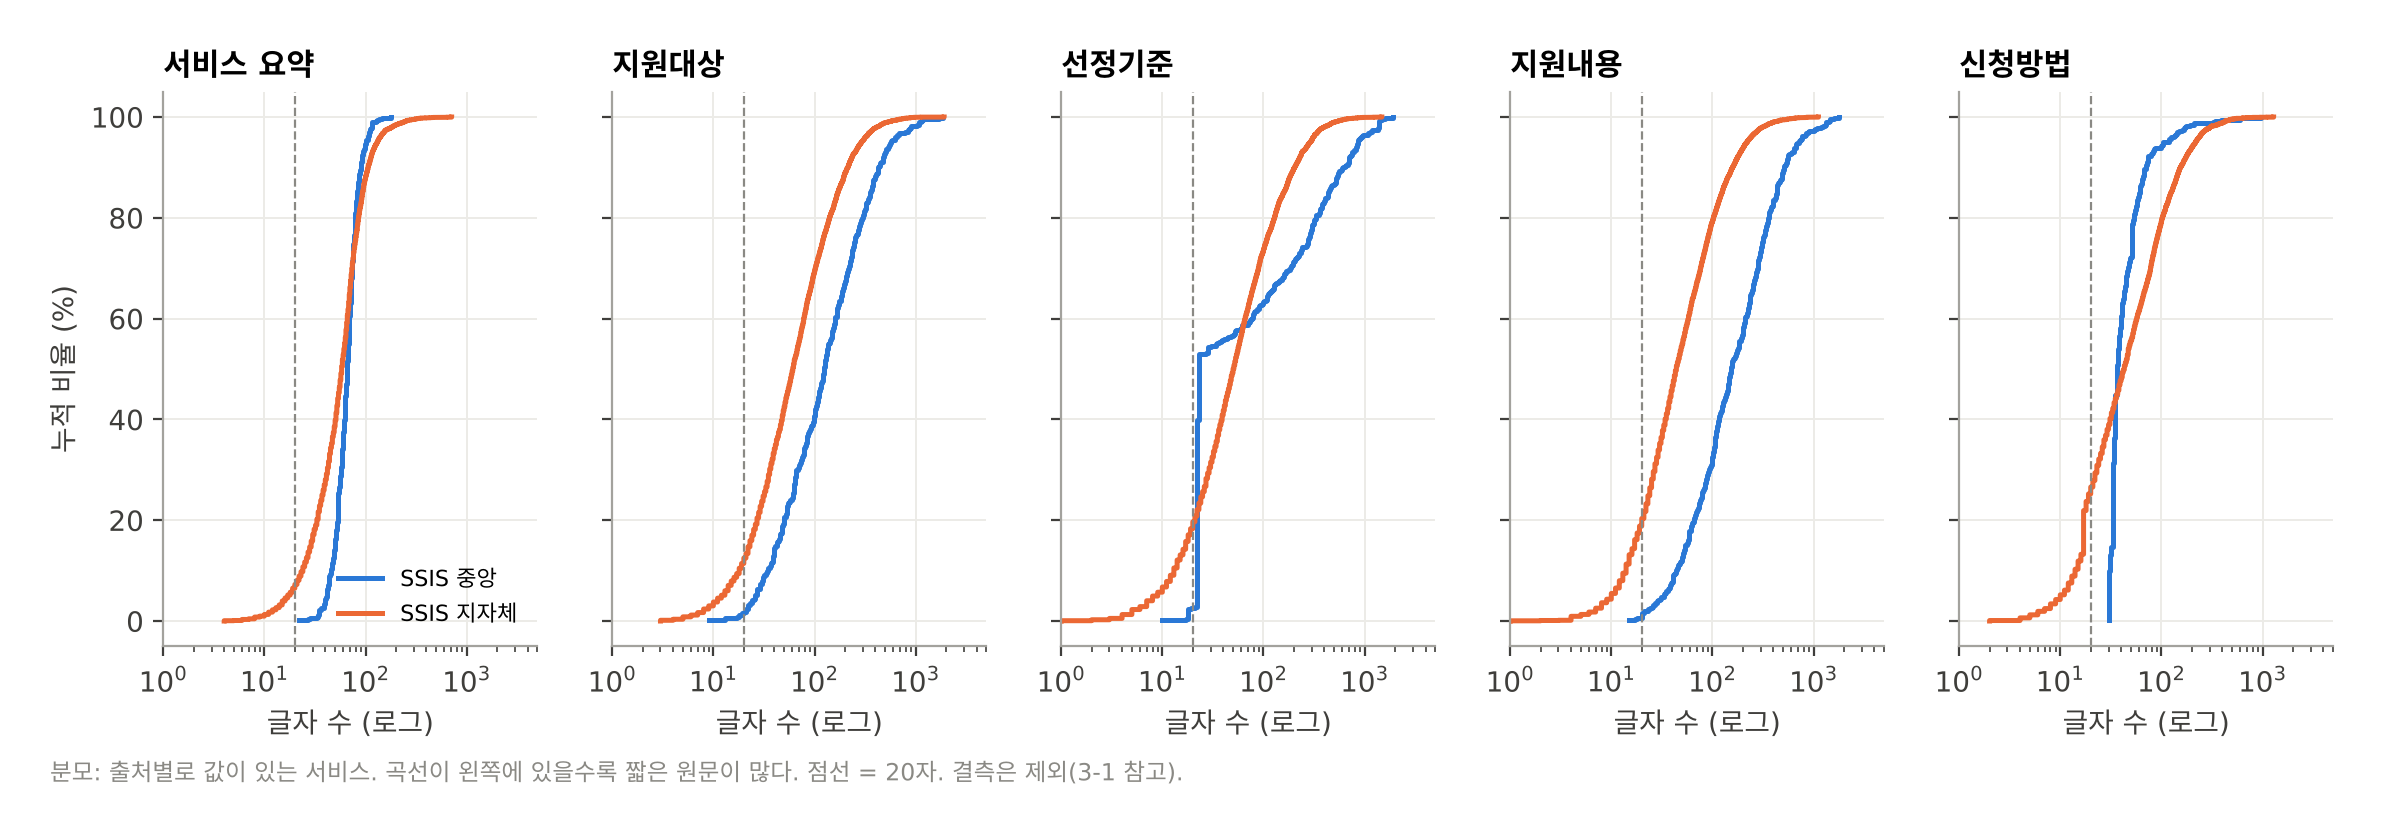

**표 3-1. 원문 필드 길이 요약 (글자 수)**

필드,출처,값 있는 서비스,10%,중앙값,90%,20자 미만(%),"1,000자 이상(%)"
서비스 요약,SSIS 중앙,461,46,65,90,0.0,0.0
서비스 요약,SSIS 지자체,"4,827",24,58,106,6.5,0.0
지원대상,SSIS 중앙,461,35,125,429,1.5,1.7
지원대상,SSIS 지자체,"4,827",18,61,213,11.4,0.1
선정기준,SSIS 중앙,461,22,23,617,2.6,3.5
선정기준,SSIS 지자체,"4,827",13,50,203,18.3,0.1
지원내용,SSIS 중앙,461,44,154,512,0.7,2.8
지원내용,SSIS 지자체,"4,827",14,44,158,18.9,0.0
신청방법,SSIS 중앙,396,31,36,70,0.0,0.0
신청방법,SSIS 지자체,"4,177",14,43,154,25.2,0.0


In [28]:
TXT = [("서비스 요약", "summary_text"), ("지원대상", "target_text"), ("선정기준", "criteria_text"), ("지원내용", "benefit_text"), ("신청방법", "apply_text")]
fig, axes = plt.subplots(1, len(TXT), figsize=(14, 3.6), sharey=True)
len_rows = []
for ax, (label, col) in zip(axes, TXT):
    for s in ["central", "local"]:
        L = m.loc[m.source.eq(s), col].fillna("").str.len()
        L = L[L > 0].sort_values()
        ax.step(L.values, np.arange(1, len(L) + 1) / len(L) * 100, where="post", color=C_SRC[s], lw=1.8, label=SRC_KO[s])
        len_rows.append({"필드": label, "출처": SRC_KO[s], "값 있는 서비스": len(L), "10%": L.quantile(.1), "중앙값": L.median(), "90%": L.quantile(.9),
                         "20자 미만(%)": pct((L < 20).sum(), len(L)), "1,000자 이상(%)": pct((L >= 1000).sum(), len(L))})
    ax.set_xscale("log"); ax.set_xlim(1, 5000); ax.axvline(20, color=MUTED, lw=0.8, ls="--")
    ax.set_title(label); ax.set_xlabel("글자 수 (로그)")
axes[0].set_ylabel("누적 비율 (%)"); axes[0].legend(loc="lower right", fontsize=8)
f = show_fig(fig, "q2", "text_length_ecdf", "분모: 출처별로 값이 있는 서비스. 곡선이 왼쪽에 있을수록 짧은 원문이 많다. 점선 = 20자. 결측은 제외(3-1 참고).")
length_tbl = save_csv(pd.DataFrame(len_rows), "s3_text_length")
show_table(length_tbl, "표 3-1. 원문 필드 길이 요약 (글자 수)", fmt={"값 있는 서비스": "{:,.0f}", "10%": "{:,.0f}", "중앙값": "{:,.0f}", "90%": "{:,.0f}",
           "20자 미만(%)": "{:.1f}", "1,000자 이상(%)": "{:.1f}"}, highlight=["20자 미만(%)"])

In [29]:
rows = []
for label, col in TXT[1:]:
    s = m[col].fillna("").str.strip()
    s = s[(s != "") & (s.str.len() < 30)]
    for txt, n in s.value_counts().head(4).items():
        rows.append({"필드": label, "자주 나오는 짧은 값": txt, "서비스 수": n})
short_tbl = save_csv(pd.DataFrame(rows), "s3_frequent_short_values")
show_table(short_tbl, "표 3-2. 30자 미만 값 중 가장 자주 반복되는 문구 (필드별 상위 4개)", fmt={"서비스 수": "{:,.0f}"}, bar=["서비스 수"],
           note="같은 문구가 수백 건 반복되면 그 필드는 서비스마다 다른 정보를 담고 있지 않다는 뜻이다.")
med = length_tbl.set_index(["필드", "출처"])["중앙값"]
display(Markdown(f"""**발견.** 지원내용 중앙값은 중앙 {med[('지원내용', SRC_KO['central'])]:,.0f}자, 지자체 {med[('지원내용', SRC_KO['local'])]:,.0f}자로 중앙이 더 길다. 선정기준과 신청방법은 짧은 값이 많고, 표 3-2처럼 같은 안내 문구가 대량 반복된다.

**왜 중요한가.** 짧고 반복되는 필드는 서비스를 구별하는 정보가 거의 없어, 검색·LLM 라벨링에서 근거로 쓰기 어렵다. 반대로 1,000자 이상의 긴 원문은 여러 하위 사업을 나열한 경우가 많아 규칙 라벨의 오탐 원인이 된다(STEP 00 검토 사례)."""))

**표 3-2. 30자 미만 값 중 가장 자주 반복되는 문구 (필드별 상위 4개)**

필드,자주 나오는 짧은 값,서비스 수
지원대상,행려자,5
지원대상,거리노숙인,4
지원대상,국가보훈대상자,4
지원대상,가정위탁아동,4
선정기준,지원대상의 내용을 참고해주시기 바랍니다.,171
선정기준,지원대상의 내용을 참고해 주시기 바랍니다.,59
선정기준,해당없음,21
선정기준,국가보훈대상자,12
지원내용,해당없음,15
지원내용,건강보험료 지원,5


<span style='color:#8a8984;font-size:90%'>같은 문구가 수백 건 반복되면 그 필드는 서비스마다 다른 정보를 담고 있지 않다는 뜻이다.</span>

**발견.** 지원내용 중앙값은 중앙 154자, 지자체 44자로 중앙이 더 길다. 선정기준과 신청방법은 짧은 값이 많고, 표 3-2처럼 같은 안내 문구가 대량 반복된다.

**왜 중요한가.** 짧고 반복되는 필드는 서비스를 구별하는 정보가 거의 없어, 검색·LLM 라벨링에서 근거로 쓰기 어렵다. 반대로 1,000자 이상의 긴 원문은 여러 하위 사업을 나열한 경우가 많아 규칙 라벨의 오탐 원인이 된다(STEP 00 검토 사례).

# 4. Q3 준비 — 검색이 놓칠 수 있는 데이터 특성

검색 실험 전에, 검색 대상 데이터 자체의 구조가 어떤 정보를 놓치게 만드는지 본다. 검색 성능 지표(재현율 등)는 계산하지 않는다.

## 4-1. '청년'이라는 근거는 어느 채널에 있는가?

청년 대상을 판단하는 정보는 생애주기 태그, 원문 '청년' 언급, 원문 연령 범위 세 곳에 흩어져 있다. 세 채널의 조합을 모두 세어, 한 채널만 쓰는 검색이 무엇을 놓치는지 본다.

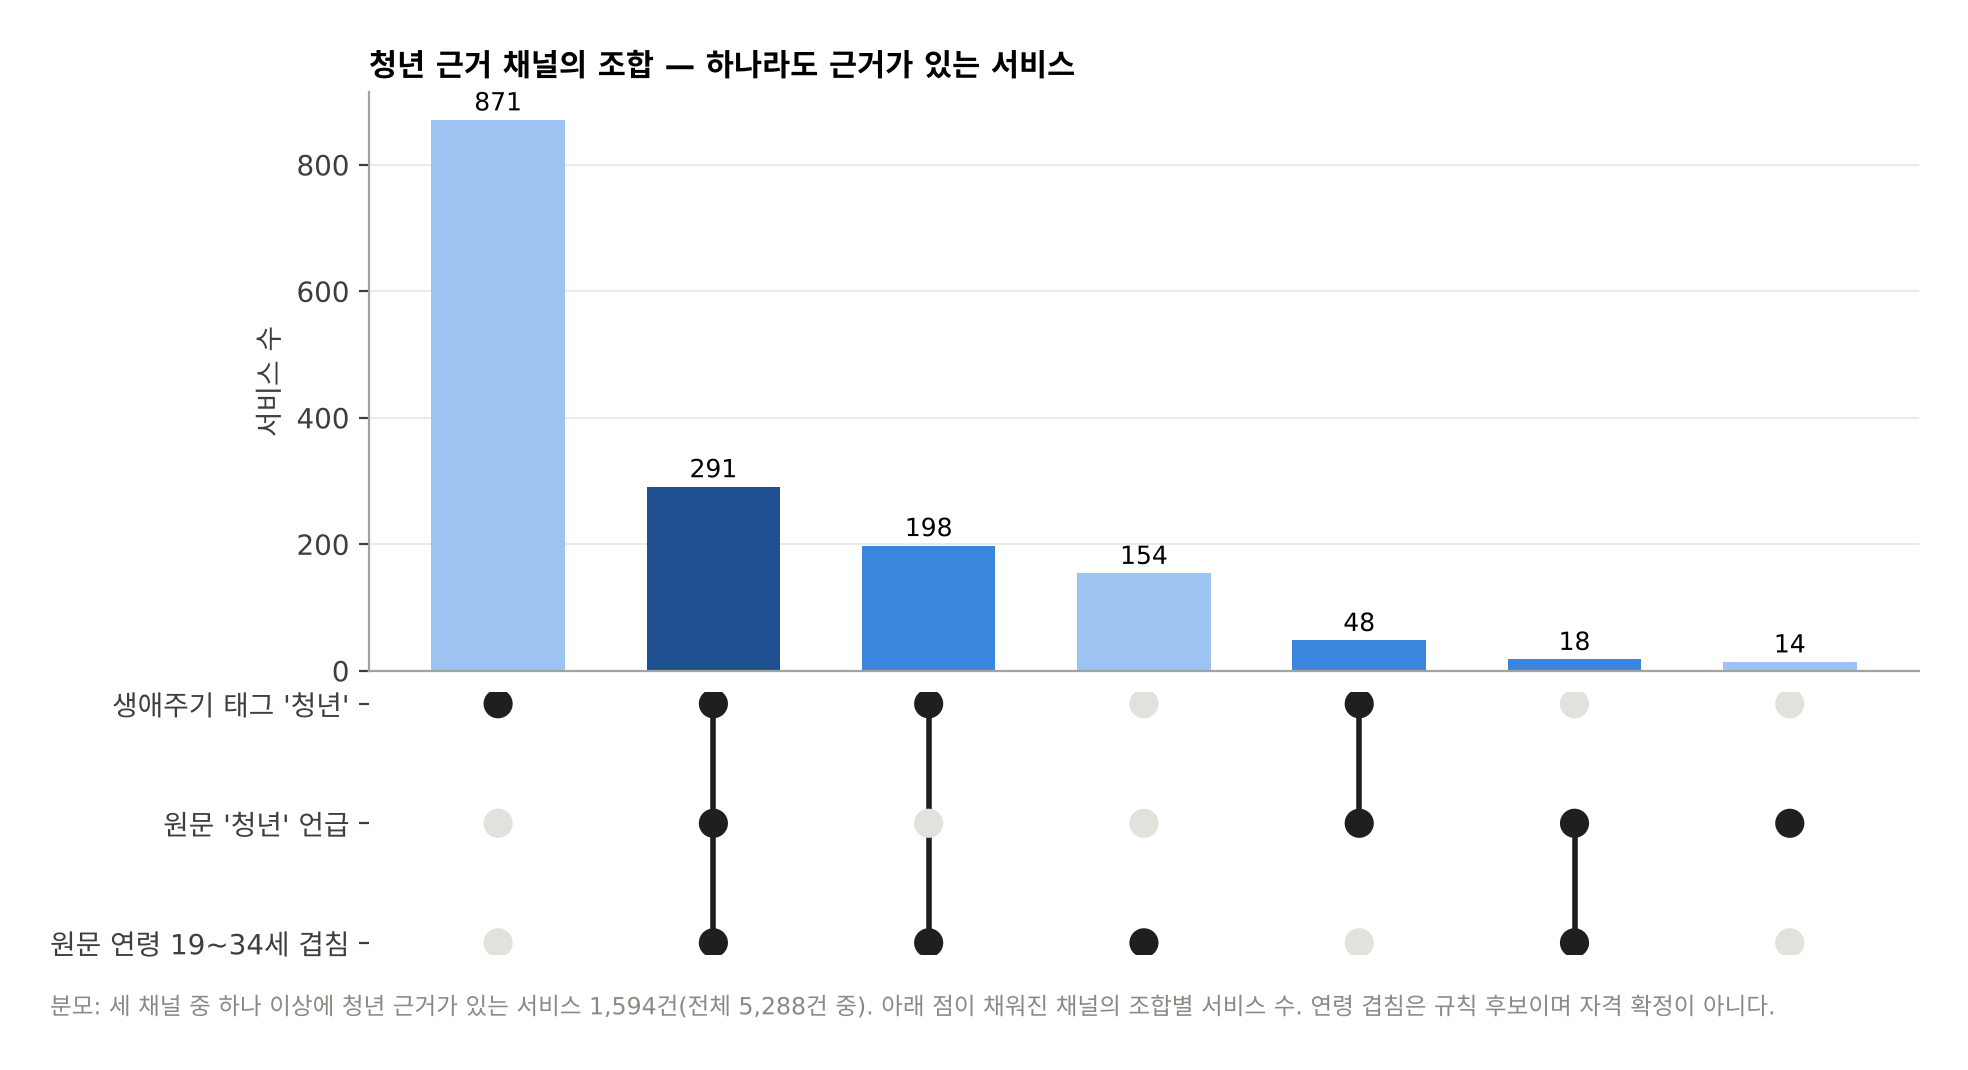

**발견.** 청년 근거가 있는 1,594건 중 세 채널이 모두 일치하는 서비스는 291건(18%)뿐이다. 태그에만 근거가 있는 서비스가 871건이고,
태그는 없지만 원문 언급이나 연령 범위로 청년 대상 가능성이 보이는 서비스가 186건이다.

**왜 중요한가.** 생애주기 태그로만 '청년 서비스'를 거르는 검색은 이 186건을 놓친다. 반대로 태그에만 있는 서비스는 원문에 청년 근거가 없어 결과 설명이 어렵다. Q3 검색 실험은 태그 기준과 원문 기준 결과를 나눠 비교해야 한다.

In [30]:
ch = pd.DataFrame({"태그": e.youth_tag, "원문 언급": e.youth_text, "연령 겹침": e.youth_age.eq("겹침")})
combo = ch.value_counts().rename("n").reset_index()
combo = combo[combo[["태그", "원문 언급", "연령 겹침"]].any(axis=1)].sort_values("n", ascending=False).reset_index(drop=True)
save_csv(combo, "s4_youth_channel_combinations")
fig = plt.figure(figsize=(10, 5.6))
gs = fig.add_gridspec(2, 1, height_ratios=[2.2, 1], hspace=0.05)
ax, dx = fig.add_subplot(gs[0]), fig.add_subplot(gs[1], sharex=None)
x = np.arange(len(combo))
cols_ = ["#1d4f91" if r.sum() == 3 else ("#3a86df" if r.sum() == 2 else "#9cc3f2") for r in combo[["태그", "원문 언급", "연령 겹침"]].to_numpy()]
ax.bar(x, combo.n, color=cols_, width=0.62)
for xi, n in zip(x, combo.n):
    ax.text(xi, n + 15, f"{n:,}", ha="center", fontsize=9)
ax.set_xticks([]); ax.set_ylabel("서비스 수"); ax.grid(axis="x", visible=False); ax.set_xlim(-0.6, len(combo) - 0.4)
ax.set_title("청년 근거 채널의 조합 — 하나라도 근거가 있는 서비스")
for i, c in enumerate(["태그", "원문 언급", "연령 겹침"]):
    on = combo[c].to_numpy()
    dx.scatter(x, [i] * len(x), s=90, color=np.where(on, INK, "#e2e1dc"), zorder=3)
for xi, r in zip(x, combo[["태그", "원문 언급", "연령 겹침"]].to_numpy()):
    idx = np.where(r)[0]
    if len(idx) > 1: dx.plot([xi, xi], [idx.min(), idx.max()], color=INK, lw=2)
dx.set_yticks(range(3), ["생애주기 태그 '청년'", "원문 '청년' 언급", "원문 연령 19~34세 겹침"]); dx.set_xticks([]); dx.invert_yaxis()
dx.grid(False); dx.set_xlim(-0.6, len(combo) - 0.4); [dx.spines[s].set_visible(False) for s in ["left", "bottom"]]
any_n = int(ch.any(axis=1).sum())
f = show_fig(fig, "q3", "youth_channel_upset", f"분모: 세 채널 중 하나 이상에 청년 근거가 있는 서비스 {any_n:,}건(전체 5,288건 중). 아래 점이 채워진 채널의 조합별 서비스 수. "
             "연령 겹침은 규칙 후보이며 자격 확정이 아니다.")
tag_only = int(combo[(combo["태그"]) & (~combo["원문 언급"]) & (~combo["연령 겹침"])].n.sum())
miss_tag = int(ch[~ch["태그"] & (ch["원문 언급"] | ch["연령 겹침"])].shape[0])
all3 = int(combo[combo[["태그", "원문 언급", "연령 겹침"]].all(axis=1)].n.sum())
display(Markdown(f"""**발견.** 청년 근거가 있는 {any_n:,}건 중 세 채널이 모두 일치하는 서비스는 {all3:,}건({pct(all3, any_n):.0f}%)뿐이다. 태그에만 근거가 있는 서비스가 {tag_only:,}건이고,
태그는 없지만 원문 언급이나 연령 범위로 청년 대상 가능성이 보이는 서비스가 {miss_tag:,}건이다.

**왜 중요한가.** 생애주기 태그로만 '청년 서비스'를 거르는 검색은 이 {miss_tag:,}건을 놓친다. 반대로 태그에만 있는 서비스는 원문에 청년 근거가 없어 결과 설명이 어렵다. Q3 검색 실험은 태그 기준과 원문 기준 결과를 나눠 비교해야 한다."""))

## 4-2. 검색어가 될 핵심 표현은 어느 필드에 있는가?

사용자는 '마음이 힘들다', '돈이 없다'처럼 말하지만, 검색은 대개 서비스명·요약을 먼저 본다. 은둔 청년의 주요 필요와 연결되는 표현이 서비스명·요약에 드러나는지, 본문에만 묻혀 있는지 본다.

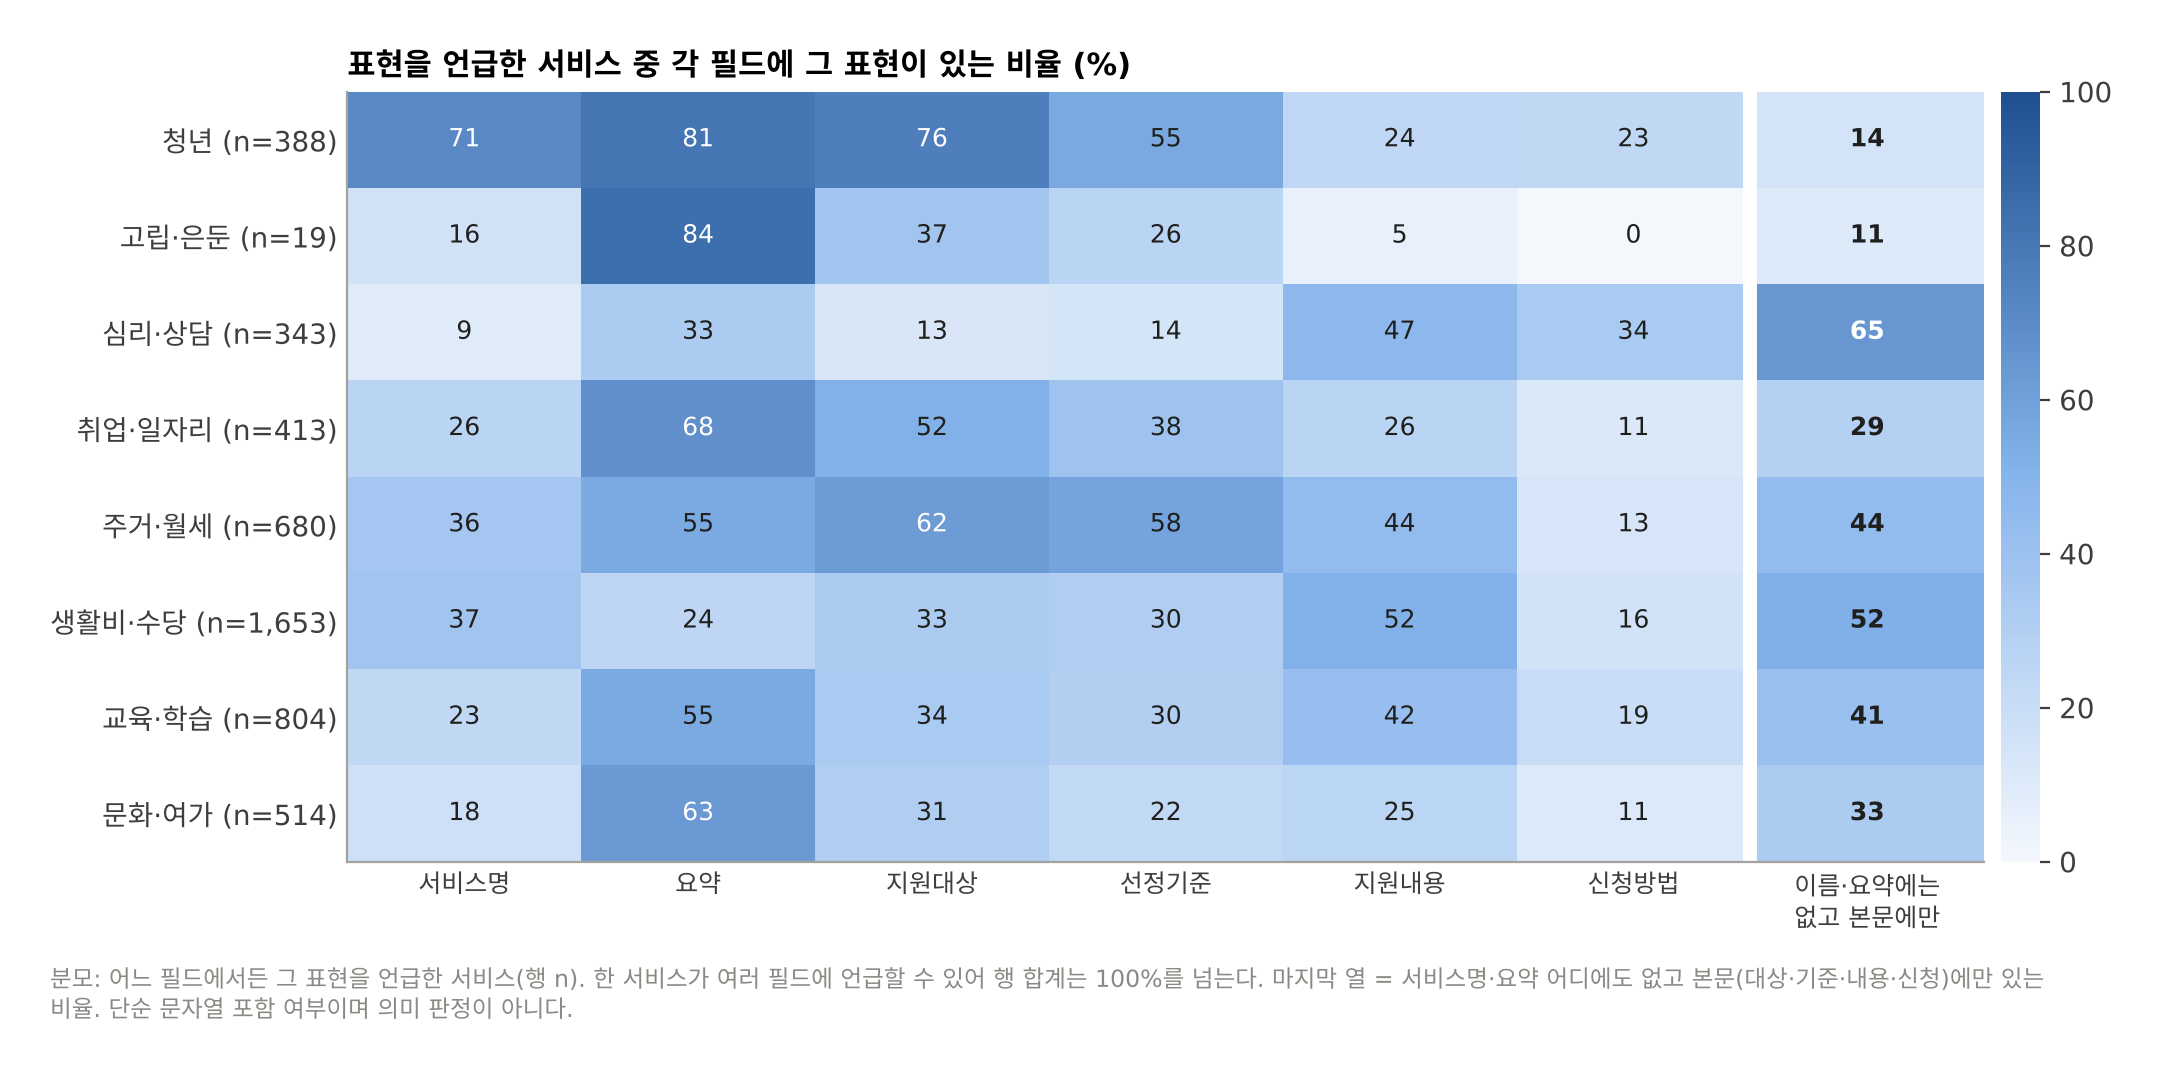

**발견.** '심리·상담'을 언급한 서비스의 65%, '생활비·수당'의 52%는 서비스명·요약에는 그 표현이 없고 본문에만 있다.
'청년'은 지원대상 필드에 주로 있어, 대상 조건 문장까지 읽어야 드러난다.

**왜 중요한가.** 서비스명·요약 중심의 검색은 본문에만 있는 필요 표현을 놓친다. Q3에서는 검색 대상 필드 범위(이름·요약 vs 전체 원문)를 실험 조건으로 두어야 하고, 앱은 본문까지 색인해야 한다.

In [31]:
TERMS = [("청년", r"청년"), ("고립·은둔", r"고립|은둔"), ("심리·상담", r"심리|상담|마음|정신\s*건강"), ("취업·일자리", r"취업|일자리|구직|일\s*경험"),
         ("주거·월세", r"주거|월세|전세|임대|주택"), ("생활비·수당", r"생활비|생계|수당|지원금"), ("교육·학습", r"교육|학습|강좌|자격증"),
         ("문화·여가", r"문화|여가|체육|취미")]
SF = [("서비스명", "servNm"), ("요약", "summary_text"), ("지원대상", "target_text"), ("선정기준", "criteria_text"), ("지원내용", "benefit_text"), ("신청방법", "apply_text")]
rows = []
for tlabel, rx in TERMS:
    hit = {f: m[c].fillna("").str.contains(rx) for f, c in SF}
    anyh = pd.concat(hit, axis=1).any(axis=1)
    nm = hit["서비스명"] | hit["요약"]
    r = {"표현": tlabel, "언급 서비스": int(anyh.sum())}
    for f, _ in SF:
        r[f] = pct((hit[f] & anyh).sum(), anyh.sum())
    r["이름·요약에 없음(%)"] = pct((anyh & ~nm).sum(), anyh.sum())
    rows.append(r)
terms = save_csv(pd.DataFrame(rows), "s4_term_field_location")
mat = terms.set_index("표현")[[f for f, _ in SF] + ["이름·요약에 없음(%)"]]
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(mat.values, cmap=BLUES, vmin=0, vmax=100, aspect="auto")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]; ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 60 else INK,
                                       fontweight="bold" if j == mat.shape[1] - 1 else "normal")
ax.axvline(len(SF) - 0.5, color="white", lw=5)
ax.set_xticks(range(mat.shape[1]), list(mat.columns[:-1]) + ["이름·요약에는\n없고 본문에만"], fontsize=9)
ax.set_yticks(range(len(mat)), [f"{t} (n={n:,})" for t, n in zip(terms["표현"], terms["언급 서비스"])])
ax.tick_params(length=0); ax.grid(False)
ax.set_title("표현을 언급한 서비스 중 각 필드에 그 표현이 있는 비율 (%)")
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01); cb.outline.set_visible(False)
f = show_fig(fig, "q3", "term_field_location", "분모: 어느 필드에서든 그 표현을 언급한 서비스(행 n). 한 서비스가 여러 필드에 언급할 수 있어 행 합계는 100%를 넘는다. "
             "마지막 열 = 서비스명·요약 어디에도 없고 본문(대상·기준·내용·신청)에만 있는 비율. 단순 문자열 포함 여부이며 의미 판정이 아니다.")
hid = terms.sort_values("이름·요약에 없음(%)", ascending=False)
display(Markdown(f"""**발견.** '{hid['표현'].iloc[0]}'을 언급한 서비스의 {hid['이름·요약에 없음(%)'].iloc[0]:.0f}%, '{hid['표현'].iloc[1]}'의 {hid['이름·요약에 없음(%)'].iloc[1]:.0f}%는 서비스명·요약에는 그 표현이 없고 본문에만 있다.
'청년'은 지원대상 필드에 주로 있어, 대상 조건 문장까지 읽어야 드러난다.

**왜 중요한가.** 서비스명·요약 중심의 검색은 본문에만 있는 필요 표현을 놓친다. Q3에서는 검색 대상 필드 범위(이름·요약 vs 전체 원문)를 실험 조건으로 두어야 하고, 앱은 본문까지 색인해야 한다."""))

## 4-3. 서비스명만으로 서비스를 구별할 수 있는가?

이름이 같은 서비스가 여러 지역에 반복되거나 이름이 짧고 포괄적이면, 검색 결과에서 사용자가 서비스를 구별하기 어렵다.

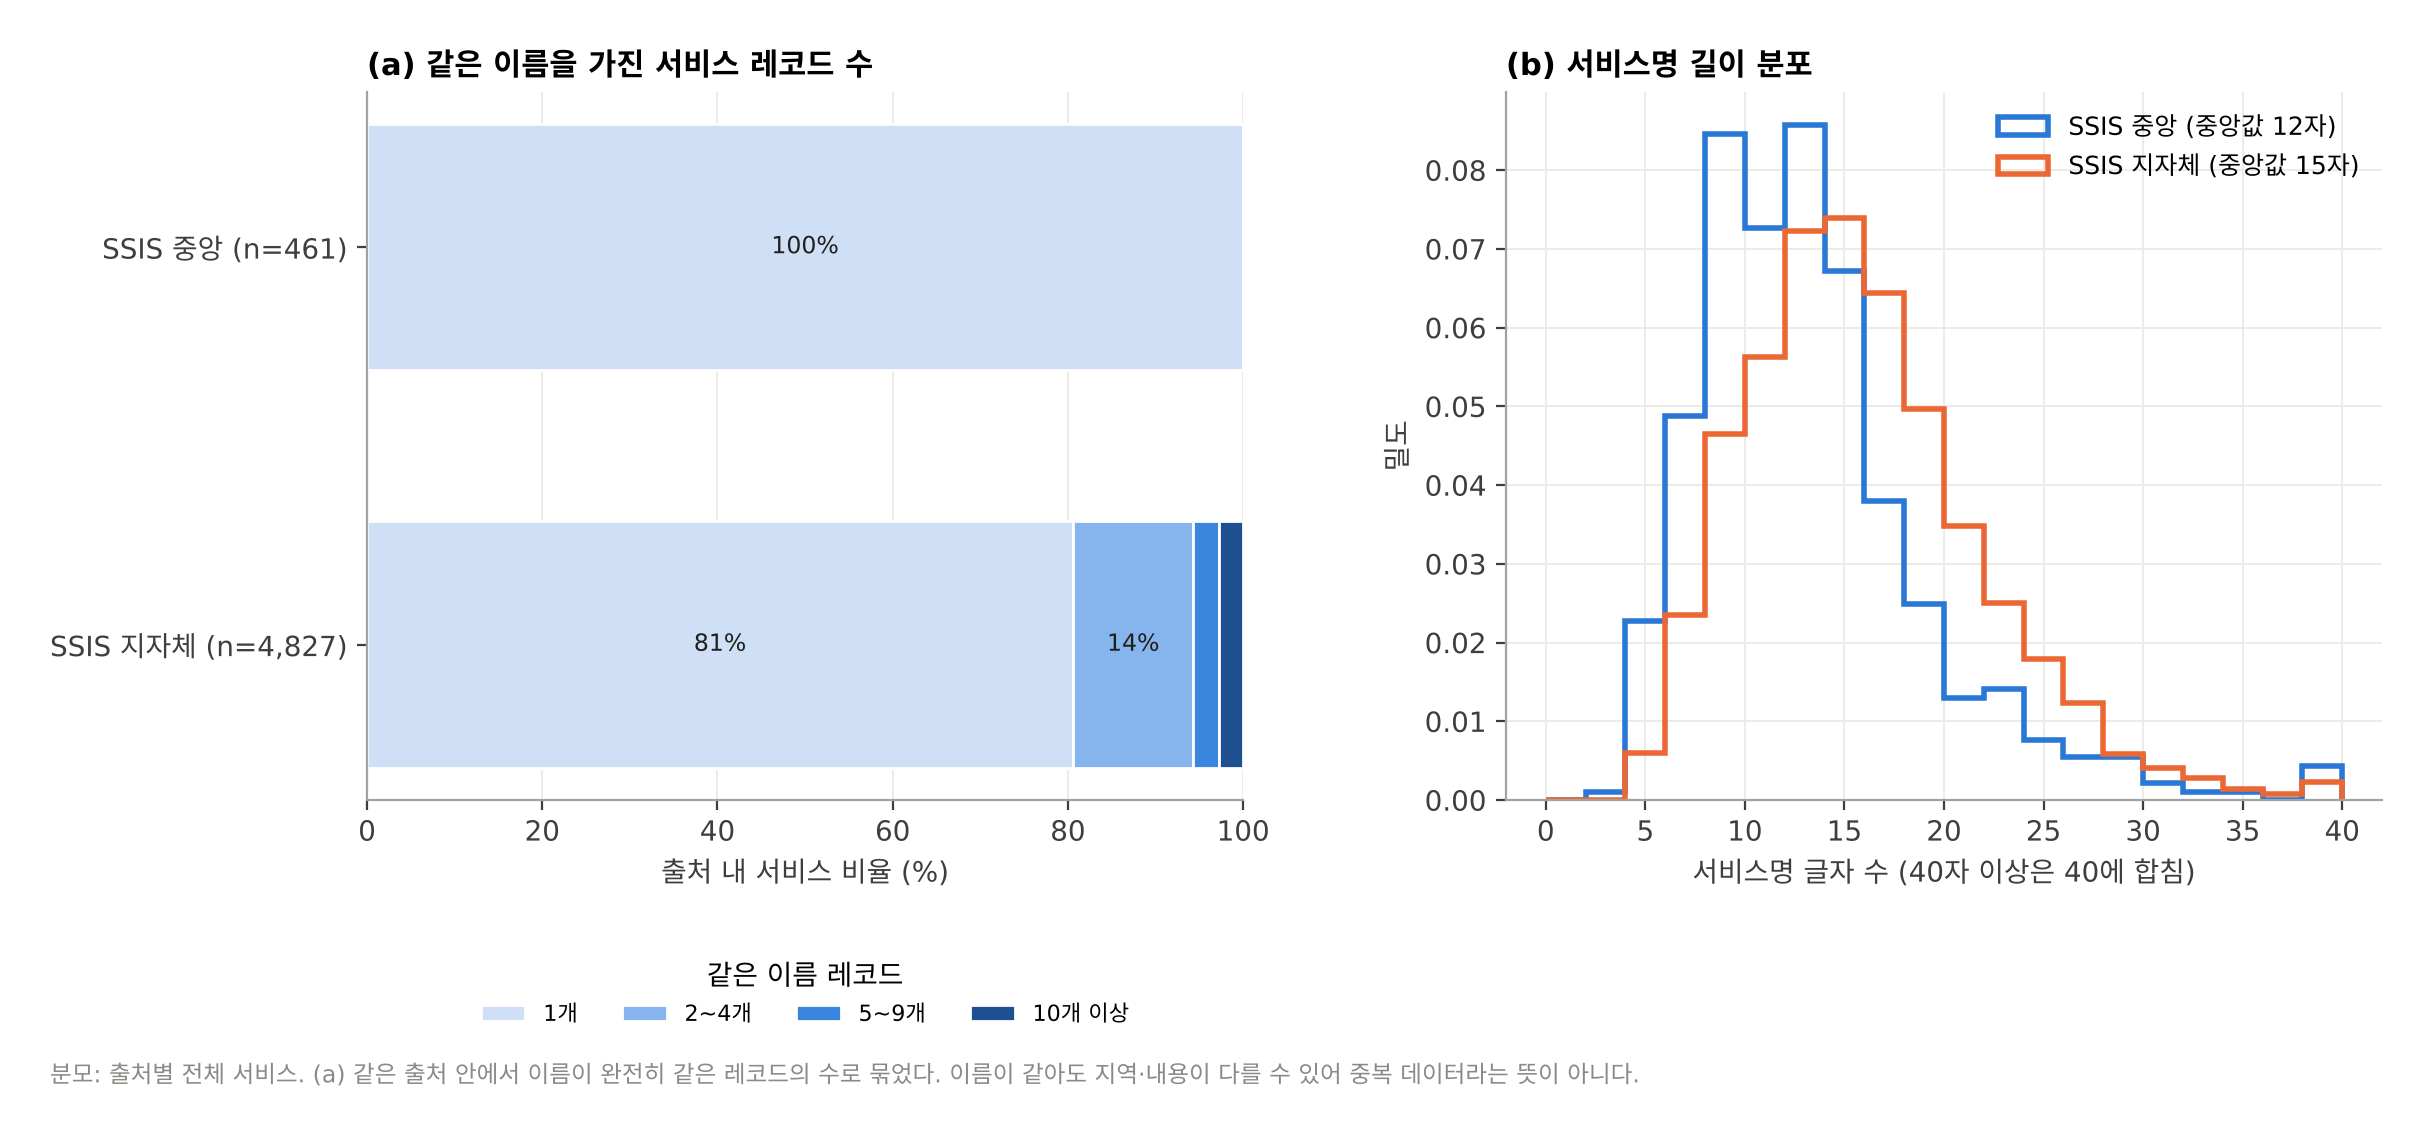

In [32]:
GENERIC = r"^(지원|사업|지원사업|서비스|운영|지급|수당|바우처|프로그램)$"
nm = m.servNm.fillna("")
e["name_len"] = nm.str.len()
size = m.groupby(["source", "servNm"]).servId.transform("count")
e["same_name"] = pd.cut(size, [0, 1, 4, 9, 10**6], labels=["1개", "2~4개", "5~9개", "10개 이상"])
fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"wspace": 0.3})
cats = ["1개", "2~4개", "5~9개", "10개 이상"]
for j, s in enumerate(["central", "local"]):
    d = e[m.source.eq(s)].same_name.value_counts(normalize=True).reindex(cats).fillna(0) * 100
    left = 0
    for c, col in zip(cats, ["#cfe0f6", "#86b4ec", "#3a86df", "#1d4f91"]):
        ax.barh(j, d[c], left=left, color=col, edgecolor="white", height=0.62, label=c if j == 0 else None)
        if d[c] >= 4: ax.text(left + d[c] / 2, j, f"{d[c]:.0f}%", ha="center", va="center", fontsize=8.5, color="white" if c in cats[2:] else INK)
        left += d[c]
ax.set_yticks([0, 1], [f"{SRC_KO[s]} (n={N_SRC[s]:,})" for s in ["central", "local"]]); ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("출처 내 서비스 비율 (%)"); ax.set_title("(a) 같은 이름을 가진 서비스 레코드 수")
ax.legend(title="같은 이름 레코드", ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
bins = np.arange(0, 42, 2)
for s in ["central", "local"]:
    L = e.loc[m.source.eq(s), "name_len"].clip(upper=40)
    bx.hist(L, bins=bins, density=True, histtype="step", lw=2, color=C_SRC[s], label=f"{SRC_KO[s]} (중앙값 {e.loc[m.source.eq(s), 'name_len'].median():.0f}자)")
bx.set_xlabel("서비스명 글자 수 (40자 이상은 40에 합침)"); bx.set_ylabel("밀도"); bx.set_title("(b) 서비스명 길이 분포"); bx.legend()
f = show_fig(fig, "q3", "service_name_quality", "분모: 출처별 전체 서비스. (a) 같은 출처 안에서 이름이 완전히 같은 레코드의 수로 묶었다. 이름이 같아도 지역·내용이 다를 수 있어 중복 데이터라는 뜻이 아니다.")

In [33]:
loc = m.source.eq("local")
exact_names = m[loc].servNm.nunique(); norm_names = e.loc[loc, "name_norm"].nunique()
q_rows = [
    ("지자체 서비스 수", N_SRC["local"], "레코드"),
    ("지자체 고유 서비스명", exact_names, "이름"),
    ("지역명 제거 후 고유 이름 (보조 지표)", norm_names, "이름"),
    ("이름이 2건 이상 반복되는 지자체 서비스", int((e.loc[loc, "same_name"] != "1개").sum()), "레코드"),
    ("서비스명 10자 이하 (전체)", int(e.name_len.le(10).sum()), "레코드"),
    ("서비스명에 대상 표현이 없는 서비스 (전체)", int((~nm.str.contains(r"청년|노인|어르신|아동|청소년|장애|여성|임산부|출산|가구|가정|학생|보훈|유공자|농업인|저소득|한부모|다문화")).sum()), "레코드"),
]
name_q = pd.DataFrame(q_rows, columns=["지표", "값", "단위"])
name_q["전체 대비(%)"] = [np.nan, pct(exact_names, N_SRC["local"]), pct(norm_names, N_SRC["local"]), pct(q_rows[3][1], N_SRC["local"]), pct(q_rows[4][1], len(m)), pct(q_rows[5][1], len(m))]
save_csv(name_q, "s4_name_quality")
show_table(name_q, "표 4-1. 서비스명의 검색 입력 품질", fmt={"값": "{:,.0f}", "전체 대비(%)": "{:.1f}"},
           note="지역명 제거 후 고유 이름은 같은 사업이라고 확정된 수가 아니라 지역별 반복을 가늠하는 보조 지표. 대상 표현은 주요 대상 집단 단어 포함 여부만 본 단순 기준.")
display(Markdown(f"""**발견.** 지자체 {N_SRC['local']:,}건의 고유 서비스명은 {exact_names:,}개이고, 지역명을 지우면 {norm_names:,}개로 더 줄어든다. 서비스명 중앙값은 {e.name_len.median():.0f}자로 짧고,
서비스명만으로는 누구를 위한 서비스인지 알 수 없는 경우가 {pct(q_rows[5][1], len(m)):.0f}%다.

**왜 중요한가.** 같은 이름이 여러 지역에 반복되면 검색 결과에 지역·기관 정보를 함께 보여줘야 하고, 이름에 대상이 드러나지 않으면 대상 판단은 원문을 읽어야 한다. Q3의 '검색이 잘못 판단하는 경우'를 볼 때 이름 기반 매칭의 한계로 연결된다."""))

**표 4-1. 서비스명의 검색 입력 품질**

지표,값,단위,전체 대비(%)
지자체 서비스 수,"4,827",레코드,—
지자체 고유 서비스명,"4,187",이름,86.7
지역명 제거 후 고유 이름 (보조 지표),"3,697",이름,76.6
이름이 2건 이상 반복되는 지자체 서비스,937,레코드,19.4
서비스명 10자 이하 (전체),"1,172",레코드,22.2
서비스명에 대상 표현이 없는 서비스 (전체),"2,409",레코드,45.6


<span style='color:#8a8984;font-size:90%'>지역명 제거 후 고유 이름은 같은 사업이라고 확정된 수가 아니라 지역별 반복을 가늠하는 보조 지표. 대상 표현은 주요 대상 집단 단어 포함 여부만 본 단순 기준.</span>

**발견.** 지자체 4,827건의 고유 서비스명은 4,187개이고, 지역명을 지우면 3,697개로 더 줄어든다. 서비스명 중앙값은 14자로 짧고,
서비스명만으로는 누구를 위한 서비스인지 알 수 없는 경우가 46%다.

**왜 중요한가.** 같은 이름이 여러 지역에 반복되면 검색 결과에 지역·기관 정보를 함께 보여줘야 하고, 이름에 대상이 드러나지 않으면 대상 판단은 원문을 읽어야 한다. Q3의 '검색이 잘못 판단하는 경우'를 볼 때 이름 기반 매칭의 한계로 연결된다.

# 5. 핵심 발견과 후속 분석 연결

In [34]:
hs1 = dem.iloc[0]
key = pd.DataFrame([
    {"발견": "태그·분류값은 출처마다 비는 곳이 다르고, 지자체 관심주제는 '서민금융'에 편중",
     "근거": f"지자체 관심주제 태그 보유 서비스의 {100*len(seomin)/len(loc_tag):.0f}%가 서민금융", "영향": "Q1·Q3: 태그 기준 분류·검색 불가",
     "이번 데이터로 알 수 없는 것": "태그 편중의 원인", "후속 검증": "Q1은 원문 기반 영역 사용, Q3는 태그 기준과 원문 기준 비교"},
    {"발견": "은둔 청년의 필요는 경제·일·일상 회복에 집중되고 관계·집단 지원은 선호가 갈림",
     "근거": f"매우 필요 1위 {hs1['영역']} {hs1['은둔 매우 필요(%)']:.0f}%, 최저 {dem.iloc[-1]['영역']} {dem.iloc[-1]['은둔 매우 필요(%)']:.0f}%", "영향": "Q1 수요 순위",
     "이번 데이터로 알 수 없는 것": "모집단 비율(비가중·비확률)", "후속 검증": "'매우 필요'·'필요(3+4)' 두 순위로 Q1 대응 비교"},
    {"발견": "외출 정도·은둔 이유에 따라 필요한 지원 방향이 다름",
     "근거": f"하위 집단 간 '매우 필요' 범위가 영역마다 최대 {(rng['max']-rng['min']).max():.0f}%p", "영향": "앱 초기 필요 태그",
     "이번 데이터로 알 수 없는 것": "인과관계, 작은 하위 집단의 안정성", "후속 검증": "추천은 사용자 확인·수정 전제로 설계"},
    {"발견": "영역 후보는 경제적 지원(main + candidate)이 가장 많고 일부는 제공유형 필드만으로 붙음",
     "근거": f"⑩ 후보 {tot:,}건 중 필드만 {fo:,}건, ①②⑨ 후보 합계 {int(low.sum())}건", "영향": "Q1 공급 후보 해석",
     "이번 데이터로 알 수 없는 것": "후보가 적은 영역이 서비스 부재인지 규칙 누락인지", "후속 검증": "STEP 02 재현율로 누락 규모 추정 후 Q1 해석"},
    {"발견": "청년 대상 근거가 대부분 '연령 미상'",
     "근거": f"영역 후보 중 연령 겹침 비율 최고 {AREA[best.index[0]]} {best.iloc[0]:.0f}%", "영향": "Q1 청년 대상 범위",
     "이번 데이터로 알 수 없는 것": "전체 자격 충족 여부", "후속 검증": "하한(겹침)·상한(겹침+미상) 병기"},
    {"발견": "신청과 이용의 외출 조건이 자주 다르고, 비현금 서비스일수록 외출필요도를 알 수 없음",
     "근거": f"온라인 신청 서비스의 {pct(on_mis, ct.loc['0'].sum()):.0f}%가 이용 시 외출 필요, 외출필요도 N {nN:,}건", "영향": "앱 추천 정렬",
     "이번 데이터로 알 수 없는 것": "실제 이용 가능성", "후속 검증": "STEP 02 h_use_outing 판정, 상세 페이지 확인"},
    {"발견": "필드가 채워져 있어도 형식 문구·짧은 값이 많음",
     "근거": f"중앙 선정기준 형식 문구 {form_c:.0f}%", "영향": "Q2 정보 불완전 측정",
     "이번 데이터로 알 수 없는 것": "같은 서비스의 DB 간 정보 차이", "후속 검증": "서비스 매칭 후 내용 수준 비교"},
    {"발견": "필요 표현이 이름·요약에 없고 본문에만 있는 경우가 많고, 같은 이름이 지역별로 반복",
     "근거": f"'{hid['표현'].iloc[0]}' 언급 서비스의 {hid['이름·요약에 없음(%)'].iloc[0]:.0f}%가 본문에만, 지자체 고유 이름 {exact_names:,}/{N_SRC['local']:,}", "영향": "Q3 검색 누락",
     "이번 데이터로 알 수 없는 것": "검색 성능 수치", "후속 검증": "검색 범위(이름·요약 vs 전체)와 일상어 질의로 실험"},
])
save_csv(key, "s5_key_findings")
show_table(key, "표 5-1. EDA 핵심 발견과 후속 분석", note="수치는 위 절의 계산 결과에서 그대로 가져왔다. 서비스 수는 공급 규모가 아니며 조사 비율은 비가중 응답자 기준이다.")

**표 5-1. EDA 핵심 발견과 후속 분석**

발견,근거,영향,이번 데이터로 알 수 없는 것,후속 검증
"태그·분류값은 출처마다 비는 곳이 다르고, 지자체 관심주제는 '서민금융'에 편중",지자체 관심주제 태그 보유 서비스의 88%가 서민금융,Q1·Q3: 태그 기준 분류·검색 불가,태그 편중의 원인,"Q1은 원문 기반 영역 사용, Q3는 태그 기준과 원문 기준 비교"
은둔 청년의 필요는 경제·일·일상 회복에 집중되고 관계·집단 지원은 선호가 갈림,"매우 필요 1위 ⑩ 경제적 지원 61%, 최저 ⑥ 또래·멘토 상담·지지 17%",Q1 수요 순위,모집단 비율(비가중·비확률),'매우 필요'·'필요(3+4)' 두 순위로 Q1 대응 비교
외출 정도·은둔 이유에 따라 필요한 지원 방향이 다름,하위 집단 간 '매우 필요' 범위가 영역마다 최대 25%p,앱 초기 필요 태그,"인과관계, 작은 하위 집단의 안정성",추천은 사용자 확인·수정 전제로 설계
영역 후보는 경제적 지원(main + candidate)이 가장 많고 일부는 제공유형 필드만으로 붙음,"⑩ 후보 1,746건 중 필드만 143건, ①②⑨ 후보 합계 18건",Q1 공급 후보 해석,후보가 적은 영역이 서비스 부재인지 규칙 누락인지,STEP 02 재현율로 누락 규모 추정 후 Q1 해석
청년 대상 근거가 대부분 '연령 미상',영역 후보 중 연령 겹침 비율 최고 ⑧ 취업(정보)·일 경험 52%,Q1 청년 대상 범위,전체 자격 충족 여부,하한(겹침)·상한(겹침+미상) 병기
"신청과 이용의 외출 조건이 자주 다르고, 비현금 서비스일수록 외출필요도를 알 수 없음","온라인 신청 서비스의 22%가 이용 시 외출 필요, 외출필요도 N 1,640건",앱 추천 정렬,실제 이용 가능성,"STEP 02 h_use_outing 판정, 상세 페이지 확인"
필드가 채워져 있어도 형식 문구·짧은 값이 많음,중앙 선정기준 형식 문구 51%,Q2 정보 불완전 측정,같은 서비스의 DB 간 정보 차이,서비스 매칭 후 내용 수준 비교
"필요 표현이 이름·요약에 없고 본문에만 있는 경우가 많고, 같은 이름이 지역별로 반복","'심리·상담' 언급 서비스의 65%가 본문에만, 지자체 고유 이름 4,187/4,827",Q3 검색 누락,검색 성능 수치,검색 범위(이름·요약 vs 전체)와 일상어 질의로 실험


<span style='color:#8a8984;font-size:90%'>수치는 위 절의 계산 결과에서 그대로 가져왔다. 서비스 수는 공급 규모가 아니며 조사 비율은 비가중 응답자 기준이다.</span>

**본 분석으로 넘길 질문**
- **Q1.** 수요 상위 영역(경제·취업·일상 회복·혼자 하는 활동)에 대응하는 서비스 후보가, 경제적 지원의 필드 근거와 규칙 누락을 감안해도 남는가? 후보가 거의 없는 ①②⑨는 STEP 02 재현율로 '부재'와 '누락'을 구분한다.
- **Q2.** 같은 서비스를 SSIS·보조금24에서 매칭했을 때 선정기준·신청방법의 내용 수준이 어떻게 다른가?
- **Q3.** 이름·요약만 보는 검색과 전체 원문 검색, 태그 기준과 원문 기준 필터가 청년·고립은둔 관련 서비스를 각각 얼마나 놓치는가?